# Эксперимент 5. Геометрия пары: чью форму несёт разделяющая линия уровня

## Зачем этот эксперимент

Программа спрашивает, работает ли отдельный скрытый нейрон обученной сети как **структурный
свидетель** топологической особенности: существует ли уровень `c`, у которого линия уровня
`{x : f(x) = c}` совпадает с интересующим нас множеством `A`. Эксперименты 1 и 2 ответили «да»
для окружности, внутри которой лежит диск противоположного класса, и измерили, как это зависит
от архитектуры.

Но в той постановке есть слепое пятно, и оно принципиальное. Окружность и диск внутри неё —
**оба круглые и концентричные**. Разделяющая линия уровня живёт в зазоре между ними, и в такой
конфигурации гипотеза «нейрон повторяет фичу» и гипотеза «нейрон обводит внутренность»
предсказывают одну и ту же картинку. Различить их там нельзя в принципе: эксперименты 1 и 2
измеряли в **вырожденной точке**.

Эксперимент 5 выводит систему из этой точки. Объект изучения здесь — не фича, а **пара
(фича, внутренность)**. Мы меняем форму каждого объекта отдельно, поворачиваем один относительно
другого, сдвигаем один относительно другого, — и каждый раз спрашиваем, за каким из двух пошла
линия уровня.

## Одна мысль, которую проверяет весь ноутбук

Всё, что дальше, служит одному утверждению, и его стоит назвать сразу, чтобы каждый раздел читался
как шаг к нему:

> **Фича задаёт границы возможного, а внутренность — то, что внутри этих границ выбирается.**

Каждый блок проверяет это утверждение своим способом и на своей величине: блок A — на форме
кривой, блок B — на её направлении, блок C — на том, что не является геометрией вовсе, блок D —
на её положении. Ни один блок сам по себе не доказывает утверждение целиком; вместе они
покрывают его с четырёх сторон.

## Задачи

| | блок | что варьируется | чем отвечает |
|---|---|---|---|
| **0** | Опора | — | детектор тот же, что в экспериментах 1–2; у каждой ячейки свой пол; шкала нового дескриптора |
| **1** | Инструмент | — | как измеряется форма кривой и с какой точностью |
| **2** | **A.** Форма против формы | аспект фичи × аспект внутренности, 16 ячеек | форму кривой двигает прежде всего внутренность; кривая круглее обеих |
| **3** | **B.** Ориентация | те же аспекты, внутренность повёрнута поперёк; **фича побитово та же** | направление задают оба объекта, но при столкновении осей выигрывает внутренность |
| **4** | **C.** Плотность описания | та же геометрия при 200 / 500 / 800 точках во внутренности | форма не выводится из одной геометрии: её двигают и данные |
| **5** | **D.** Положение | внутренность сдвинута вдоль и поперёк | кривая идёт за внутренностью ровно настолько, насколько позволяет фича |
| **6** | Синтез | всё вместе | что из этого следует для программы |
| **7** | Результаты | — | итоговые утверждения и их границы |

**Порядок не произволен.** Раздел 0 задаёт опору, на которую ссылаются все остальные, раздел 1 —
инструмент. Блок A ставит вопрос и предлагает три конструкции, которые могли бы описать ответ.
Блок B проверяет их самым жёстким способом, какой допускает дизайн, — по направлению, где промах
нельзя списать на калибровку. Блок C проверяет, достаточно ли вообще геометрии. Блок D снимает
последнее ограничение — концентричность — и показывает, где кончается власть внутренности.

*(В плане эксперимента блок B назван A⊥, а буквы A, C, D исторические. Здесь блоки
перенумерованы по порядку появления; идентификаторы датасетов не менялись.)*


## Как читать числа

В таблице живут два семейства чисел, и они отвечают на разные вопросы.

**Структурный скор** `structural_score_normalized_by_diameter` — это детектор экспериментов 1, 2
и 4 без единого изменения: максимально-симметризованное расстояние Чамфера от лучшей компоненты
линии уровня до **фичи**, делённое на диаметр фичи. Меньше — ближе.

**Гармонический дескриптор** `harmonic_*` — новый инструмент этого эксперимента и
главный из четырёх. Критерий отвечает «совпала ли кривая с мишенью»; дескриптор
отвечает «**какой она формы** и **чьей** формой является». Он разобран целиком в
**разделе 1**: что меряет, как считается расстояние между формами, какова его шкала
и разрешение, и что он видит на настоящих данных. Все геометрические выводы
эксперимента опираются на него; структурный и гомологический критерии нужны для
сшивки с экспериментами 1, 2 и 4 и как проверка исправности.

Три соглашения, унаследованные от прошлых экспериментов и действующие здесь без исключений:

1. **Единиц наблюдения две, и они применяются к разным вопросам** — путать их нельзя, поэтому у
   каждой фигуры сказано, какая использована.
   *Экстремум по нейронам.* Пара (ячейка, модель), оценённая своим **лучшим** нейроном. Так
   считается всё, что относится к структурному критерию, и всё, что отвечает на вопрос «нашёлся
   ли **хоть один** такой нейрон» — то есть доля свидетелей и разделы 2.1, 2.3, 2.4. Бутстрап при
   этом пересэмплирует модели, никогда не нейроны.
   *Медиана по всем кривым.* Единица — отдельная описанная кривая, пара (нейрон, ступень); в
   ячейке их около 2 400. Так считается всё, что отвечает на вопрос «куда встаёт **семейство
   целиком**» — разделы 2.2, 2.5, 2.6 и блоки B, C, D. Не среднее (устойчивость к хвостам) и не
   экстремум (вопрос другой).
2. **Порог берётся в каждой ячейке свой** — **1-й перцентиль** скоров её собственных нулевых
   размещений. Перцентиль выбран жёстким намеренно: ложное срабатывание здесь дороже
   пропуска — критерий, сработавший на фиче, которую задача не видит, ставит под сомнение
   само понятие релевантности. Рядом всегда печатается 5-й перцентиль, чтобы было видно,
   что вывод от выбора не зависит. Порог `τ = 0.1` экспериментов 1–2 нормируется на диаметр, а диаметр здесь меняется
   вчетверо, так что унаследовать его нельзя (раздел 0.3).
3. **Доля свидетелей 0.01 — это уровень случайности**, а не малый эффект: пол и есть 1-й
   перцентиль нулей. Это ИМЯ ПРАВИЛА, а не измеренная частота ошибок: на нулях, не
   участвовавших в постановке порога, реализуется величина в два-три раза выше номинала.


In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "запускать из репозитория"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import analysis.geometry_sweep as gs
import visualization.geometry_sweep_plots as gp
from experiments.exp5_plan import derived_plan

pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

ramp = plt.cm.plasma(np.linspace(.05, .8, 5))     # цвет ступени лестницы
COL = {1.0: "#2c7a4b", 1.5: "#1f77b4",
       2.5: "#e08214", 4.0: "#d62728"}            # цвет аспекта фичи

df     = gs.load_neuron_stats()                 # 320 000 строк: нейрон x фича
best   = gs.best_by_model(df)                   # (ячейка, модель, фича) -> лучший нейрон
cells  = gs.cell_table(best)                    # ячейка -> скор, пол, доля свидетелей
curves = gs.curve_shape_table(df)               # ячейка -> собственная форма линии уровня
ladder = gs.ladder_long(df, "value")            # ступени лестницы, по нейронам
shape  = gs.shape_by_cell(ladder)
mid    = shape[shape.rung == 2]                 # средняя ступень — симметричная по объектам
pos    = gs.position_table(df)
PLAN   = {c["name"]: c for c in derived_plan()}   # геометрия ячеек
CO     = gs.cell_coordinates().set_index("dataset_type")  # смещения, масштабы

plan = {b: sorted(g.dataset_type) for b, g in cells.groupby("block")}
cells_meta = cells.set_index("dataset_type")            # ярлыки ячеек для подписей
floors = cells_meta["floor"].to_dict()                  # пол каждой ячейки

print(f"строк                {len(df):,}".replace(",", " "))
print(f"ячеек                {cells.dataset_type.nunique()}")
print(f"моделей в ячейке     {best[best.feature_role=='target'].groupby('dataset_type').size().unique()}")
print(f"нулей всего          {int(cells.n_nulls.sum())}")
print(f"ячеек по блокам      { {b: len(v) for b, v in plan.items()} }")


строк                320 000
ячеек                56
моделей в ячейке     [50]
нулей всего          200
ячеек по блокам      {'A': 16, 'A⊥': 9, 'C': 8, 'D': 23}


---
# 0. Опора

Три вещи должны быть установлены прежде всего остального, потому что на них ссылается каждый
следующий раздел: как выглядят сами данные, читает ли детектор здесь то же, что читал в
эксперименте 1, и что значат числа нового дескриптора.

## 0.1 Что здесь измеряется: все 56 ячеек

Каждая ячейка — это пара из замкнутой кривой (**фича**, класс 0, тёмная) и заполненной области
внутри неё (**внутренность**, класс 1, оранжевая). Сеть учится их разделять; разделяющая
поверхность обязана лежать в зазоре между ними.

Дальше нарисованы все 56 ячеек, по блокам. Все панели одного блока даны в **одном кадре**, так
что вытянутость видна глазом и сравнима между панелями. Обратите внимание на две вещи: фича
держит малую полуось (вытягиваясь, она растёт наружу), а внутренность держит большую (вытягиваясь,
она худеет) — поэтому вытянутая внутренность это ещё и более узкая внутренность.

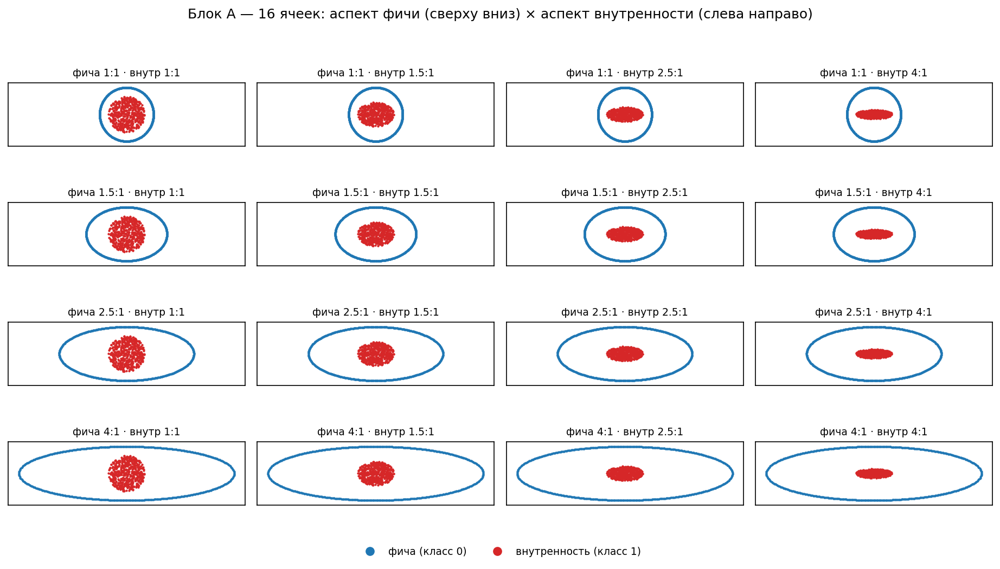

In [2]:
fig = gp.plot_cell_gallery(
    plan["A"],
    [f"фича {r.feature_aspect:g}:1 · внутр {r.interior_aspect:g}:1"
     for r in cells_meta.loc[plan["A"]].itertuples()],
    ncols=4,
    suptitle="Блок A — 16 ячеек: аспект фичи (сверху вниз) × аспект внутренности (слева направо)")
plt.show()

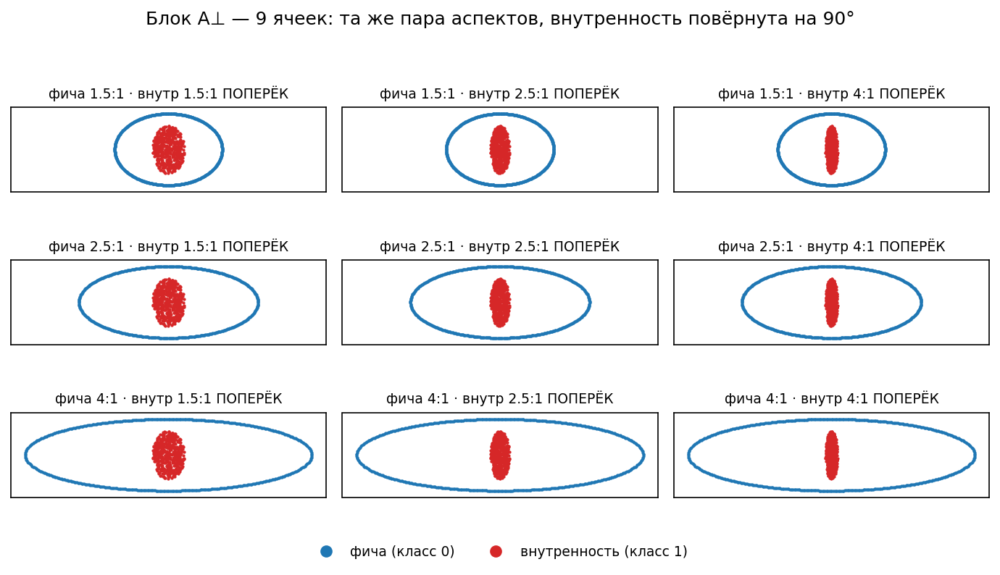

In [3]:
fig = gp.plot_cell_gallery(
    plan["A⊥"],
    [f"фича {r.feature_aspect:g}:1 · внутр {r.interior_aspect:g}:1 ПОПЕРЁК"
     for r in cells_meta.loc[plan["A⊥"]].itertuples()],
    ncols=3,
    suptitle="Блок A⊥ — 9 ячеек: та же пара аспектов, внутренность повёрнута на 90°")
plt.show()

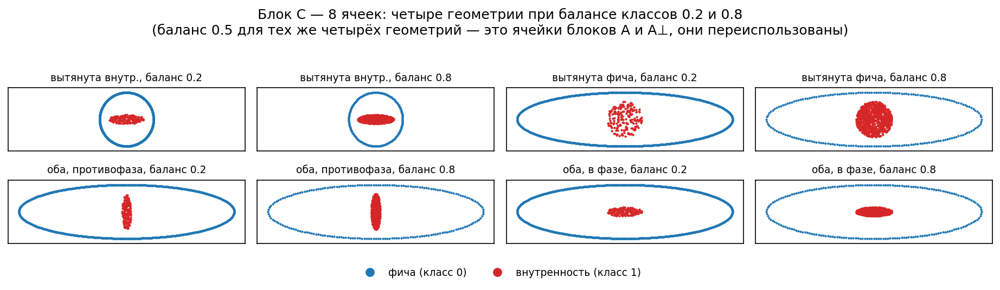

In [4]:
fig = gp.plot_cell_gallery(
    plan["C"],
    [f"{r.label}" for r in cells_meta.loc[plan["C"]].itertuples()],
    ncols=4,
    suptitle="Блок C — 8 ячеек: четыре геометрии при балансе классов 0.2 и 0.8\n"
             "(баланс 0.5 для тех же четырёх геометрий — это ячейки блоков A и A⊥, они переиспользованы)")
plt.show()

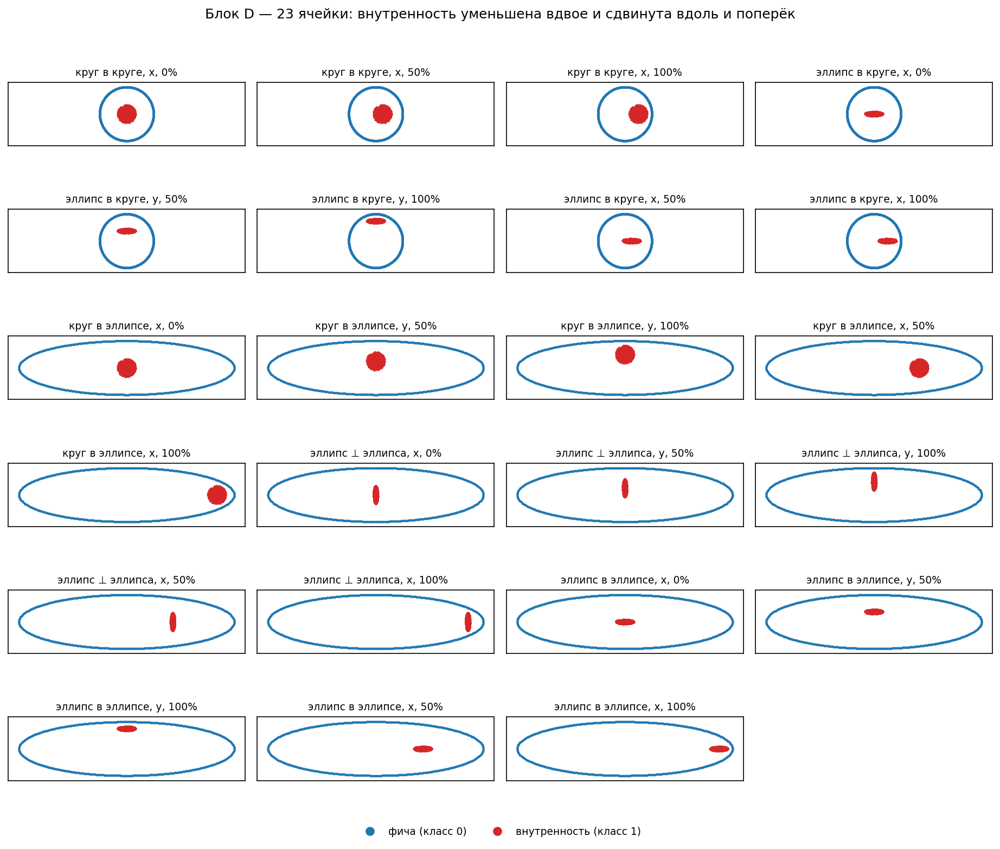

In [5]:
fig = gp.plot_cell_gallery(
    plan["D"],
    [f"{r.label}" for r in cells_meta.loc[plan["D"]].itertuples()],
    ncols=4,
    suptitle="Блок D — 23 ячейки: внутренность уменьшена вдвое и сдвинута вдоль и поперёк")
plt.show()

**Наблюдения.** Дизайн покрывает четыре независимые оси, и каждая ячейка отличается от соседней
ровно одним параметром. Видно и то, что стоит держать в голове дальше:

- в блоке A по диагонали (фича и внутренность одного аспекта) оба объекта **подобны**. Там
  вопрос «чью форму» не имеет ответа по построению, и λ обязана равняться 0.5. Это контроль, а
  не результат;
- вне диагонали объекты различаются по форме, и чем дальше от диагонали, тем сильнее;
- в блоке B диагональ перестаёт быть вырожденной: одинаковый аспект при развороте на 90° даёт
  **максимально** различающиеся объекты;
- в блоке D внутренность уменьшена вдвое — иначе ей некуда двигаться, оставаясь внутри фичи.


## 0.2 Якорь: детектор здесь тот же

Прежде чем читать любое падение доли свидетелей как факт о геометрии, надо убедиться, что
детектор не сломался по дороге. Ячейка «круг в круге» — это, с точностью до параметров, датасет
эксперимента 1: круглая фича, круглая внутренность, концентрично. Если детектор тот же, она
обязана воспроизвести его числа.

Ниже: сама ячейка вместе с её нулевыми размещениями (серые копии фичи, перенесённые в стороны —
это и есть контроль), затем распределение скоров лучшего нейрона у мишени против нулей.

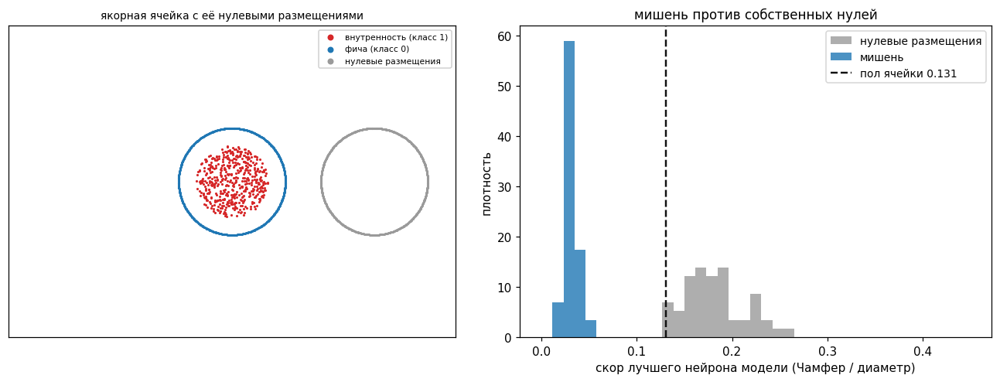

                       эксперимент 5   эксперимент 1
медиана лучшего               0.0299          0.0349
доля свидетелей                 1.00            0.98
p_superior                    1.0000          1.0000


In [6]:
ANCHOR = "g5_f010_i010_s100_o+0000+0000_b0500"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
gp.draw_cell(axes[0], ANCHOR, "якорная ячейка с её нулевыми размещениями",
             nulls=True, legend=True, half=gp.cells_extent([ANCHOR], nulls=True))

g = best[best.dataset_type == ANCHOR]
tgt, nul = g[g.feature_role == "target"]["score"], g[g.feature_role != "target"]["score"]
row = cells[cells.dataset_type == ANCHOR].iloc[0]
bins = np.linspace(0, 0.45, 40)
axes[1].hist(nul, bins=bins, color=gp.C_NULL, alpha=.8, density=True, label="нулевые размещения")
axes[1].hist(tgt, bins=bins, color=gp.C_FEATURE, alpha=.8, density=True, label="мишень")
axes[1].axvline(row.floor, color=gp.C_CURVE, ls="--", lw=1.6,
                label=f"пол ячейки {row.floor:.3f}")
axes[1].set_xlabel("скор лучшего нейрона модели (Чамфер / диаметр)")
axes[1].set_ylabel("плотность"); axes[1].legend(fontsize=9)
axes[1].set_title("мишень против собственных нулей", fontsize=11)
plt.tight_layout(); plt.show()

print(f"{'':22s}{'эксперимент 5':>14s}{'эксперимент 1':>16s}")
print(f"{'медиана лучшего':22s}{row.target_median:14.4f}{0.0349:16.4f}")
print(f"{'доля свидетелей':22s}{row.rate_floor:14.2f}{0.98:16.2f}")
print(f"{'p_superior':22s}{row.p_superior:14.4f}{1.0000:16.4f}")

**Наблюдения.** Медиана лучшего нейрона **0.0299** против 0.0349 в эксперименте 1, доля моделей
со свидетелем **1.00** против 0.98, `p_superior` = 1.0000 — распределения мишени и нулей не
пересекаются вовсе.

**Вывод.** Детектор на месте, и вырожденная точка экспериментов 1–2 воспроизведена внутри этого
эксперимента. Всё, что мы увидим дальше при отклонении от неё, — это факт о геометрии, а не о
сменившемся инструменте.

## 0.3 Порог нельзя унаследовать: у каждой ячейки свой пол

Скор нормируется на диаметр фичи. Диаметр здесь пробегает от 3 (круг) до 12 (эллипс 4:1), и это
значит, что одно и то же значение `τ = 0.1` соответствует допуску 0.3 единицы у круга и 1.2
единицы у вытянутой фичи. Порог, осмысленный в одной ячейке, в другой оказывается вчетверо мягче.

Правило, замороженное в эксперименте 4, отвечает на это так: **порог — перцентиль скоров
собственных нулевых размещений этой ячейки**, и здесь берётся **первый**: ложное срабатывание
дороже пропуска. Нуль — это конгруэнтная копия самой мишени,
перенесённая туда, где сеть её не решала; значит пол измеряет, насколько близко к мишени такой
формы можно подойти случайно.

Ниже — пол всех 56 ячеек, отсортированный, с `τ = 0.1` для сравнения. Число нулевых значений,
на которых он стоит, различается по ячейкам вчетверо (50 против 200), и при 50 первый
перцентиль есть почти минимум выборки — поэтому рядом печатается и пятый.

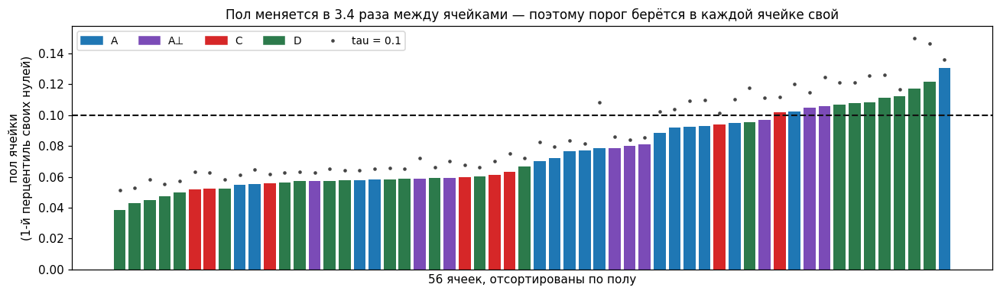

пол:  минимум 0.038   максимум 0.131   отношение 3.4
ячеек, где собственный пол ВЫШЕ tau=0.1: 12 из 56
ячеек, где НИЖЕ:                          44


In [7]:
fig = gp.plot_floor_bars(cells)
plt.show()

print(f"пол:  минимум {cells.floor.min():.3f}   максимум {cells.floor.max():.3f}   "
      f"отношение {cells.floor.max()/cells.floor.min():.1f}")
print(f"ячеек, где собственный пол ВЫШЕ tau=0.1: {(cells.floor > 0.1).sum()} из {len(cells)}")
print(f"ячеек, где НИЖЕ:                          {(cells.floor < 0.1).sum()}")

**Наблюдения.** Пол меняется от 0.038 до 0.131 — в 3.4 раза. В 12 ячейках он **выше** `τ = 0.1`,
то есть там нуль проходит порог экспериментов 1–2 и был бы засчитан свидетелем; в 44 — ниже.
При 5-м перцентиле пол идёт 0.052 … 0.150 и выше `τ` оказывается уже в 21 ячейке.

**Вывод.** Единого порога в этом эксперименте не существует, и это не техническая деталь, а
следствие того, что мы меняем саму мишень. Дальше везде доля свидетелей считается по
собственному полу ячейки, а `0.01` читается как уровень случайности — по определению правила,
а не как измеренная частота ошибок.

---
# 1. Инструмент: гармонический дескриптор формы

В этом эксперименте считаются три прибора. Два из них — **структурный** и **гомологический**
критерии — унаследованы от экспериментов 1, 2 и 4 и отвечают на вопрос «**совпала ли** линия
уровня с заданной мишенью». Для топологической релевантности этого достаточно, и они здесь нужны
ровно в двух ролях: сшивка с прежними экспериментами (те же числа на той же конфигурации) и
проверка исправности.

Но эксперимент 5 спрашивает другое: **какой формы** оказалась линия уровня и **чьей** формой она
является. На это ни один из двух ответить не может — они возвращают одно число «далеко или
близко», а форма при этом не измеряется вовсе. Поэтому здесь введён **третий** прибор,
гармонический дескриптор, и в этом эксперименте он главный: все геометрические выводы опираются
на него.

Раздел устроен так: сначала что дескриптор меряет (1.1) и как считается расстояние между формами
(1.2) — без этого числа дальше нечитаемы; затем его собственная точность и шкала задачи (1.3),
производная величина λ (1.4) и два способа выбрать уровни (1.5). После этого — что прибор видит
на настоящих данных: пять ступеней лестницы целиком (1.6) и развитие структуры по слоям
сети (1.7).

## 1.1 Что дескриптор меряет

Замкнутая кривая описывается своим **центроидом** и **радиальным профилем** — расстоянием от
центроида до кривой как функцией угла:

$$r(\theta) \;=\; r_0\Bigl(1 + \sum_{k\ge 1} a_k\cos\bigl(k(\theta - \varphi_k)\bigr)\Bigr).$$

Три части независимы и отвечают на три разных вопроса:

| часть | что это | вопрос |
|---|---|---|
| центроид | где кривая | **где** |
| `r₀` | средний радиус | **насколько велика** |
| `(aₖ, φₖ)` | спектр нормированного профиля | **какой формы** |

`r₀` вынесен за скобку, поэтому спектр **не зависит от размера**: окружности радиуса 1 и 5 имеют
один и тот же нулевой спектр. Это и делает спектр мерой формы.

Ниже — настоящая линия уровня настоящего нейрона, разобранная на эти три части.

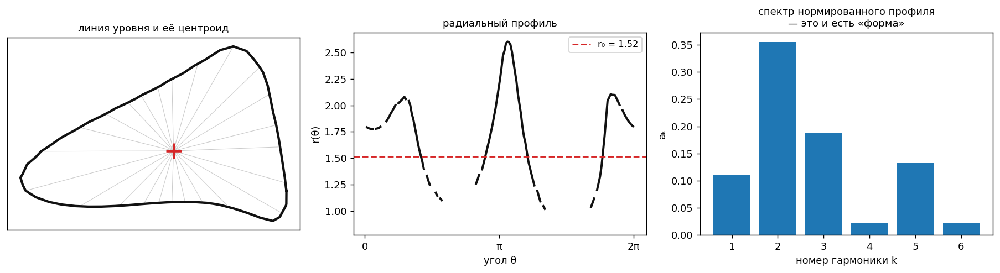

r₀ = 1.519   центроид = (-0.597, -0.312)
aₖ: a1 = 0.111  a2 = 0.355  a3 = 0.187  a4 = 0.021  a5 = 0.132  a6 = 0.022


In [8]:
import warnings
warnings.filterwarnings("ignore")
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import analysis.geometry_sweep as gs
import visualization.geometry_sweep_plots as gp
from analysis.shape_descriptors import (fourier_descriptor, shape_distance,
                                        radial_profile, SHAPE_ORDER)
from analysis.fields import evaluate_field_on_grid
from analysis.shape_descriptors import level_curves, enclosing_curve, densify

pd.set_option("display.width", 205)
plt.rcParams["figure.dpi"] = 130

ANCHOR = "g5_f010_i010_s100_o+0000+0000_b0500"
ELONG  = "g5_f040_i010_s100_o+0000+0000_b0500"

n = gs.best_neuron_of(best, ELONG, which="median")
L = gs.ladder_curves(ELONG, model_path=n["model_path"],
                     layer_id=n["layer_id"], coord_id=n["coord_id"])
curve = L["curves"][2]
d = fourier_descriptor(curve)
prof = radial_profile(curve)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
c = curve.numpy(); ctr = d["center"].numpy()
axes[0].plot(*np.vstack([c, c[:1]]).T, color=gp.C_CURVE, lw=2.4)
axes[0].plot(*ctr, "+", color=gp.C_INTERIOR, ms=15, mew=2.5)
for a in np.linspace(0, 2*np.pi, 25)[:-1]:
    j = int(np.argmin(np.abs(np.arctan2(*(c - ctr)[:, ::-1].T) % (2*np.pi) - a)))
    axes[0].plot([ctr[0], c[j, 0]], [ctr[1], c[j, 1]], color="#ccc", lw=.6, zorder=0)
axes[0].set_aspect("equal"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title("линия уровня и её центроид", fontsize=10)

th, r = prof["theta"].numpy(), prof["r"].numpy()
axes[1].plot(th, r, color=gp.C_CURVE, lw=2.2)
axes[1].axhline(d["r0"], color=gp.C_INTERIOR, ls="--", lw=1.6, label=f"r₀ = {d['r0']:.2f}")
axes[1].set_xlabel("угол θ"); axes[1].set_ylabel("r(θ)")
axes[1].set_xticks([0, np.pi, 2*np.pi], ["0", "π", "2π"])
axes[1].legend(fontsize=9); axes[1].set_title("радиальный профиль", fontsize=10)

ks = list(range(1, SHAPE_ORDER+1))
axes[2].bar(ks, [d["amplitude"][k] for k in ks], color=gp.C_FEATURE)
axes[2].set_xlabel("номер гармоники k"); axes[2].set_ylabel("aₖ")
axes[2].set_title("спектр нормированного профиля\n— это и есть «форма»", fontsize=10)
plt.tight_layout(); plt.show()

print(f"r₀ = {d['r0']:.3f}   центроид = ({ctr[0]:+.3f}, {ctr[1]:+.3f})")
print("aₖ: " + "  ".join(f"a{k} = {d['amplitude'][k]:.3f}" for k in ks))

**Наблюдения.** Профиль заметно непостоянен — форма не круглая. Но разложение показывает, что
«не круглая» устроено сложнее, чем «вытянутая»: помимо второй гармоники видны **нечётные** —
первая и третья, — которых у эллипса не бывает вовсе. Первая означает, что кривая не симметрична
относительно своего центроида, третья — что она слегка треугольная.

**Вывод.** Форма — вектор, а не число. Дальше это существенно: расстояние между формами считается
по всем гармоникам сразу.

## 1.2 Как считается расстояние между формами

Каждая гармоника даёт вектор на плоскости — амплитуду и фазу вместе:

$$u_k \;=\; a_k\bigl(\cos k\varphi_k,\ \sin k\varphi_k\bigr).$$

Расстояние между формами — евклидово расстояние между наборами таких векторов; по Парсевалю оно
равно L²-расстоянию между самими нормированными профилями:

$$d(A, B) \;=\; \sqrt{\tfrac12 \sum_{k=1}^{6} \lVert u_k - v_k\rVert^2}.$$

Фаза входит наравне с амплитудой, и это принципиально: эллипс вдоль оси x и такой же эллипс
поперёк имеют одинаковые амплитуды и противоположные фазы, и расстояние между ними максимально.
Без фазы блок B был бы неотличим от блока A.

Ниже разобран **один конкретный случай** — линия уровня из 1.1 против своей фичи, — чтобы было
видно, из чего складывается число. Доли гармоник у другой пары кривых будут другими; смысл
примера не в конкретных процентах, а в том, что вклад даёт не одна гармоника.


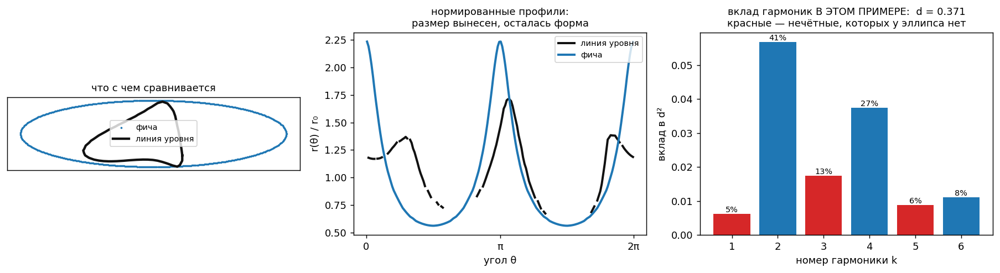

  k   вклад в d²    доля   aₖ кривой   aₖ фичи
  1      0.00621    4.5%       0.111     0.000
  2      0.05682   41.2%       0.355     0.633
  3      0.01751   12.7%       0.187     0.000
  4      0.03746   27.2%       0.021     0.290
  5      0.00874    6.3%       0.132     0.000
  6      0.01112    8.1%       0.022     0.145

d = sqrt(0.13787) = 0.3713
если бы считали только по a₂: 0.2782


In [9]:
dcur, dfea = fourier_descriptor(curve), fourier_descriptor(L["feature"])
terms = gs.harmonic_terms(dcur, dfea)
total = sum(terms)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
f = L["feature"].numpy()
axes[0].scatter(f[:, 0], f[:, 1], s=1.1, color=gp.C_FEATURE, label="фича")
axes[0].plot(*np.vstack([c, c[:1]]).T, color=gp.C_CURVE, lw=2.4, label="линия уровня")
axes[0].set_aspect("equal"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].legend(fontsize=8); axes[0].set_title("что с чем сравнивается", fontsize=10)

pf = radial_profile(L["feature"])
axes[1].plot(prof["theta"], prof["r"]/dcur["r0"], color=gp.C_CURVE, lw=2.2, label="линия уровня")
axes[1].plot(pf["theta"], pf["r"]/dfea["r0"], color=gp.C_FEATURE, lw=2.2, label="фича")
axes[1].set_xticks([0, np.pi, 2*np.pi], ["0", "π", "2π"])
axes[1].set_xlabel("угол θ"); axes[1].set_ylabel("r(θ) / r₀"); axes[1].legend(fontsize=8)
axes[1].set_title("нормированные профили:\nразмер вынесен, осталась форма", fontsize=10)

axes[2].bar(ks, terms, color=[gp.C_FEATURE if k % 2 == 0 else gp.C_INTERIOR for k in ks])
for k, tt in zip(ks, terms):
    axes[2].text(k, tt, f"{100*tt/total:.0f}%", ha="center", va="bottom", fontsize=8)
axes[2].set_xlabel("номер гармоники k"); axes[2].set_ylabel("вклад в d²")
axes[2].set_title(f"вклад гармоник В ЭТОМ ПРИМЕРЕ:  d = {math.sqrt(total):.3f}\n"
                  "красные — нечётные, которых у эллипса нет", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'k':>3}{'вклад в d²':>13}{'доля':>8}{'aₖ кривой':>12}{'aₖ фичи':>10}")
for k, tt in zip(ks, terms):
    print(f"{k:3d}{tt:13.5f}{100*tt/total:7.1f}%{dcur['amplitude'][k]:12.3f}{dfea['amplitude'][k]:10.3f}")
print(f"\nd = sqrt({total:.5f}) = {math.sqrt(total):.4f}")
print(f"если бы считали только по a₂: {abs(dcur['amplitude'][2]-dfea['amplitude'][2]):.4f}")

**Наблюдения.** В этом примере вторая гармоника даёт 42 % квадрата расстояния, четвёртая — 29 %
(у эллипса 4:1 `a₄ = 0.29`, он сильно не синусоидален), нечётные — 22 %: у эллипса их нет вовсе,
а у настоящей линии уровня есть. Счёт «по разнице вторых гармоник» дал бы 0.2755 вместо 0.3724.

**Вывод.** Расстояние формы — не «разница вытянутостей»: оно складывается из шести слагаемых, и
какое из них главное, зависит от пары кривых. Поэтому дальше везде приводится расстояние
целиком; `a₂` используется отдельно и только там, где его переводят в аспект для наглядности.

## 1.3 Собственная точность прибора и шкала задачи

Это **две разные вещи**, и их легко перепутать.

**Точность прибора** — насколько верно он описывает кривую. Линия уровня извлекается с конечной
сетки, поэтому её спектр несёт дискретизационную ошибку. Измеряется она так:

1. берём поле, у которого линии уровня известны **точно**: `f(x,y) = √((x/a)² + (y/b)²)`, у
   которого уровень `c` — это в точности эллипс с полуосями `ca, cb`;
2. считаем это поле на сетке заданного шага `h`;
3. извлекаем линию уровня **тем же кодом**, что и в эксперименте: marching squares → выбор
   охватывающей кривой → уплотнение с шагом `h/2`;
4. считаем её дескриптор и сравниваем с аналитическим дескриптором точного эллипса;
5. разность и есть ошибка прибора. Меняя `h`, получаем её как функцию от `r₀/h` — числа шагов
   сетки на средний радиус кривой.

**Шкала задачи** — насколько крупные различия эксперимент вообще спрашивает. Она задана
дизайном: сетка аспектов 1 / 1.5 / 2.5 / 4, и наименьший её шаг — круг против 1.5:1 — равен
**0.144**. Это **не** разрешение прибора и ничего не говорит о том, сколь мелкие изменения он
способен зарегистрировать; это шаг, который выбрали мы.

Смысл имеет только их **отношение**: годен ли прибор для той шкалы, которую спрашивает дизайн.

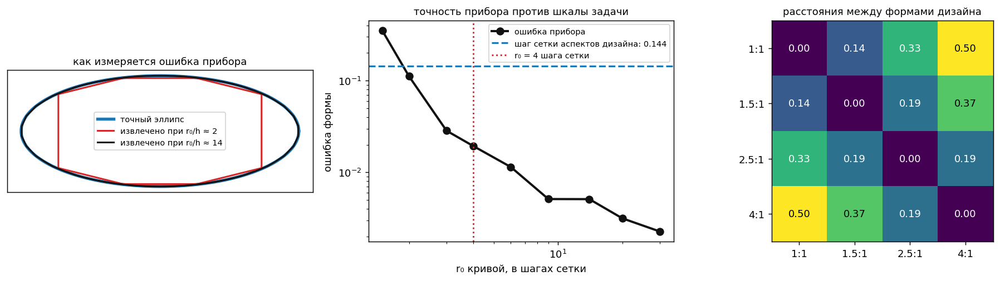

ошибка прибора:  r₀/h=1.5: 0.3498   r₀/h=2: 0.1114   r₀/h=3: 0.0284   r₀/h=4: 0.0194   r₀/h=6: 0.0114   r₀/h=9: 0.0051   r₀/h=14: 0.0051   r₀/h=20: 0.0032   r₀/h=30: 0.0023

шаг сетки аспектов дизайна: 0.144 (круг против 1.5:1); крайние формы — 0.503


In [10]:
aspects = (1.0, 1.5, 2.5, 4.0)
th_ = torch.linspace(0, 2*math.pi, 2001)[:-1]
ref = {a: fourier_descriptor(torch.stack([a*torch.cos(th_), torch.sin(th_)], 1)) for a in aspects}

ratios = [1.5, 2, 3, 4, 6, 9, 14, 20, 30]
errs, demo = [], {}
a_e, b_e = 1.0, 1.0/2.5
exact = torch.stack([a_e*torch.cos(th_), b_e*torch.sin(th_)], 1)
for ratio in ratios:
    res = int(round(8*ratio))
    fld = evaluate_field_on_grid(lambda p: torch.sqrt((p[:,0]/a_e)**2 + (p[:,1]/b_e)**2),
                                 [(-4, 4)]*2, res)
    cu = enclosing_curve(level_curves(fld, 1.0), torch.zeros(2))
    if cu is None:
        errs.append(np.nan); continue
    cu = densify(cu, .5*fld.grid_step)
    errs.append(shape_distance(fourier_descriptor(cu), fourier_descriptor(exact)))
    if ratio in (2, 14):
        demo[ratio] = cu.numpy()

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0))
axes[0].plot(*exact.numpy().T, color=gp.C_FEATURE, lw=3, label="точный эллипс")
for ratio, col in zip((2, 14), [gp.C_INTERIOR, gp.C_CURVE]):
    dd = demo[ratio]
    axes[0].plot(*np.vstack([dd, dd[:1]]).T, lw=1.7, color=col,
                 label=f"извлечено при r₀/h ≈ {ratio}")
axes[0].set_aspect("equal"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].legend(fontsize=8); axes[0].set_title("как измеряется ошибка прибора", fontsize=10)

axes[1].loglog(ratios, errs, "o-", color=gp.C_CURVE, lw=2.2, ms=7, label="ошибка прибора")
axes[1].axhline(0.144, color=gp.C_FEATURE, ls="--", lw=1.8,
                label="шаг сетки аспектов дизайна: 0.144")
axes[1].axvline(4, color=gp.C_INTERIOR, ls=":", lw=1.6, label="r₀ = 4 шага сетки")
axes[1].set_xlabel("r₀ кривой, в шагах сетки"); axes[1].set_ylabel("ошибка формы")
axes[1].legend(fontsize=8); axes[1].set_title("точность прибора против шкалы задачи", fontsize=10)

M = np.array([[shape_distance(ref[x], ref[y]) for y in aspects] for x in aspects])
im = axes[2].imshow(M, cmap="viridis")
axes[2].set_xticks(range(4), [f"{a:g}:1" for a in aspects])
axes[2].set_yticks(range(4), [f"{a:g}:1" for a in aspects])
for i in range(4):
    for j in range(4):
        axes[2].text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=10,
                     color="white" if M[i,j] < .35 else "black")
axes[2].set_title("расстояния между формами дизайна", fontsize=10)
plt.tight_layout(); plt.show()

print("ошибка прибора:  " + "   ".join(f"r₀/h={r}: {e:.4f}" for r, e in zip(ratios, errs) if e == e))
print(f"\nшаг сетки аспектов дизайна: 0.144 (круг против 1.5:1); крайние формы — 0.503")

**Наблюдения.** Ошибка прибора падает как `1/(r₀/h)`: 0.05 при полутора шагах сетки на радиус,
**0.010** при четырёх, 0.002 при двадцати. Шаг сетки аспектов дизайна — 0.144.

**Вывод.** При `r₀ ≥ 4` шага сетки прибор ошибается в **четырнадцать раз** меньше, чем
наименьшее различие, которое спрашивает дизайн. Условие `r₀ ≥ 4h` в основных разделах выполняется
везде, кроме нижней ступени лестницы в части ячеек блока D, и там оно оговаривается отдельно.

## 1.4 λ: чью форму несёт кривая

Расстояние безадресно: 0.37 — далеко от чего? Поэтому основная величина эксперимента
относительная:

$$\lambda \;=\; \frac{d_{\text{feat}}}{d_{\text{feat}} + d_{\text{int}}},\qquad
\lambda = 0 \Rightarrow \text{форма фичи},\qquad
\lambda = 1 \Rightarrow \text{форма внутренности}.$$

У λ есть одна вырожденность: **если у двух объектов одна форма, вопрос не имеет ответа** —
числитель и знаменатель отличаются лишь на шум, и λ выходит 0.5 при любой кривой. Порог здесь
задаёт **точность прибора**: пока `objects_shape` сравнимо с 0.01, λ есть отношение двух шумов.

Отдельно от этого дизайн содержит ячейки, где объекты подобны **по построению** — диагональ
блока A. Там `objects_shape` равно нулю не приближённо, а тождественно, и λ ≡ 0.5 не потому, что
прибор не справился, а потому, что вопрос не задан. Такие ячейки дальше всегда помечаются и в
средние не входят.

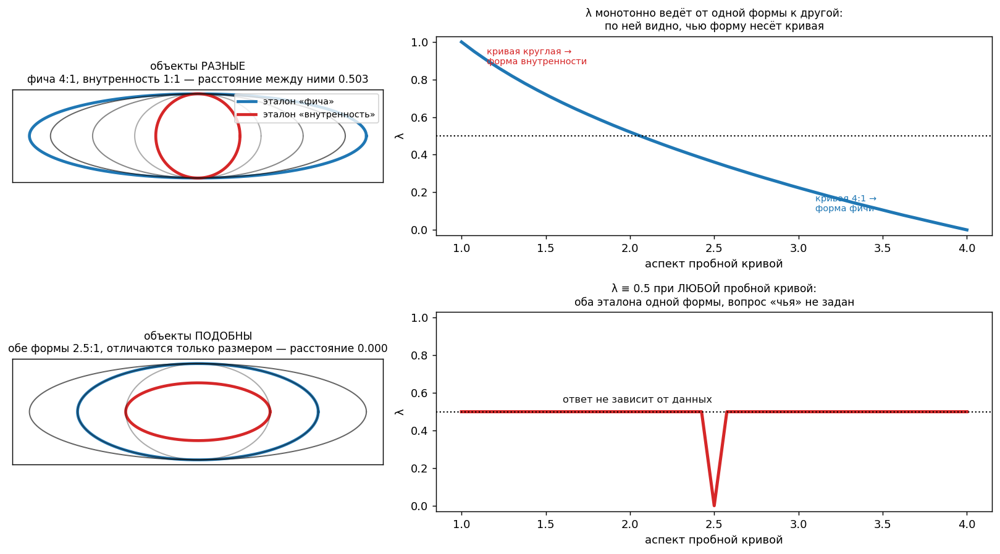

ячеек, где объекты подобны по построению (objects_shape < 0.01): 14 из 56
  их медианная λ: 0.500  (обязана быть 0.5)
  медианная λ в остальных: 0.569


In [11]:
fea, inte = ref[4.0], ref[1.0]
asps = np.linspace(1.0, 4.0, 41)
# вырожденный случай: два ПОДОБНЫХ объекта — эллипсы 2.5:1 разного размера
f2 = fourier_descriptor(torch.stack([2.5*torch.cos(th_), torch.sin(th_)], 1))
i2 = fourier_descriptor(torch.stack([2.5*.6*torch.cos(th_), .6*torch.sin(th_)], 1))
lam_ok, lam_deg = [], []
for asp in asps:
    cu = fourier_descriptor(torch.stack([asp*torch.cos(th_), torch.sin(th_)], 1))
    d1, d2 = shape_distance(cu, fea), shape_distance(cu, inte)
    lam_ok.append(d1/(d1+d2))
    e1, e2 = shape_distance(cu, f2), shape_distance(cu, i2)
    lam_deg.append(e1/(e1+e2) if (e1+e2) > 1e-9 else np.nan)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0),
                         gridspec_kw={"width_ratios": [1, 1.5]})
for row, (fo, io, lam, ttl, sub) in enumerate([
        ((4.0, 1.0), (1.0, 1.0), lam_ok, "объекты РАЗНЫЕ",
         "фича 4:1, внутренность 1:1 — расстояние между ними 0.503"),
        ((2.5, 1.0), (2.5*.6, .6), lam_deg, "объекты ПОДОБНЫ",
         "обе формы 2.5:1, отличаются только размером — расстояние 0.000")]):
    ax = axes[row][0]
    ax.plot(fo[0]*np.cos(th_.numpy()), fo[1]*np.sin(th_.numpy()),
            color=gp.C_FEATURE, lw=2.6, label="эталон «фича»")
    ax.plot(io[0]*np.cos(th_.numpy()), io[1]*np.sin(th_.numpy()),
            color=gp.C_INTERIOR, lw=2.6, label="эталон «внутренность»")
    for a, al in zip((1.5, 2.5, 3.5), (.35, .5, .65)):
        ax.plot(a*np.cos(th_.numpy()), np.sin(th_.numpy()), color=gp.C_CURVE,
                lw=1.1, alpha=al)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{ttl}\n{sub}", fontsize=9.5)
    if row == 0:
        ax.legend(fontsize=8, loc="upper right")
        ax.plot([], [], color=gp.C_CURVE, lw=1.1, label="пробные кривые")

    ax = axes[row][1]
    ax.plot(asps, lam, lw=2.8, color=gp.C_FEATURE if row == 0 else gp.C_INTERIOR)
    ax.axhline(.5, color="k", ls=":", lw=1.2)
    ax.set_ylim(-.03, 1.03); ax.set_ylabel("λ"); ax.set_xlabel("аспект пробной кривой")
    if row == 0:
        ax.set_title("λ монотонно ведёт от одной формы к другой:\n"
                     "по ней видно, чью форму несёт кривая", fontsize=9.5)
        ax.annotate("кривая круглая →\nформа внутренности", (1.15, .88), fontsize=8,
                    color=gp.C_INTERIOR)
        ax.annotate("кривая 4:1 →\nформа фичи", (3.1, .10), fontsize=8, color=gp.C_FEATURE)
    else:
        ax.set_title("λ ≡ 0.5 при ЛЮБОЙ пробной кривой:\n"
                     "оба эталона одной формы, вопрос «чья» не задан", fontsize=9.5)
        ax.annotate("ответ не зависит от данных", (1.6, .55), fontsize=9, color=gp.C_CURVE)
plt.tight_layout(); plt.show()

lv = gs.ladder_long(df, "value")
sh = gs.shape_by_cell(lv); midd = sh[sh.rung == 2]
deg = midd[midd.objects_shape < 0.01]
print(f"ячеек, где объекты подобны по построению (objects_shape < 0.01): "
      f"{len(deg)} из {midd.dataset_type.nunique()}")
print(f"  их медианная λ: {deg.lam.median():.3f}  (обязана быть 0.5)")
print(f"  медианная λ в остальных: {midd[midd.objects_shape >= 0.01].lam.median():.3f}")

**Наблюдения.** Когда объекты различаются, λ монотонно ведёт от 1 к 0 по мере того, как пробная
кривая переходит от формы внутренности к форме фичи. Когда объекты подобны, λ равна 0.5 при любой
кривой. В посчитанных данных вырожденных ячеек ровно столько, сколько предсказывает геометрия, и
их медианная λ действительно 0.500.

**Вывод.** λ читается только вместе с `objects_shape` своей ячейки, и вырожденные ячейки —
диагональ блока A — служат контролем исправности, а не результатом.

## 1.5 Два способа выбрать уровни

У нейрона не одна линия уровня, а семейство — по одной на каждое значение `c`. Выбирать уровень
по критерию нельзя: если брать тот, что ближе всего к фиче, ответ «кривая похожа на фичу»
получится по построению. Нужны правила, симметричные по обоим объектам, и их два — по разным
сторонам одного и того же отображения `уровень ↦ кривая`.

**По значению поля (кодомейн).** Пять значений, разложенных равномерно между средним значением
поля **на границе внутренности** и средним значением **на фиче**. Оба якоря — средние поля по
точкам объекта, поэтому правило не знает ни про форму, ни про размер: оно знает только, что
объектов два.

**По радиусу (домейн).** Пять целевых радиусов, разложенных равномерно между `r₀` внутренности и
`r₀` фичи. Слово «обращение» здесь прячет алгоритм, поэтому он выписан (это `spatial_ladder`,
и так же считал серверный прогон):

1. **зондирование** — 13 пробных уровней, равномерно на том же отрезке значений, что у первой
   лестницы. Сами эти кривые никуда не идут, они нужны только чтобы узнать связь уровня и радиуса
   у данного нейрона;
2. на каждом зонде берётся замкнутый контур, охватывающий **центроид внутренности**, и его `r₀`
   считается вокруг **его собственного** центроида — иначе смещение подмешивалось бы в размер;
3. полученная таблица «уровень → `r₀`» проверяется на **монотонность** (флаг возвращается вместе
   с лестницей, монотонна она у 52 % нейронов);
4. для каждого целевого радиуса уровень находится линейной интерполяцией по этой таблице.

Целевые радиусы **не подгоняются** под то, что нейрон достаёт: недостижимый радиус возвращается
пропуском. Подгонка сохранила бы все пять ступеней заполненными ценой общего кадра, ради которого
конструкция и делается.

Оба правила дают **общий кадр**, просто в разных пространствах: у первого «ступень 3» означает
одну и ту же долю пройденного диапазона **значений поля** у любого нейрона, у второго — одно и то
же место **в пространстве**. Сравнивать нейроны между собой позволяют оба; вопрос лишь в том, по
какой координате их выравнивать.

Мотивация в пользу кодомейна, и это именно мотивация, а не строгий довод. Равные шаги по значению
кладут линии уровня **гуще там, где поле круче**: где `f` меняется быстро, соседние уровни близки
и в пространстве. Крутизна — это место «складки» поля, зона перехода от одного класса к другому,
то есть та область, на которую нейрон и реагирует. Лестница по значению сама сгущает выборку
туда; лестница по радиусу раскладывает её равномерно по пространству безотносительно к тому, где
у поля что-то происходит.

Плата за кодомейн — неравномерность в пространстве; плата за домейн — отображение `c ↦ r₀`
обязано быть монотонным, чтобы его обратить, а это верно лишь у 52 % нейронов.

**Дальше в разделах 2–D анализируется лестница по значению**, а лестница по радиусу служит
проверкой на устойчивость там, где она заполнена. Причина не принципиальная, а практическая:
по значению ступень есть всегда, и терять половину нейронов на требовании монотонности незачем.

Ниже обе лестницы построены **для одного и того же нейрона**, чтобы разница была видна не на
словах. Под кривыми — **поле самого нейрона**: без него кривая выглядит фигурой из ниоткуда, а с
ним видно, лежит ли она на складке поля или посреди плато. Цвет фона — ранг значения, а не само
значение: `tanh` насыщается, и при равномерной шкале почти весь кадр закрашивается одним тоном,
а вся геометрия сидит в узкой переходной зоне. Уровни фона поэтому расставлены по квантилям
значений в окне — там, где цвет меняется быстро, поле и есть крутое.

Третья панель — то самое отображение `c ↦ r₀`, снятое по 61 пробному уровню (зондов в самой
лестнице 13; здесь их больше, чтобы кривая была гладкой): по нему видно сразу и как работают обе
лестницы, и почему у второй ступени иногда не находится.

**Про шкалу цвета — и почему фон местами почти однотонный.** У этого нейрона в показанном окне
**84 % узлов сетки имеют |f| > 0.9**, а 53 % — |f| > 0.99: `tanh` насыщен, и почти весь кадр
занят двумя плато, между которыми лежит узкая складка. Внутрь диапазона лестницы попадает лишь
**16.5 %** узлов. То есть однотонность на широких ячейках — свойство самого нейрона, а не общей
палитры: палитра подбирается **по каждому нейрону отдельно**, по значениям внутри показанного
окна.

Уровни цвета расставлены **по квантилям** этих значений. Это делает видимой и складку, и слабый
рельеф на плато — тонкие линии по краям кадра суть настоящие линии уровня того же поля, просто
там оно почти постоянно. Цена — цвет читается как ранг значения, а не как само значение; сами
значения несут пять выделенных кривых, они подписаны уровнями лестницы.

Третья панель — то самое отображение `c ↦ r₀`, снятое по 61 пробному уровню (зондов в самой
лестнице 13; здесь их больше, чтобы кривая была гладкой): по нему видно сразу и как работают обе
лестницы, и почему у второй ступени иногда не находится.

**Про шкалу цвета — она выбрана не на глаз.** У этого нейрона в показанном окне **84 % узлов
сетки имеют |f| > 0.9**, а 53 % — |f| > 0.99: `tanh` насыщен, и почти весь кадр занят двумя плато,
между которыми лежит узкая складка. Внутрь диапазона лестницы попадает лишь **16.5 %** узлов.
Поэтому цвет привязан к **диапазону самой лестницы**: вся палитра достаётся складке, а оба плато
красятся крайними цветами. Ранговая шкала (по квантилям значений) делает ровно наоборот — отдаёт
большую часть цветов плато, где ничего не происходит, и рисует там паутину ложных линий. Так что
однотонность на широких ячейках — это свойство нейрона, а не палитры: палитра подбирается **по
каждому нейрону отдельно**.


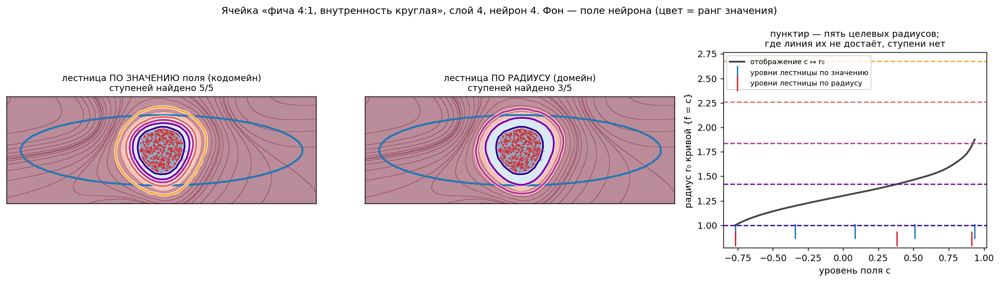

лестница ПО ЗНАЧЕНИЮ поля (кодомейн)       радиусы [1.0, 1.2, 1.33, 1.47, 1.88]
лестница ПО РАДИУСУ (домейн)               радиусы [1.0, 1.42, 1.81, None, None]
целевые радиусы лестницы по радиусу        [1.0, 1.42, 1.84, 2.26, 2.68]
узлов сетки в окне                         1180; |f| > 0.9 у 87%, внутри диапазона лестницы 13%
достижимые радиусы этого нейрона           [1.00 … 1.88]  (по 61 пробному уровню)


In [12]:
from analysis.shape_descriptors import spatial_ladder, level_ladder

# Нейрон найден перебором: у него две лестницы расходятся сильнее всего
# (радиусы 0.78…1.88 против 1.00…2.68), то есть разница видна, а не подразумевается.
demo = {"cell": "g5_f040_i010_s100_o+0000+0000_b0500", "layer": 4, "coord": 4,
        "model_index": 1}

rec = PLAN[demo["cell"]]
X, y, A_pts = gs.dataset_points(demo["cell"])[:3]
centre = torch.tensor(rec["interior"]["offset"], dtype=torch.float32)
bnd = gs._interior_boundary(rec["interior"])          # якорь лестницы — граница, не облако
fld, _, _ = gs.neuron_field(demo["cell"], model_index=demo["model_index"],
                            layer_id=demo["layer"], coord_id=demo["coord"])
step = .5*float(fld.grid_step)

r0i, r0f = fourier_descriptor(bnd)["r0"], fourier_descriptor(A_pts)["r0"]
lev_v = level_ladder(fld, A_pts, bnd, n_steps=5)
sp = spatial_ladder(fld, centre, r0i, r0f, (float(lev_v[0]), float(lev_v[-1])),
                    n_steps=5, curve_step=step)
targets = np.linspace(r0i, r0f, 5)                     # куда целится лестница по радиусу

def curves_at(levels):
    out = []
    for c in levels:
        if c != c:
            out.append(None); continue
        cu = enclosing_curve(level_curves(fld, float(c)), centre)
        out.append(None if cu is None else densify(cu, step))
    return out

hx, hy = gp.cells_extent([demo["cell"]])
_all = [c for c in curves_at(lev_v) + curves_at(sp["levels"]) if c is not None]
hy = max(hy, max(float(c[:, 1].abs().max()) for c in _all)) * 1.18   # кривые целиком в кадре
vrange = (float(lev_v[0]), float(lev_v[-1]))                         # шкала цвета = лестница
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4),
                         gridspec_kw={"width_ratios": [1, 1, .85]})
radii = {}
for ax, (levels, ttl) in zip(axes[:2], [(lev_v, "лестница ПО ЗНАЧЕНИЮ поля (кодомейн)"),
                                        (sp["levels"], "лестница ПО РАДИУСУ (домейн)")]):
    gp.field_background(ax, fld, window=(hx, hy), alpha=.45, levels=21)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=1.3, c=gp.C_INTERIOR, alpha=.65, zorder=1)
    ax.scatter(A_pts[:, 0], A_pts[:, 1], s=1.5, c=gp.C_FEATURE, zorder=2)
    rr = []
    for j, cu in enumerate(curves_at(levels)):
        if cu is None:
            rr.append(np.nan); continue
        gp.draw_curve(ax, cu.numpy(), ramp[j], lw=2.1, zorder=3+j)
        rr.append(fourier_descriptor(cu)["r0"])
    radii[ttl] = rr
    got = sum(r == r for r in rr)
    ax.set_xlim(-hx, hx); ax.set_ylim(-hy, hy)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{ttl}\nступеней найдено {got}/5", fontsize=10)

probe = torch.linspace(float(lev_v[0]), float(lev_v[-1]), 61)
prof = []
for c in probe:
    cu = enclosing_curve(level_curves(fld, float(c)), centre)
    prof.append((float(c), np.nan if cu is None
                 else fourier_descriptor(densify(cu, step))["r0"]))
axes[2].plot([p[0] for p in prof], [p[1] for p in prof], lw=2.0, c="#444",
             label="отображение c ↦ r₀")
for j, tr in enumerate(targets):
    axes[2].axhline(tr, color=ramp[j], ls="--", lw=1.4)
axes[2].scatter([float(v) for v in lev_v], [r0i-.06]*5, marker="|", s=260,
                c=gp.C_FEATURE, label="уровни лестницы по значению")
axes[2].scatter([float(v) for v in sp["levels"] if v == v],
                [r0i-.14]*int(sum(v == v for v in sp["levels"])), marker="|", s=260,
                c=gp.C_INTERIOR, label="уровни лестницы по радиусу")
axes[2].set_xlabel("уровень поля c"); axes[2].set_ylabel("радиус r₀ кривой {f = c}")
axes[2].legend(fontsize=8, loc="upper left")
axes[2].set_title("пунктир — пять целевых радиусов;\n"
                  "где линия их не достаёт, ступени нет", fontsize=10)
fig.suptitle(f"Ячейка «фича 4:1, внутренность круглая», слой {demo['layer']}, "
             f"нейрон {demo['coord']}. Фон — поле нейрона (цвет = ранг значения)",
             fontsize=11)
plt.tight_layout(); plt.show()

for ttl, rr in radii.items():
    print(f"{ttl:42s} радиусы {[round(x,2) if x==x else None for x in rr]}")
print(f"{'целевые радиусы лестницы по радиусу':42s} "
      f"{[round(float(t),2) for t in targets]}")
ins = (np.abs(fld.points_nd.numpy()[..., 0]) <= hx) & (np.abs(fld.points_nd.numpy()[..., 1]) <= hy)
vw = fld.values_nd.numpy()[ins]
print(f"{'узлов сетки в окне':42s} {vw.size}; |f| > 0.9 у {(np.abs(vw) > .9).mean():.0%}, "
      f"внутри диапазона лестницы {((vw >= vrange[0]) & (vw <= vrange[1])).mean():.0%}")
reach = [p[1] for p in prof if p[1] == p[1]]
print(f"{'достижимые радиусы этого нейрона':42s} "
      f"[{min(reach):.2f} … {max(reach):.2f}]  (по 61 пробному уровню)")


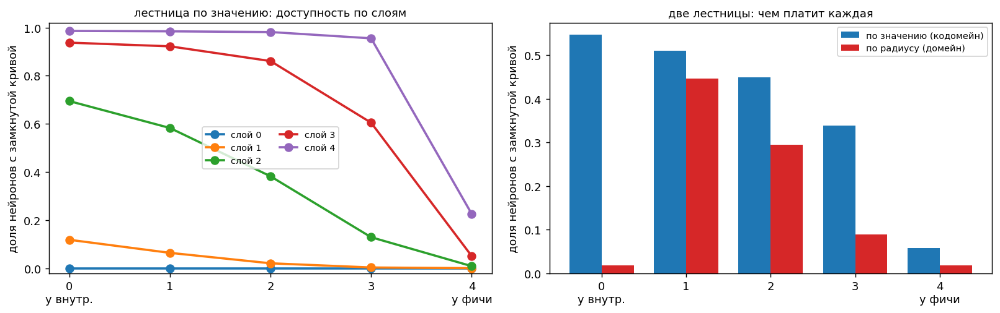

доступность ступеней (все слои):
      по значению  по радиусу
rung                         
0           0.547       0.019
1           0.511       0.447
2           0.449       0.295
3           0.339       0.088
4           0.057       0.017

отображение уровень -> радиус монотонно у 52% нейронов


In [13]:
lr = gs.ladder_long(df, "radial")
av_v = lv.assign(есть=lambda d: d.dfeat.notna()).pivot_table(
    index="layer_id", columns="rung", values="есть", aggfunc="mean")
per_rung = pd.DataFrame({
    "по значению": lv.assign(e=lambda d: d.dfeat.notna()).groupby("rung").e.mean(),
    "по радиусу":  lr.assign(e=lambda d: d.dfeat.notna()).groupby("rung").e.mean()})

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
for layer in sorted(av_v.index):
    axes[0].plot(av_v.columns, av_v.loc[layer], "o-", lw=2, ms=7, label=f"слой {layer}")
axes[0].set_xticks(range(5), ["0\nу внутр.", "1", "2", "3", "4\nу фичи"])
axes[0].set_ylabel("доля нейронов с замкнутой кривой"); axes[0].set_ylim(-.02, 1.02)
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_title("лестница по значению: доступность по слоям", fontsize=10)

w = .38; x = np.arange(5)
axes[1].bar(x - w/2, per_rung["по значению"], w, color=gp.C_FEATURE, label="по значению (кодомейн)")
axes[1].bar(x + w/2, per_rung["по радиусу"], w, color=gp.C_INTERIOR, label="по радиусу (домейн)")
axes[1].set_xticks(x, ["0\nу внутр.", "1", "2", "3", "4\nу фичи"])
axes[1].set_ylabel("доля нейронов с замкнутой кривой"); axes[1].legend(fontsize=8)
axes[1].set_title("две лестницы: чем платит каждая", fontsize=10)
plt.tight_layout(); plt.show()

print("доступность ступеней (все слои):")
print(per_rung.round(3).to_string())
t = df[df.feature_role == "target"]
print(f"\nотображение уровень -> радиус монотонно у {t.harmonic_monotone.mean():.0%} нейронов")

**Наблюдения.**

- **Две лестницы кладут кривые в разные места.** У показанного нейрона лестница по значению даёт
  радиусы 1.00 · 1.20 · 1.33 · 1.47 · 1.88, а лестница по радиусу целится в 1.00 · 1.42 · 1.84 ·
  2.26 · 2.68 и находит только первые три.
- **Правая панель говорит, почему.** Отображение `c ↦ r₀` этого нейрона упирается в 1.88: кривой
  радиуса 2.26 у его семейства попросту нет. Прибор возвращает пропуск, а не подставляет ближайшую
  из существующих, — и это правильное поведение, иначе «ступень 4» означала бы у разных нейронов
  разное.
- **Пропуски у двух лестниц означают разное.** У лестницы по радиусу пропуск — это «такого радиуса
  не существует». У лестницы по значению уровень существует всегда, и пропуск означает, что
  контур на нём **не замкнут вокруг внутренности**: он либо распадается на куски, либо упирается
  в край окна вычисления и обрывается. Проверка на этом же нейроне: на ступени 4 контуров два,
  замкнут один, край окна задевает один.
- **Доступность ступеней (блок A, слои > 0).** По значению: 0.68 · 0.64 · 0.59 · 0.48 · **0.10**.
  По радиусу: 0.04 · 0.64 · 0.50 · 0.19 · 0.05 — внутренняя ступень у неё почти пуста по той же
  причине, по которой у показанного нейрона пуста внешняя: радиус `r₀` внутренности лежит ниже
  того, что семейство достаёт.
- **Внешняя ступень тает вместе с вытянутостью фичи**: 0.164 · 0.130 · 0.052 · **0.042** по ряду
  1 : 1.5 : 2.5 : 4. Внутренняя при этом не тает вовсе (0.64 · 0.68 · 0.71 · 0.69). Значит
  выводы про вытянутые ячейки опираются на ступени 0–3, и это надо держать в голове: там, где
  фича вытянута, самая внешняя кривая чаще всего просто не существует.
- **И это не прячет эффекта.** Прямая проверка на 1558 нейронах блока A, у которых есть **обе**
  крайние ступени: расстояние формы до фичи на внутренней ступени 0.099, на внешней 0.129, и лишь
  у 21 % внешняя ступень оказывается к фиче ближе. То есть недостающие внешние ступени не
  скрывают режим «дальше кривая становится фичей»; там, где обе ступени есть, к фиче ближе
  внутренняя.

**Вывод.** Смотреть надо на **все ступени сразу** — это и есть содержание величины: как форма
ведёт себя вдоль семейства. Одну ступень выбирают только там, где нужно ровно одно число на
ячейку; тогда берётся **средняя** ступень лестницы по значению — она симметрична по обоим
объектам и доступна у 89–99 % нейронов глубоких слоёв.


## 1.6 Что прибор видит: пять ступеней на настоящих данных

Всё предыдущее — устройство. Теперь то, ради чего оно строилось: как выглядит лестница уровней у
типичного нейрона в четырёх разных ячейках. Цвет идёт от ступени 0 (у внутренности) к ступени 4
(у фичи). Масштаб у каждой панели **свой**: сравнивать надо структуру внутри панели, а не размеры
между ними.

Смотреть надо на одно: **меняется ли форма кривых вдоль лестницы**. Если бы у поля был уровень,
несущий форму фичи, внешние ступени приближались бы к синей кривой не только размером, но и
очертанием.

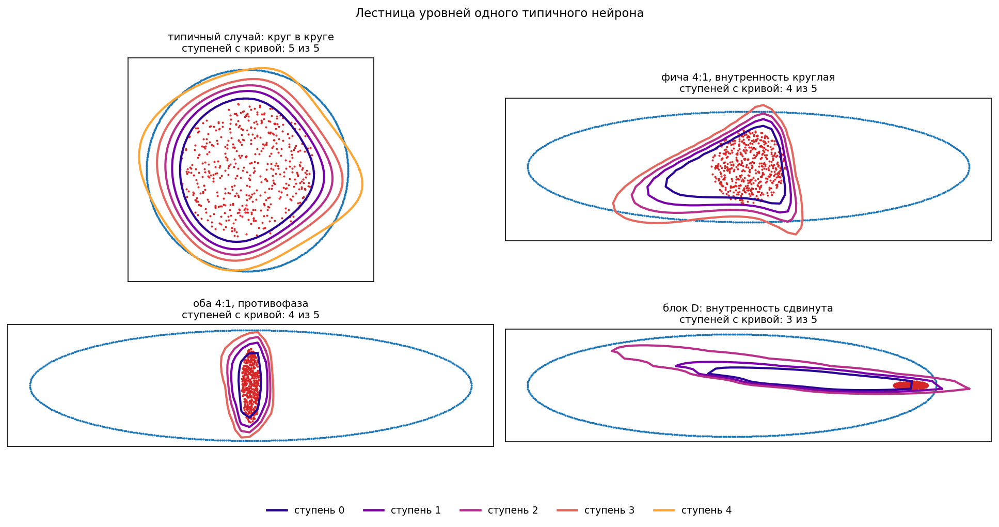

In [14]:
CASES = [(ANCHOR, "типичный случай: круг в круге"),
         (ELONG, "фича 4:1, внутренность круглая"),
         ("g5_f040_i040T_s100_o+0000+0000_b0500", "оба 4:1, противофаза"),
         ("g5_f040_i040_s050_o+0525+0000_b0500", "блок D: внутренность сдвинута")]
ramp = plt.cm.plasma(np.linspace(.05, .8, 5))

fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), dpi=150)
for ax, (name, title) in zip(axes.flat, CASES):
    nn = gs.best_neuron_of(best, name, which="median")
    LL = gs.ladder_curves(name, model_path=nn["model_path"],
                          layer_id=nn["layer_id"], coord_id=nn["coord_id"])
    X, y, A, _ = gs.dataset_points(name)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=.9, c=gp.C_INTERIOR, zorder=1)
    ax.scatter(A[:, 0], A[:, 1], s=.9, c=gp.C_FEATURE, zorder=2)
    got = 0
    for j, cu in enumerate(LL["curves"]):
        if cu is None:
            continue
        got += 1
        cc = cu.numpy()
        ax.plot(*np.vstack([cc, cc[:1]]).T, color=ramp[j], lw=2.0, zorder=3)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{title}\nступеней с кривой: {got} из 5", fontsize=9.5)
fig.suptitle("Лестница уровней одного типичного нейрона", fontsize=11)
plt.tight_layout()
fig.legend(handles=[plt.Line2D([], [], color=ramp[j], lw=2.2, label=f"ступень {j}")
                    for j in range(5)],
           loc="lower center", ncol=5, fontsize=9, frameon=False, bbox_to_anchor=(.5, -.03))
plt.show()

**Наблюдения.**

- **Круг в круге.** Пять круглых вложенных кривых; внешняя почти совпадает с фичей. Это та
  картина, ради которой критерий и строился, и её видели эксперименты 1 и 2.
- **Фича 4:1, внутренность круглая.** Кривые компактны и заметно нескруглы — скорее треугольны, — но ни одна
  не эллиптична вдоль фичи. Размер растёт,
  очертание не меняется, и ни одна ступень не приближается к форме фичи, хотя внешняя по размеру
  уже с ней сравнима.
- **Противофаза.** Кривые вытянуты **поперёк** фичи, вдоль внутренности.
- **Блок D.** Кривые вытянуты вдоль длинной оси; там круглая кривая не разделила бы классы.

**Вывод.** Это четыре примера, а не измерение: они показывают, **что именно** прибор описывает и
на что смотреть, и задают вопрос, который разбирается в блоках A, B, C и D — меняется ли форма
вдоль лестницы и чем она задана. Никакого общего утверждения отсюда пока не следует.


## 1.7 Как замкнутая структура строится по слоям

До сих пор нейроны рассматривались вперемешку. Но у нейрона **первого** скрытого слоя форма
предопределена: это `tanh(w·x + b)`, её линии уровня — прямые, и замкнуть внутренность они не
могут ни при каких весах. Значит замкнутая структура обязана возникать с глубиной.

Ниже четыре величины по слоям. Первые три — о кривой **средней ступени** лестницы по значению:
доля нейронов, у которых она вообще есть; её средний радиус `r₀`; промах её центроида мимо центра
внутренности. Четвёртая — `coverage`, полнота углового профиля, и она здесь не о сети, а о
приборе: смотреть её надо не по слоям, а по числу точек на кривой.

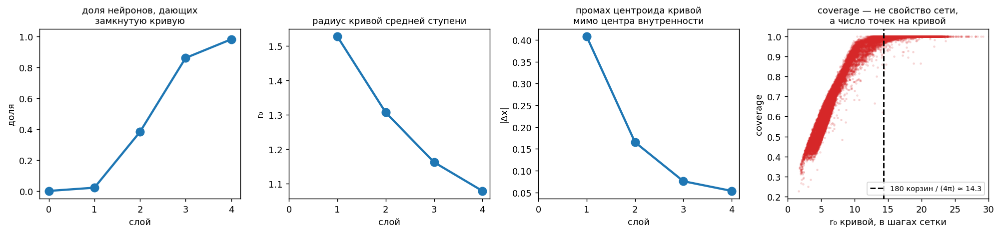

           доля     r0  смещение
layer_id                        
0         0.000    NaN       NaN
1         0.021  1.527     0.408
2         0.382  1.306     0.165
3         0.861  1.162     0.076
4         0.982  1.078     0.054

Спирмен coverage vs r₀/h: +0.974
Спирмен coverage vs r₀ в единицах длины: -0.011



медиана d_feat (честное расстояние по 6 гармоникам) по слоям и аспекту фичи,
в скобках — число нейронов:
  слой 1: 1:1 → 0.122 (n=20)   1.5:1 → 0.115 (n=30)   2.5:1 → 0.304 (n=22)   4:1 → 0.431 (n=17)
  слой 2: 1:1 → 0.112 (n=385)   1.5:1 → 0.106 (n=479)   2.5:1 → 0.236 (n=487)   4:1 → 0.440 (n=408)
  слой 3: 1:1 → 0.108 (n=859)   1.5:1 → 0.100 (n=915)   2.5:1 → 0.245 (n=928)   4:1 → 0.442 (n=869)
  слой 4: 1:1 → 0.110 (n=988)   1.5:1 → 0.102 (n=988)   2.5:1 → 0.245 (n=990)   4:1 → 0.446 (n=992)


In [15]:
t = df[df.feature_role == "target"].copy()
t["r0_шагов"] = t.harmonic_r0_mid / t.grid_step
by = t.groupby("layer_id").agg(
    доля=("harmonic_a2_mid", lambda s: s.notna().mean()),
    r0=("harmonic_r0_mid", "median"),
    смещение=("harmonic_offset_x", lambda s: s.abs().median()))

fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.7))
for ax, (col, ttl, ylab) in zip(axes[:3], [
        ("доля", "доля нейронов, дающих\nзамкнутую кривую", "доля"),
        ("r0", "радиус кривой средней ступени", "r₀"),
        ("смещение", "промах центроида кривой\nмимо центра внутренности", "|Δx|")]):
    ax.plot(by.index, by[col], "o-", lw=2.4, ms=9, color=gp.C_FEATURE)
    ax.set_xlabel("слой"); ax.set_ylabel(ylab); ax.set_xticks(by.index); ax.set_title(ttl, fontsize=10)
axes[0].set_ylim(-.05, 1.05)

tc = t.dropna(subset=["harmonic_coverage_mid"])
axes[3].scatter(tc.r0_шагов, tc.harmonic_coverage_mid, s=3, alpha=.12, color=gp.C_INTERIOR)
axes[3].axvline(180/(4*np.pi), color="k", ls="--", lw=1.6,
                label="180 корзин / (4π) ≈ 14.3")
axes[3].set_xlabel("r₀ кривой, в шагах сетки"); axes[3].set_ylabel("coverage")
axes[3].set_xlim(0, 30); axes[3].legend(fontsize=8)
axes[3].set_title("coverage — не свойство сети,\nа число точек на кривой", fontsize=10)
plt.tight_layout(); plt.show()

print(by.round(3).to_string())
print(f"\nСпирмен coverage vs r₀/h: "
      f"{tc[['harmonic_coverage_mid','r0_шагов']].corr(method='spearman').iloc[0,1]:+.3f}")
print(f"Спирмен coverage vs r₀ в единицах длины: "
      f"{tc[['harmonic_coverage_mid','harmonic_r0_mid']].corr(method='spearman').iloc[0,1]:+.3f}")

shl = gs.shape_by_cell(lv)
A_ = shl[(shl.block == "A") & (shl.rung == 2)]
lay = lv[(lv.block == "A") & (lv.rung == 2) & lv.dfeat.notna()]
print("\nмедиана d_feat (честное расстояние по 6 гармоникам) по слоям и аспекту фичи,")
print("в скобках — число нейронов:")
piv = lay.pivot_table(index="layer_id", columns="feature_aspect", values="dfeat", aggfunc="median")
cnt = lay.pivot_table(index="layer_id", columns="feature_aspect", values="dfeat", aggfunc="size")
for l in piv.index:
    print(f"  слой {l}: " + "   ".join(
        f"{a:g}:1 → {piv.loc[l, a]:.3f} (n={int(cnt.loc[l, a])})"
        for a in piv.columns if piv.loc[l, a] == piv.loc[l, a]))

**Наблюдения.**

- **Слой 0 не даёт ни одной замкнутой кривой** — ровно 0.000 из 14 000. Это не статистика, а
  теорема: линии уровня `tanh(w·x + b)` суть прямые. Прибор её подтверждает и тем самым сам
  проходит проверку.
- Дальше доля растёт **0.02 → 0.38 → 0.86 → 0.98**: замкнутая структура собирается с глубиной и
  к последнему скрытому слою есть почти у каждого нейрона.
- Одновременно кривая **садится на место**: радиус падает 1.53 → 1.08, промах центроида мимо
  центра внутренности — **0.41 → 0.05**, в восемь раз.
- **`coverage` оказался величиной о приборе, а не о сети.** Его корреляция с `r₀/h` равна
  **+0.97**, а с `r₀` в единицах длины — **−0.01**. Профиль бьётся на 180 угловых корзин, кривая
  уплотняется шагом `h/2`, поэтому точек на ней примерно `4π·r₀/h`; при `r₀/h ≥ 14` их хватает на
  все корзины и `coverage` выходит ровно 1. Падение «по слоям» целиком объясняется тем, что у
  глубоких слоёв меньше `r₀` при том же шаге сетки. Дальше `coverage` используется только как
  флаг качества профиля.
- Расстояние до фичи `d_feat` по слоям меняется мало и не приближается к нулю ни на одном слое.

**Вывод.** Глубина строит **охват и центрирование**. Что она делает с формой — этого раздела
недостаточно, чтобы сказать: числа выше усреднены по разным ячейкам, а `d_feat` зависит от того,
какова сама фича. Форма разбирается в блоках A и B, где ячейки не смешиваются.


### Диктуется ли форма кривой номером слоя

У линии уровня на картинках выше видны «углы» — места, где кривая идёт почти прямо, а потом
резко поворачивает. Гипотеза, которую стоит проверить прямо: не связано ли **число углов** с
номером слоя — скажем, третья гармоника с третьим слоем, четвёртая с четвёртым. Проверка
бесплатна: амплитуды `a₁…a₆` средней ступени лежат в таблице результатов.

Ниже три панели. Слева — медианная амплитуда каждой гармоники, по слоям: насколько вообще
выражена каждая «угловатость». В середине — доля нейронов, у которых **самая большая** гармоника
именно `k`: какая из них главная у отдельной кривой, а не в среднем. Справа — `a₃` и `a₄` по
слоям и по вытянутости фичи: если углы диктуются слоем, линии по слоям должны разойтись, а по
вытянутости — нет.


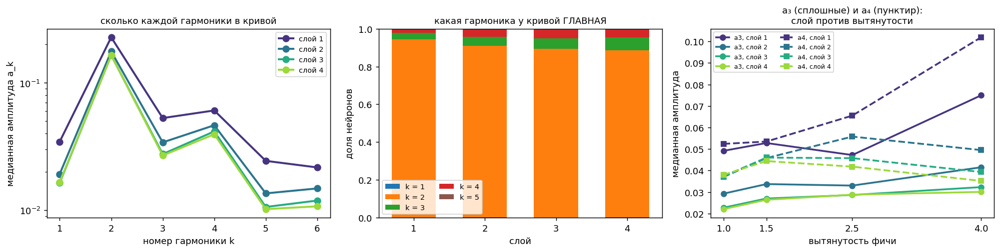

медианные амплитуды по слоям:
              a1      a2      a3      a4      a5      a6
layer_id                                                
1         0.0345  0.2281  0.0530  0.0608  0.0244  0.0217
2         0.0192  0.1766  0.0341  0.0465  0.0136  0.0148
3         0.0164  0.1648  0.0276  0.0416  0.0106  0.0119
4         0.0166  0.1646  0.0269  0.0395  0.0102  0.0107

доля нейронов, у которых главная гармоника = k:
kmax          1      2      3      4      5
layer_id                                   
1         0.000  0.944  0.034  0.022  0.000
2         0.002  0.908  0.047  0.043  0.000
3         0.001  0.893  0.055  0.050  0.001
4         0.002  0.884  0.069  0.044  0.001


In [16]:
tA = df[(df.feature_role == "target") & (df.block == "A") & (df.layer_id > 0)].copy()
tA = tA.dropna(subset=["harmonic_a2_mid"])
AK = [f"harmonic_a{k}_mid" for k in range(1, 7)]
med = tA.groupby("layer_id")[AK].median()
tA["kmax"] = np.argmax(tA[AK].values, axis=1) + 1
share = pd.crosstab(tA.layer_id, tA.kmax, normalize="index")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0))
lay_col = plt.cm.viridis(np.linspace(.15, .85, len(med)))
for c, l in zip(lay_col, med.index):
    axes[0].plot(range(1, 7), med.loc[l], "o-", lw=2.2, ms=7, color=c, label=f"слой {l}")
axes[0].set_xlabel("номер гармоники k"); axes[0].set_ylabel("медианная амплитуда a_k")
axes[0].set_yscale("log"); axes[0].legend(fontsize=8)
axes[0].set_title("сколько каждой гармоники в кривой", fontsize=10)

bottom = np.zeros(len(share))
kcol = plt.cm.tab10(np.linspace(0, .5, share.shape[1]))
for c, k in zip(kcol, share.columns):
    axes[1].bar(share.index, share[k], .62, bottom=bottom, color=c, label=f"k = {k}")
    bottom += share[k].values
axes[1].set_xlabel("слой"); axes[1].set_ylabel("доля нейронов")
axes[1].set_xticks(share.index); axes[1].legend(fontsize=8, ncol=2)
axes[1].set_title("какая гармоника у кривой ГЛАВНАЯ", fontsize=10)

for k, ls, mk in ((3, "-", "o"), (4, "--", "s")):
    piv = tA.pivot_table(index="feature_aspect", columns="layer_id",
                         values=f"harmonic_a{k}_mid", aggfunc="median")
    for c, l in zip(lay_col, piv.columns):
        axes[2].plot(piv.index, piv[l], ls, marker=mk, lw=2.0, ms=6, color=c,
                     label=f"a{k}, слой {l}")
axes[2].set_xlabel("вытянутость фичи"); axes[2].set_ylabel("медианная амплитуда")
axes[2].set_xticks([1, 1.5, 2.5, 4]); axes[2].legend(fontsize=7, ncol=2)
axes[2].set_title("a₃ (сплошные) и a₄ (пунктир):\nслой против вытянутости", fontsize=10)
plt.tight_layout(); plt.show()

print("медианные амплитуды по слоям:")
print(med.rename(columns=lambda s: s.replace("harmonic_", "").replace("_mid", ""))
      .round(4).to_string())
print("\nдоля нейронов, у которых главная гармоника = k:")
print(share.round(3).to_string())


**Наблюдения.**

- **Номер слоя углов не диктует.** Главная гармоника — вторая (вытянутость) у **88–94 %**
  нейронов на **каждом** слое. Доли `k = 3` и `k = 4` растут с глубиной очень слабо (0.034 → 0.069
  и 0.022 → 0.044) и нигде не образуют пика на «своём» слое.
- **Глубина углы не добавляет, а снимает.** По ряду слоёв 1 → 4 медианные амплитуды падают
  монотонно и тем сильнее, чем выше гармоника: `a₃` 0.053 → 0.027, `a₄` 0.061 → 0.040,
  `a₅` 0.024 → 0.010, `a₆` 0.022 → 0.011. Вытянутость при этом падает много слабее:
  `a₂` 0.228 → 0.165. То есть с глубиной кривая **скругляется**, сохраняя вытянутость.
- **Что двигает `a₄` — вытянутость фичи, и только на первом слое.** На слое 1 при фиче 4:1
  `a₄ = 0.102` против 0.052 у круглой; к слою 4 эта зависимость исчезает и даже меняет знак
  (0.038 против 0.035). `a₃` ведёт себя так же слабее.

**Как это читать.** Кривая нейрона первого скрытого слоя — это композиция пяти линейных
функций (ширина сети = 5), поэтому её линия уровня похожа на многоугольник, и высокие гармоники
у неё велики по построению. Глубже композиций больше, и углы сглаживаются. Это **прочтение**, а
не результат: проверить его можно только на оси ширины, которой в этом эксперименте нет — вся
сетка обучена при `w5 d5`. Ось ширины есть в эксперименте 2, и там этот вопрос стоит задать.


---

## 1.8 Итог раздела 1

1. Форма — **вектор из шести гармоник с фазами**, а не число; расстояние складывается из всех
   шести, и какая из них главная, зависит от пары кривых (1.2).
2. Собственная точность прибора — **0.010 при `r₀ ≥ 4` шага сетки**, и это надо отличать от шага
   сетки аспектов дизайна (0.144), который выбрали мы. Отношение одного к другому — четырнадцать
   (1.3).
3. Основная величина — **λ**; она вырождается там, где формы объектов совпадают, и такие ячейки
   (диагональ блока A) служат контролем, а не результатом (1.4).
4. Уровни выбираются двумя правилами, симметричными по обоим объектам: **по значению поля** и
   **по радиусу**. Смотреть надо на все ступени сразу; одну берут только когда нужно одно число
   на ячейку (1.5).
5. Как выглядит лестница на данных — показано на четырёх примерах; они задают вопрос для блоков
   A–D, но сами по себе ничего не доказывают (1.6).
6. **Глубина строит охват и центрирование**: доля замкнутых кривых 0 → 0.98, промах центроида
   0.41 → 0.05. Про форму по этим данным судить нельзя — ячейки смешаны (1.7).
7. **Номер слоя формы не диктует**: главная гармоника — вторая у 88–94 % нейронов на каждом
   слое, а глубина высокие гармоники не добавляет, а снимает — `a₃` 0.053 → 0.027,
   `a₄` 0.061 → 0.040 от слоя 1 к слою 4 (1.7).
8. **`coverage` — величина о приборе**, а не о сети: корреляция с `r₀/h` равна 0.97, с `r₀` в
   единицах длины — ноль (1.7).


---
# 2. Блок A. Форма против формы

## Постановка

Шестнадцать ячеек: аспект **фичи** (1 / 1.5 / 2.5 / 4) против аспекта **внутренности** (те же
четыре). Объекты концентричны, размер внутренности и число точек не меняются — варьируется
только форма двух объектов, независимо друг от друга.

**Главная гипотеза программы** после экспериментов 1 и 2 такова: релевантная топологическая
особенность задаётся **совместно** — самой особенностью и множеством противоположного класса
внутри неё. Эксперименты 1 и 2 не могли её проверить: там оба объекта круглые и концентричные,
и «форму задаёт фича» с «форму задаёт внутренность» предсказывают одно и то же. Блок A —
первая конфигурация, где два вклада разведены и их можно измерить порознь.

Отсюда три частных гипотезы о форме линии уровня:

| | гипотеза | предсказание |
|---|---|---|
| **а** | форму задаёт **фича** | аспект кривой растёт вместе с аспектом фичи |
| **б** | форму задаёт **внутренность** | аспект кривой растёт вместе с аспектом внутренности |
| **в** | форма **своя** и от объектов почти не зависит | аспект кривой почти не меняется по сетке |

Диагональ — контроль: там объекты подобны, `objects_shape = 0`, и (а) с (б) неразличимы по
построению (1.4). Всё, что говорится о λ и о расстояниях до объектов, относится к пятнадцати
недиагональным ячейкам.

## Протокол: как считаются все числа этого раздела

Усреднение — место, где легче всего незаметно подтасовать, поэтому правило одно на весь раздел
и совпадает с тем, что заморожен для структурного критерия:

> **на пару (ячейка, модель) берётся ЭКСТРЕМУМ по нейронам, дальше показывается распределение
> по 50 моделям.** Никакого усреднения по нейронам и никакого усреднения по ячейкам.

Экстремум — минимум расстояния формы: «нашёлся ли **хоть один** нейрон, чья линия уровня несёт
эту форму». Это ровно тот же вопрос, что задаёт структурный критерий («нашёлся ли хоть один
нейрон, чья линия уровня совпала с мишенью»), и потому числа двух приборов сравнимы. Там, где
показывается не отбор, а само распределение форм (2.2, 2.5), рисуются **все** кривые без всякого
отбора — и это оговорено у каждой фигуры.

**Данные раздела — одна таблица.** Прогон сохранил полный спектр только для средней ступени, а
разделам 2.2–2.6 он нужен на каждой, поэтому лестница пересчитана заново для **всех** нейронов
слоёв 1–4 всех пятидесяти моделей всех пятидесяти шести ячеек: 50 × 20 × 5 ступеней на ячейку.
Это не второе измерение, а тот же счёт: окно поля, якоря лестницы, извлечение контура и
дескриптор взяты из `analysis.shape_descriptors`, которым считал сервер, и совпадение с его
колонками `r₀`, `d_feat`, `d_int` проверено — расхождение 7·10⁻⁷. Таблица строится один раз
(`scripts/build_harmonic_ladder.py`) и лежит рядом с результатами прогона.

Слой 0 в неё не входит: его линии уровня — прямые, замкнутой кривой там нет по теореме (1.7).

**Про порог 0.144.** Расстояние формы читается буквально: `d = 0.10` означает, что две кривые
расходятся в среднеквадратичном на 10 % своего радиуса (это равенство Парсеваля, 1.2). Порог
0.144 — расстояние между окружностью и эллипсом 1.5:1, то есть наименьшая разница форм, которую
дизайн обязан различать. Он **назван, а не подобран**, но он всё же соглашение, поэтому всюду,
где по нему считается доля, рядом показано и само распределение расстояний.

Ниже — все шестнадцать датасетов, чтобы дальше было видно, о чём речь.

## Карта раздела

Раздел большой, поэтому вот что где решается — по одной строке на подраздел.

| | вопрос | ответ одной строкой |
|---|---|---|
| **2.1** | как это вообще выглядит | кривые всех шестнадцати ячеек на фоне поля нейрона |
| **2.2.1** | меняется ли вытянутость вдоль лестницы | нет; двигает её внутренность, а не фича |
| **2.2.2** | как устроено распределение | плотная масса у 1–2 плюс правая группа весом до 34 % |
| **2.2.3** | **чем это можно описать** | три конструкции; лучшая — равновесный потенциал пары, но обе половины эффекта не даёт ни одна |
| **2.3.1** | на что способна отдельная сеть | самый вытянутый нейрон модели против типичного |
| **2.3.2** | правая группа — популяция или мусор | популяция: четыре независимые проверки |
| **2.3.3** | чем особенны сети, дающие вытянутые кривые | ничем, кроме того, что ставят кривые ближе |
| **2.4** | чью форму несёт кривая | ничью целиком; ближе всего к окружности |
| **2.5** | куда она вытянута | вдоль общей оси объектов; порядок задаёт внутренность |
| **2.6** | меняется ли форма вдоль семейства | почти нет, и независимо от различия объектов |
| **2.7** | что говорят структурный и гомологический критерии | тот же перелом; гомологический теряет специфичность |
| **2.8** | итог | |


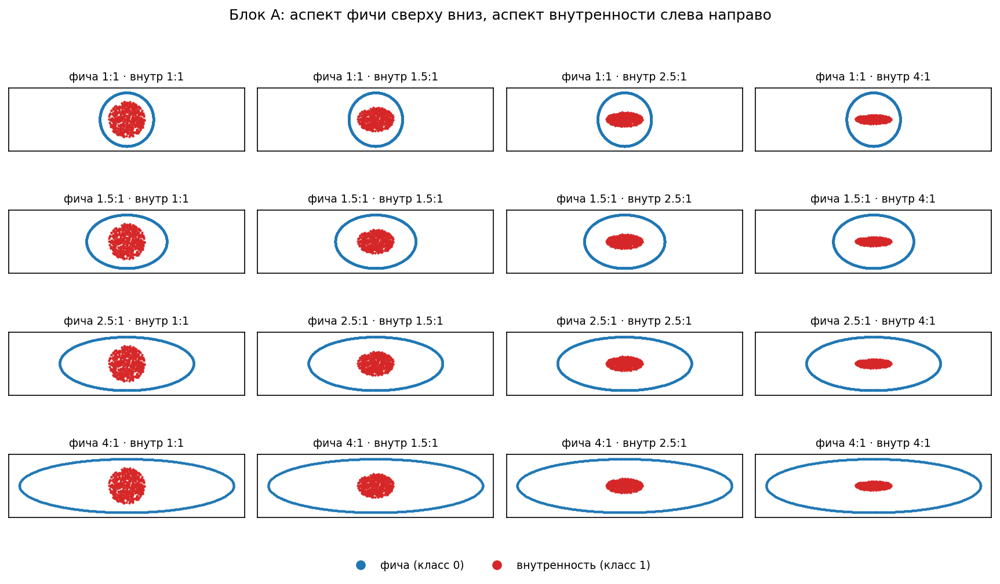

In [17]:
gp.plot_cell_gallery(
    plan_A := sorted(cells[cells.block == "A"].dataset_type),
    [f"фича {r.feature_aspect:g}:1 · внутр {r.interior_aspect:g}:1"
     for r in cells_meta.loc[plan_A].itertuples()],
    ncols=4, panel=2.9,
    suptitle="Блок A: аспект фичи сверху вниз, аспект внутренности слева направо")
plt.show()

## 2.1 Сначала посмотреть: кривые всех шестнадцати ячеек

Прежде чем считать что-либо, надо увидеть предмет. Ниже — все шестнадцать ячеек блока A, в
каждой один нейрон одной модели, и у него **все пять ступеней** лестницы по значению.

Три решения, каждое из которых меняет картинку и потому названо явно.

**Какая модель.** Медианная по ячейке: из пятидесяти моделей берётся та, чей лучший нейрон даёт
медианный структурный скор. Не лучшая — иначе шестнадцать панелей показывали бы шестнадцать
удачных случаев.

**Какой нейрон.** Две сетки, два правила. В первой — **лучший по структурному скору** нейрон этой
модели: кривая, которая ближе всего подошла к фиче, то есть лучшее, на что модель способна. Во
второй — **медианный по скору** среди нейронов с замкнутой кривой: обычный нейрон той же модели.
Второе правило важно само по себе: если обе сетки окажутся похожи, значит нейроны внутри модели
взаимозаменяемы, и «лучший нейрон» — не особая находка, а типичный представитель.

**Фон — поле нейрона**, как в 1.5: цвет есть ранг значения, и там, где цвет меняется быстро, поле
крутое. Кадр общий **внутри строки** (у строки одна и та же фича, поэтому размеры сравнимы), но
между строками разный: фича 4:1 вчетверо длиннее круглой, и общий кадр на всю сетку сделал бы
верхнюю строку нечитаемой.


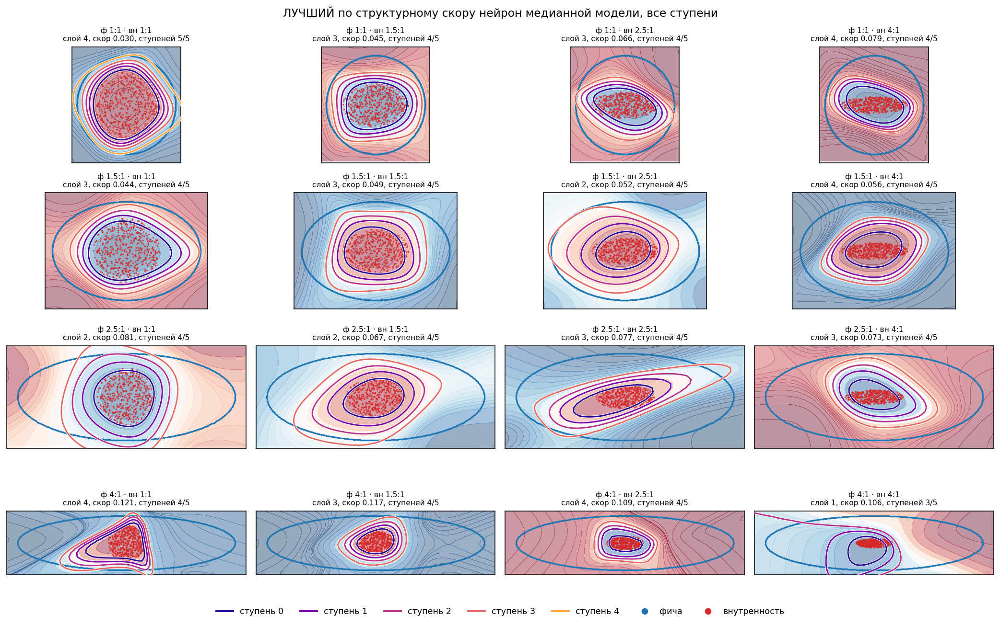

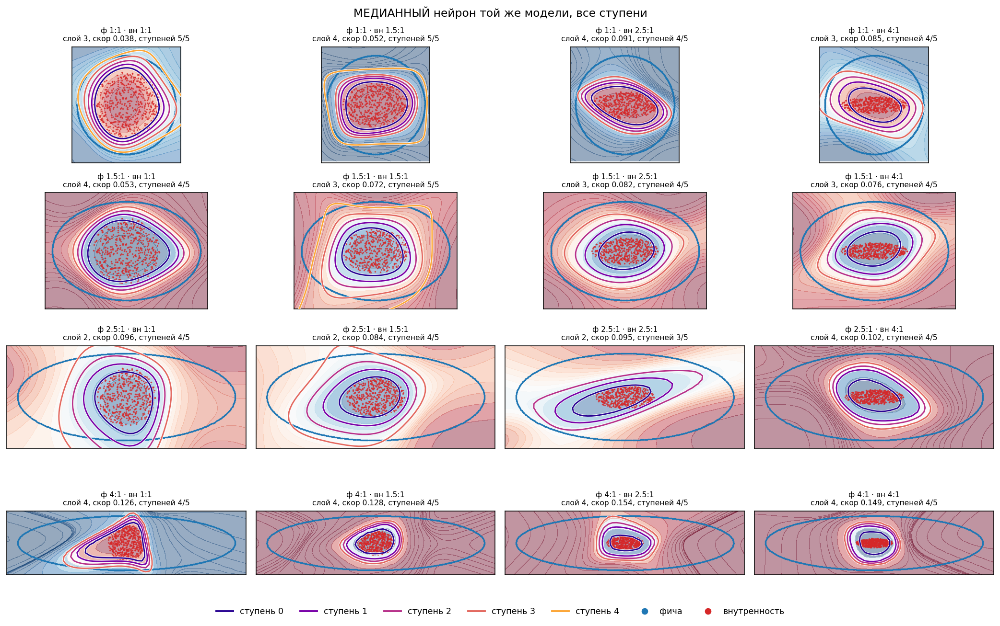

лучший против медианного нейрона ОДНОЙ И ТОЙ ЖЕ модели:
                  ячейка  тот_же_нейрон  скор_лучший  скор_медианный  d_между_кривыми
фича 1.0:1, внутр. 1.0:1          False        0.030           0.038            0.016
фича 1.0:1, внутр. 1.5:1          False        0.045           0.052            0.006
фича 1.0:1, внутр. 2.5:1          False        0.066           0.091            0.030
фича 1.0:1, внутр. 4.0:1          False        0.079           0.085            0.009
фича 1.5:1, внутр. 1.0:1          False        0.044           0.053            0.026
фича 1.5:1, внутр. 1.5:1          False        0.049           0.072            0.023
фича 1.5:1, внутр. 2.5:1          False        0.052           0.082            0.022
фича 1.5:1, внутр. 4.0:1          False        0.056           0.076            0.017
фича 2.5:1, внутр. 1.0:1          False        0.081           0.096            0.063
фича 2.5:1, внутр. 1.5:1          False        0.067           0.084            0.04

In [18]:
from analysis.shape_descriptors import fourier_descriptor, shape_distance

tgt_all = df[(df.feature_role == "target") & (df.block == "A")]

def typical_model(name):
    # модель, чей лучший нейрон даёт медианный по ячейке скор
    g = best[(best.dataset_type == name) & (best.feature_role == "target")]
    order = g["score"].sort_values()
    return g.loc[order.index[len(order)//2]]

def neuron_of(name, mrow, which):
    g = tgt_all[(tgt_all.dataset_type == name) & (tgt_all.model_path == mrow.model_path)
                & (tgt_all.layer_id > 0)]
    if which == "best":
        r = g.loc[g.structural_score_normalized_by_diameter.idxmin()]
    else:
        gg = g[g.harmonic_n_closed > 0].sort_values("structural_score_normalized_by_diameter")
        r = gg.iloc[len(gg)//2]
    return int(r.layer_id), int(r.coord_id), float(r.structural_score_normalized_by_diameter)

# один проход: поля считаются по разу на нейрон, картинки рисуются из готового
panels, cmp_rows = {}, []
for name in plan_A:
    mrow = typical_model(name)
    for which in ("best", "typical"):
        layer, coord, sc = neuron_of(name, mrow, which)
        LL = gs.ladder_curves(name, model_path=mrow.model_path, layer_id=layer,
                              coord_id=coord)
        panels[(name, which)] = dict(layer=layer, coord=coord, score=sc, LL=LL)
    b, t = panels[(name, "best")], panels[(name, "typical")]
    cb, ct = b["LL"]["curves"][2], t["LL"]["curves"][2]
    cmp_rows.append(dict(
        ячейка=cells_meta.loc[name, "label"],
        тот_же_нейрон=(b["layer"], b["coord"]) == (t["layer"], t["coord"]),
        скор_лучший=b["score"], скор_медианный=t["score"],
        d_между_кривыми=(np.nan if cb is None or ct is None else
                         shape_distance(fourier_descriptor(cb), fourier_descriptor(ct)))))

def draw_ladder_grid(which, title):
    fig, axes = plt.subplots(4, 4, figsize=(15, 9.2), dpi=140)
    for row in range(4):
        names = plan_A[4*row:4*row+4]
        hx, hy = gp.cells_extent(names)                # общий кадр внутри строки
        for ax, name in zip(axes[row], names):
            meta, P = cells_meta.loc[name], panels[(name, which)]
            X, y, A = gs.dataset_points(name)[:3]
            gp.field_background(ax, P["LL"]["field"], window=(hx, hy),
                                alpha=.42, levels=17)
            ax.scatter(X[y == 1, 0], X[y == 1, 1], s=.7, c=gp.C_INTERIOR,
                       alpha=.7, zorder=1)
            ax.scatter(A[:, 0], A[:, 1], s=.7, c=gp.C_FEATURE, zorder=2)
            got = 0
            for j, cu in enumerate(P["LL"]["curves"]):
                if cu is None:
                    continue
                got += 1
                gp.draw_curve(ax, cu.numpy(), ramp[j], lw=1.5, zorder=3+j, halo=1.0)
            ax.set_xlim(-hx, hx); ax.set_ylim(-hy, hy)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1"
                         f"\nслой {P['layer']}, скор {P['score']:.3f}, ступеней {got}/5",
                         fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    fig.legend(handles=[plt.Line2D([], [], color=ramp[j], lw=2, label=f"ступень {j}")
                        for j in range(5)]
               + [plt.Line2D([], [], marker="o", ls="", color=gp.C_FEATURE, label="фича"),
                  plt.Line2D([], [], marker="o", ls="", color=gp.C_INTERIOR,
                             label="внутренность")],
               loc="lower center", ncol=7, fontsize=9, frameon=False,
               bbox_to_anchor=(.5, -.02))
    plt.show()

draw_ladder_grid("best", "ЛУЧШИЙ по структурному скору нейрон медианной модели, все ступени")
draw_ladder_grid("typical", "МЕДИАННЫЙ нейрон той же модели, все ступени")

cmp = pd.DataFrame(cmp_rows)
print("лучший против медианного нейрона ОДНОЙ И ТОЙ ЖЕ модели:")
print(cmp.round(3).to_string(index=False))
print(f"\nсовпал нейрон: {int(cmp.тот_же_нейрон.sum())} ячеек из {len(cmp)}")
print(f"медианная разница скоров: {(cmp.скор_медианный - cmp.скор_лучший).median():.3f}")
print(f"медианное расстояние ФОРМЫ между их средними кривыми: "
      f"{cmp.d_между_кривыми.median():.3f} "
      f"(шаг дизайна 0.144, точность прибора ~0.01)")


**Наблюдения.**

- **Верхняя строка: фича кругла во всех четырёх ячейках, а кривые — нет.** В левой ячейке оба
  объекта круглые, кривая круглая, внешние ступени лежат прямо на фиче: это та самая вырожденная
  конфигурация экспериментов 1 и 2, где по картинке нельзя сказать, чью форму кривая повторяет.
  Но дальше вправо по строке **фича не меняется**, а кривые становятся всё более эллиптичными
  вслед за внутренностью — и в правой ячейке они уже заметно вытянуты при круглой фиче. Вырождение
  снимается именно здесь, и снимает его внутренность.
- **Нижняя строка: фича 4:1, и ни одна кривая за ней не идёт.** Все пять ступеней остаются
  компактными и держатся внутренности; между кривой и концами фичи остаётся пустое место
  длиной в несколько радиусов. При этом поле там не плоское — складка видна, — просто она
  обходит фичу.
- **Лучший и медианный нейрон — разные нейроны, но почти одна кривая.** Совпадения нет ни в одной
  из 16 ячеек, разница скоров медианно 0.017, а расстояние ФОРМЫ между их средними кривыми —
  медианно **0.025**, вшестеро меньше шага дизайна 0.144. То есть «лучший нейрон» здесь не
  уникальная находка, а представитель: внутри модели нейроны почти взаимозаменяемы. Исключение
  одно и оно осмысленное — ячейка «оба 4:1», где `d = 0.245`: там модели и правда не сходятся
  в том, что рисовать.
- **Внешняя ступень чаще всего отсутствует** — в 14 ячейках из 16 показано 4 из 5 ступеней. Это
  измерено в 1.5 и здесь просто видно.

**Вывод (предварительный, до счёта).** Картинка ставит вопрос, а не отвечает на него: похоже, что
кривая держится внутренности и не тянется за вытянутой фичей. Но шестнадцать панелей — это
шестнадцать нейронов из 20 000, и любая из них могла быть выбрана удачно. Дальше то же самое
меряется по всем нейронам всех моделей.


## 2.2 Вытянутость: все нейроны

Картинка 2.1 показала шестнадцать нейронов. Теперь то же самое по **всем** нейронам всех
пятидесяти моделей каждой ячейки — слои 1–4, все пять ступеней лестницы **по значению**.
Слой 0 исключён не выборочно: его линии уровня — прямые, замкнутой кривой там не бывает по
теореме (1.7), и включать его значило бы разбавлять выборку заведомыми пропусками.

Это перерасчёт, а не вторая таблица: поле, лестница, контур и дескриптор — те же, что считал
серверный прогон, и совпадение с его колонками проверено до седьмого знака. Прогон хранил полный
спектр только для средней ступени, здесь он есть на каждой; всё остальное — то же самое.

**Величина.** Вытянутость кривой, пересчитанная из второй гармоники по формуле
`(1 + a₂)/(1 − a₂)`, — то же отношение осей, которым описаны сами объекты, поэтому кривую и
объекты можно класть на одну шкалу. Перевод точен для эллипса и приблизителен для чего-то ещё
(1.3), а формой в полном смысле остаётся вектор из шести гармоник — он появится в 2.4 и 2.6.

Раздел разбит на три части: **по ступеням** (меняется ли вытянутость вдоль семейства),
**по распределению** (есть ли у нейронов режимы) и **по геометрии зазора** (не вынуждена ли
вытянутость самой конфигурацией, безотносительно к сети).


### 2.2.1 По ступеням лестницы

Одна панель на ячейку, по пять страт — по одной на ступень. Штриховая линия — вытянутость фичи, пунктирная — внутренности, чёрная черта — медиана ступени. Точек в панели около 2 500, поэтому они мелкие и полупрозрачные; форма облака и медиана читаются, отдельная точка — нет, и не должна.


кривых: 39 718 | нейронов: 10 905 | моделей в ячейке: [50]
вытянутость выше 4.5: 0.54% кривых; максимум 14.0
на верхнем краю шкалы (a₂ больше, чем у любого эллипса): 0.12%


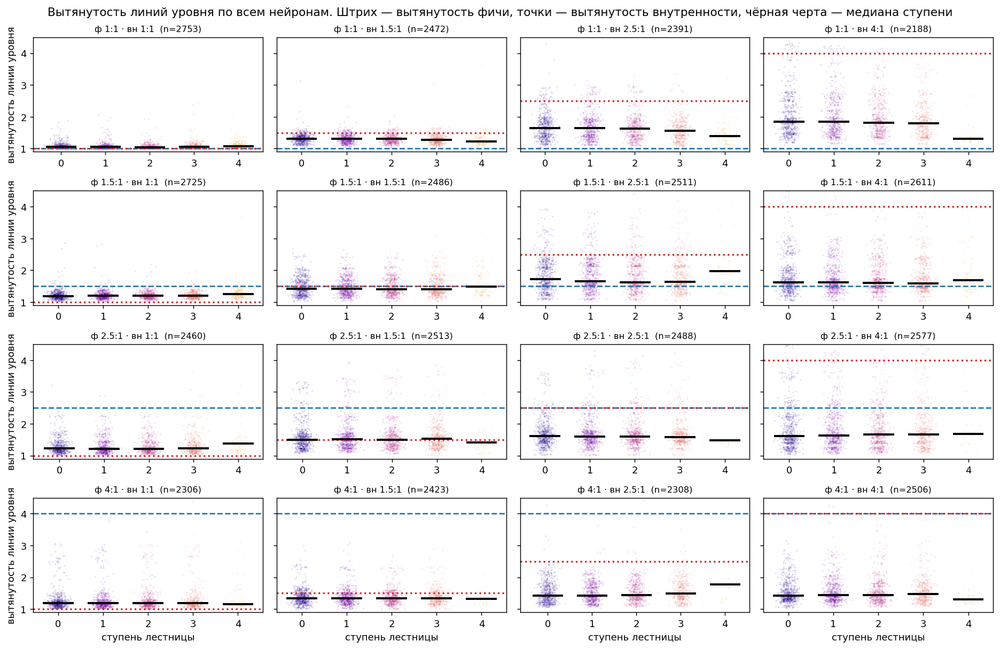

In [19]:
hl = gs.load_harmonic_ladder("value")                  # полный спектр на каждой ступени
sub = hl[(hl.block == "A") & (hl.layer_id > 0)].copy()
print(f"кривых: {len(sub):,}".replace(",", " "),
      f"| нейронов: {sub.groupby(['dataset_type','model_index','layer_id','coord_id']).ngroups:,}"
      .replace(",", " "),
      f"| моделей в ячейке: {sub.groupby('dataset_type').model_index.nunique().unique()}")

YTOP = 4.5                       # выше — хвост, доля печатается ниже
print(f"вытянутость выше {YTOP}: {(sub.aspect > YTOP).mean():.2%} кривых; "
      f"максимум {sub.aspect.max():.1f}")
print(f"на верхнем краю шкалы (a₂ больше, чем у любого эллипса): "
      f"{(sub.a2 > 0.9).mean():.2%}")

fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.5), sharey=True)
rng = np.random.default_rng(0)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = sub[sub.dataset_type == name]
    for j in range(5):
        v = g[g.rung == j]["aspect"]
        if not len(v):
            continue
        ax.scatter(rng.normal(j, .10, len(v)), v, s=3, alpha=.12, color=ramp[j],
                   linewidths=0)
        ax.plot([j-.32, j+.32], [v.median()]*2, color="k", lw=2.2, zorder=5)
    ax.axhline(meta.feature_aspect, color=gp.C_FEATURE, ls="--", lw=1.5)
    ax.axhline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=1.8)
    ax.set_xticks(range(5)); ax.set_ylim(.9, YTOP)
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1  "
                 f"(n={len(g)})", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ступень лестницы")
for ax in axes[:, 0]:
    ax.set_ylabel("вытянутость линии уровня")
fig.suptitle("Вытянутость линий уровня по всем нейронам. Штрих — вытянутость фичи, "
             "точки — вытянутость внутренности, чёрная черта — медиана ступени", fontsize=12)
plt.tight_layout(); plt.show()


**Наблюдения.**

- **Кривая заметно круглее обоих объектов.** Медианная вытянутость по ячейкам лежит между
  **1.05 и 1.85**, тогда как объекты покрывают ряд 1 : 1.5 : 2.5 : 4. Ни в одной ячейке медиана
  не подходит к 4 и даже к 2.5.
- **Двигает её внутренность, а не фича.** Предельный эффект (медиана по ячейке, усреднённая по
  второй оси): вытянутость **внутренности** ведёт кривую 1.17 → 1.39 → 1.58 → 1.63 —
  монотонно, размах **0.46**; вытянутость **фичи** даёт 1.45 → 1.48 → 1.49 → 1.35 — размах
  **0.14**, и ряд не монотонен, последнее значение ниже первого. Втрое меньше по величине и без
  порядка.
- **Это видно и без чисел.** В верхней строке (фича кругла) медиана растёт слева направо вместе
  с внутренностью; в нижней (фича 4:1) она стоит на месте, а штриховая линия аспекта фичи
  проходит далеко сверху и ни разу не достигается.
- **Вдоль лестницы медиана почти не меняется** — на ступенях 0–3 разброс в пределах 0.05.
  Ступень 4 в таблице иногда выпадает из ряда (например 1.79 → 1.30), но это **не изменение
  формы**: внешняя ступень есть лишь у 10 % нейронов (1.5), и это другая подвыборка, а не другая
  форма. Прямая проверка того же вопроса — в 2.6, на нейронах, у которых есть обе крайние ступени.
- **Важная оговорка к оси фичи.** Вытягивая фичу при неизменной внутренности, мы меняем не
  только её форму: её площадь растёт вчетверо от 1:1 к 4:1, а внутренность остаётся прежней. То
  есть вдоль этой оси одновременно меняется **относительный размер** объектов, а значит и то,
  сколько места остаётся кривой. Поэтому наблюдаемое падение вытянутости вдоль оси фичи нельзя
  приписывать её форме: оно в равной мере совместимо с «больше свободы — круглее». Разделить эти
  два объяснения на нашей сетке нельзя, и в `exp5_shape_law.ipynb` показано, почему: все
  безразмерные меры свободы сцеплены с вытянутостью внутренности на +0.68…+0.79, потому что
  дизайн вытягивает внутренность при фиксированной большой полуоси.
- **Разброс внутри ячейки велик и структурен**: в каждой панели видно плотное облако у 1–2 и
  отдельные точки заметно выше. Что это — хвост или вторая группа — решается в 2.2.2.


### 2.2.2 Распределение по ячейкам: как оно устроено

Страты показывают медиану, а вопрос про **форму распределения** медиана не решает. Ниже те же
кривые как распределения — все ступени вместе, по одной панели на ячейку.

**Что здесь утверждается и чего не утверждается.** Утверждается наблюдаемое: у распределения
есть плотная основная масса и **отдельная группа справа**, вес которой сильно меняется по
ячейкам. Не утверждается, что это «вторая мода» в статистическом смысле, и вот почему.

Формальный тест на число мод (тест Сильвермана на критическую ширину окна, со сглаженным
бутстрэпом) я посчитал — его `p` стоит на панелях мелким шрифтом. Но он отвечает **не на тот
вопрос**. Два случая это показывают начисто. В базовой ячейке «круг в круге» кривых с
вытянутостью выше 2 **ровно ноль**, а унимодальность тест отвергает: складка сидит у самой
единицы и к правой группе отношения не имеет. Наоборот, в ячейке с самой большой правой группой
(вес 34 %) тест унимодальность **не отвергает**: там распределение гладкое. То есть «сколько
складок у плотности» и «есть ли вторая популяция нейронов» — разные вопросы, и первый на второй
не отвечает.

Поэтому дальше используется прямая величина — **вес правой группы**, доля кривых с вытянутостью
выше 2, — а вопрос «популяция или мусор» решается не формой гистограммы, а поведением этих
кривых: кучкуются ли они по сетям, держатся ли одного нейрона, направлены ли одинаково. Этим
занимается 2.3.


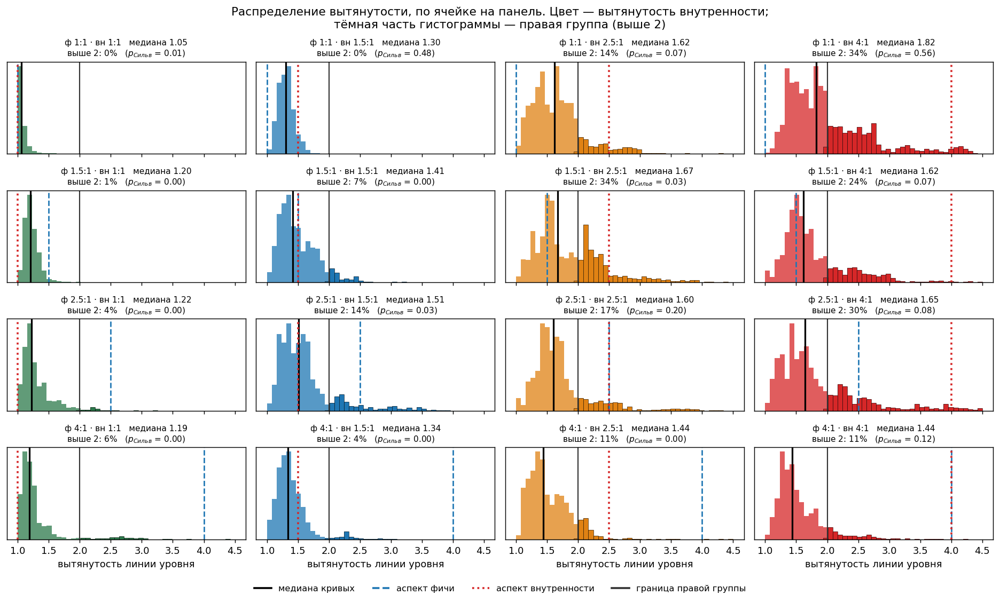

вес правой группы: от 0.2% до 34.2%; растёт с вытянутостью ВНУТРЕННОСТИ (3% → 6% → 19% → 25%) и почти не зависит от фичи (12% → 17% → 16% → 8%)
медиана самой правой группы: 2.13–2.86 по ячейкам — она НЕ следует за внутренностью (иначе при 4:1 стояла бы у 4)
тест Сильвермана отвергает унимодальность в 9 ячейках из 16, но не в тех, где группа больше всего: он отвечает на другой вопрос (см. текст выше)


In [20]:
one = sub[sub.rung == 2]                      # по одному значению с нейрона
sil = {name: gs.modality(one[one.dataset_type == name].a2.values, n_boot=200)["p_unimodal"]
       for name in plan_A}

fig, axes = plt.subplots(4, 4, figsize=(14.5, 8.6), sharex=True)
bins = np.linspace(1, 4.5, 46)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    v = sub[sub.dataset_type == name].aspect
    ax.hist(v, bins=bins, color=COL[meta.interior_aspect], alpha=.75)
    ax.hist(v[v > 2], bins=bins, color=COL[meta.interior_aspect], alpha=1.0,
            edgecolor="k", linewidth=.3)
    ax.axvline(2, color="#333", lw=1.2, ls="-")
    ax.axvline(float(v.median()), color="k", lw=1.8)
    ax.axvline(meta.feature_aspect, color=gp.C_FEATURE, ls="--", lw=1.5)
    ax.axvline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=2.0)
    ax.set_yticks([])
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1   "
                 f"медиана {v.median():.2f}\nвыше 2: {float((v > 2).mean()):.0%}"
                 f"   ($p_{{Сильв}}$ = {sil[name]:.2f})", fontsize=8.5)
for ax in axes[-1]:
    ax.set_xlabel("вытянутость линии уровня")
fig.legend(handles=[plt.Line2D([], [], color="k", lw=2, label="медиана кривых"),
                    plt.Line2D([], [], color=gp.C_FEATURE, lw=2, ls="--", label="аспект фичи"),
                    plt.Line2D([], [], color=gp.C_INTERIOR, lw=2, ls=":", label="аспект внутренности"),
                    plt.Line2D([], [], color="#333", lw=2, label="граница правой группы")],
           loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(.5, -.015))
fig.suptitle("Распределение вытянутости, по ячейке на панель. Цвет — вытянутость внутренности;\n"
             "тёмная часть гистограммы — правая группа (выше 2)", fontsize=12)
plt.tight_layout(rect=[0, .02, 1, 1]); plt.show()

w = sub.assign(hi=lambda d: d.aspect > 2).groupby(
    ["feature_aspect", "interior_aspect"]).hi.mean().unstack()
print(f"вес правой группы: от {w.values.min():.1%} до {w.values.max():.1%}; "
      f"растёт с вытянутостью ВНУТРЕННОСТИ ({' → '.join(f'{x:.0%}' for x in w.mean(axis=0))}) "
      f"и почти не зависит от фичи ({' → '.join(f'{x:.0%}' for x in w.mean(axis=1))})")
tail_med = sub[sub.aspect > 2].groupby("dataset_type").aspect.median()
print(f"медиана самой правой группы: {tail_med.min():.2f}–{tail_med.max():.2f} по ячейкам — "
      f"она НЕ следует за внутренностью (иначе при 4:1 стояла бы у 4)")
print(f"тест Сильвермана отвергает унимодальность в "
      f"{sum(p < .05 for p in sil.values())} ячейках из {len(sil)}, но не в тех, где группа "
      f"больше всего: он отвечает на другой вопрос (см. текст выше)")


**Наблюдения.**

- **Правая группа видна глазом почти везде и её вес считается прямо.** Он идёт от 0 % при обоих
  круглых объектах до **34 %** при внутренности 4:1 и круглой фиче.
- **Вес растёт с вытянутостью внутренности и почти не зависит от фичи** — в точности как медиана
  из 2.2.1, то есть это тот же эффект, только видимый в другой части распределения.
- **Группа не копирует внутренность.** Её собственная медиана держится **2.1–2.9 во всех
  шестнадцати ячейках**: будь она копией, при внутренности 4:1 стояла бы у 4. Значит это не
  «нейроны, повторившие внутренность», а что-то со своим масштабом.
- **Формальный тест мимо.** Он отвергает унимодальность в 9 ячейках из 16, но среди них базовая
  «круг в круге», где правой группы нет вовсе, — и не отвергает в ячейке, где группа
  наибольшая. Как инструмент для нашего вопроса он не годится, и я на него не опираюсь.


### 2.2.3 Три подхода к описанию наблюдаемого

Разделы 2.2.1 и 2.2.2 сообщили **наблюдаемое поведение**: кривая круглее обоих объектов, её
вытянутость растёт с вытянутостью внутренности и по-разному реагирует на фичу — добавляется, когда
внутренность кругла, и убавляется, когда вытянута.

Дальше — **модели**, то есть геометрические конструкции, которые это поведение воспроизводят или
не воспроизводят. **Ни одна из них не является утверждением о причине.** Абляции в эксперименте
нет, механизма обучения мы не наблюдаем, и всё, что можно сказать, — насколько точно та или иная
конструкция, посчитанная из одной геометрии пары, совпадает с измеренным. Слова «объясняет»
дальше означают только это.

Правило сравнения одно на все модели, и оно строгое: **предсказание считается из «бублика»** —
внутренности, фичи и пространства между ними — и **не использует ни одного числа, измеренного на
кривых**. Раньше я подбирал параметр модели по наблюдаемому среднему радиусу `r₀`; это давало
завышенно хорошие числа, потому что модель подглядывала в масштаб того, что должна предсказывать.
Ниже всё пересчитано без этого: у раздутия `δ` берётся как доля минимального зазора, у
гармонического потенциала уровень фиксирован, обе константы — одни на всю сетку.

Мерой качества служит **средняя абсолютная ошибка** по вытянутости, и читать её надо на шкале
самих измерений. Бейзлайна «всегда называть медиану по сетке» здесь быть не может, и это важно:
предсказывается не отдельный нейрон, а **популяционная величина ячейки** — медиана по всем её
кривым, — так что константа, подогнанная по тем же шестнадцати ответам, не нулевая модель, а
оракул. Шкалу задают три измеренные величины: предсказываемое число само известно с точностью
около **±0.09** (полуширина бутстрапа по пятидесяти сетям ячейки; по ячейкам 0.01–0.18), по сетке
оно пробегает **0.77**, а два разведённых дизайном эффекта стоят **0.46** (внутренность) и
**0.14** (фича). Конструкция, ошибающаяся больше, соответствующего эффекта не разрешает.

**Одна оговорка, которую надо держать в голове всю дорогу.** Ось «вытянутость фичи» — не чистая
ось формы: вытягивая фичу при фиксированной малой полуоси, мы вчетверо увеличиваем её площадь и
тем самым даём кривой больше места. Поэтому всё, что ниже приписывается «форме фичи», может
оказаться эффектом **относительного размера**. Модели, различающие эти два прочтения, на нашей
сетке неразличимы, и это ограничение дизайна, а не анализа.

**Одна предпосылка, без которой разговор бессмыслен.** Круглая линия уровня разделяет классы во
**всех 56 ячейках эксперимента**: диск, содержащий внутренность и лежащий внутри фичи, существует
везде, а в блоке A он даже концентрический — внутренность держит большую полуось 1.00, фича малую
1.50, поэтому годится любая окружность радиуса от 1.00 до 1.50, с одинаковым запасом 0.50 в каждой
из шестнадцати ячеек. Значит **геометрия нигде не вынуждает вытянутости**, и всё, что мы измеряем,
— не необходимость, а то, что сеть делает, имея выбор.

Три части: что не сработало, раздутие, гармонический потенциал.


#### (а) Идеи, которые не сработали

Четыре конструкции, и все четыре родственны: каждая берёт форму кривой как некоторый **компромисс
между формами двух границ**.

**Срединная линия зазора.** Кривая, идущая ровно посередине между объектами в каждом направлении.
Самая естественная догадка: раз кривая обязана разделять, пусть она держится подальше от обеих
стенок.

**Кривая максимального зазора.** То же, но расстояние честно евклидово, а не радиальное:
множество точек, равноудалённых от внутренности и от фичи. Это то, что предложит любой человек из
машинного обучения, — граница максимального отступа.

**Равномерная мера на всех допустимых кривых.** Не одна кривая, а усреднение: рассмотреть все
гладкие замкнутые кривые, помещающиеся в зазор (`r_in ≤ r ≤ r_out`, первые шесть гармоник), и
взять типичную. Идея в том, что искать механизм не нужно — наблюдаемая кривая просто «обычная».

**Подгонка смеси форм.** Не геометрия, а регрессия: `a₂(кривой) = w₁·a₂(внутренности) +
w₂·a₂(фичи)`, коэффициенты подобраны по данным.

Ниже показано, **что каждая из них предлагает** — на одной ячейке, где они расходятся сильнее
всего.


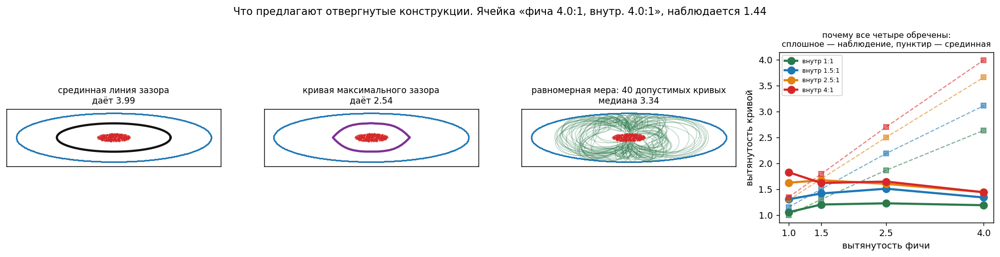

In [21]:
from scipy.stats import spearmanr
import analysis.shape_models as sm
SM = pd.read_csv("analysis/results/experiments/exp5_geometry/shape_models.csv")
MA_obs = SM[SM.block == "A"].sort_values(["feature_aspect", "interior_aspect"])
SM33 = SM[SM.block.isin(["A", "A⊥", "C"])]
SHOW = plan_A[15]                                   # ф 4:1 · вн 4:1
ang, r_in, r_out, centre = sm.annulus_radial(SHOW)
X, y, A = gs.dataset_points(SHOW)[:3]
hx, hy = gp.cells_extent([SHOW])

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.0))
def frame(ax, title):
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=.7, c=gp.C_INTERIOR, alpha=.5, zorder=1)
    ax.scatter(A[:, 0], A[:, 1], s=.7, c=gp.C_FEATURE, zorder=2)
    ax.set_xlim(-hx, hx); ax.set_ylim(-hy, hy); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9.5)

def draw_radial(ax, r, **kw):
    p = centre + np.stack([r*np.cos(ang), r*np.sin(ang)], 1)
    ax.plot(*np.vstack([p, p[:1]]).T, **kw)

mid_line = .5*(r_in + r_out)          # не 'mid': так зовут глобальную таблицу форм
frame(axes[0], f"срединная линия зазора\nдаёт {sm.aspect_of_radial(mid_line, ang, centre):.2f}")
draw_radial(axes[0], mid_line, color="#111", lw=2.4)

xs, ys, Feq, c0 = sm.equidistant_curve(SHOW)
cu = sm.enclosing_level_curve(xs, ys, Feq, 0.0, c0)
aeq = float(gs.a2_to_aspect(np.array([fourier_descriptor(
    torch.tensor(cu, dtype=torch.float32))["amplitude"][2]]))[0])
frame(axes[1], f"кривая максимального зазора\nдаёт {aeq:.2f}")
axes[1].plot(*np.vstack([cu, cu[:1]]).T, color="#7b3294", lw=2.4)

_, S, _ = sm.sample_annulus_curves(SHOW, n=40, seed=1)
frame(axes[2], "равномерная мера: 40 допустимых кривых\n"
      f"медиана {np.median([sm.aspect_of_radial(r, ang, centre) for r in S]):.2f}")
for r in S:
    draw_radial(axes[2], r, color="#2c7a4b", lw=.7, alpha=.35)

for ia, g in MA_obs.groupby("interior_aspect"):
    g = g.sort_values("feature_aspect")
    axes[3].plot(g.feature_aspect, g.observed, "o-", color=COL[ia], lw=2.4, ms=8,
                 label=f"внутр {ia:g}:1")
    axes[3].plot(g.feature_aspect, g.midline, "s--", color=COL[ia], lw=1.2, ms=5, alpha=.6)
axes[3].set_xticks([1, 1.5, 2.5, 4]); axes[3].set_xlabel("вытянутость фичи")
axes[3].set_ylabel("вытянутость кривой"); axes[3].legend(fontsize=7)
axes[3].set_title("почему все четыре обречены:\nсплошное — наблюдение, пунктир — срединная",
                  fontsize=9)
fig.suptitle(f"Что предлагают отвергнутые конструкции. Ячейка «{cells_meta.loc[SHOW, 'label']}», "
             f"наблюдается {float(MA_obs[MA_obs.dataset_type == SHOW].observed.iloc[0]):.2f}",
             fontsize=11.5)
plt.tight_layout(); plt.show()


**Что с ними не так — одним рассуждением, до всяких чисел.** Все четыре монотонны по форме каждой
из границ: вытяните фичу, и предсказание вытянется, при любой внутренности. А наблюдаемая
зависимость от фичи **меняет знак** — при круглой внутренности растёт (1.05 → 1.19), при
вытянутой падает (1.82 → 1.44). Правая панель показывает это прямо: пунктир расходится вверх,
сплошные линии — вниз. Значит исключён не отдельный кандидат, а **весь класс «компромисс между
формами двух границ»**.

**Числа, для протокола** (средняя абсолютная ошибка по вытянутости; неопределённость самих
предсказываемых чисел ±0.09, эффекты 0.46 и 0.14):

* срединная линия зазора — **0.79**, ранговая связь +0.11;
* кривая максимального зазора — **0.40**, +0.38 (p = 0.15);
* равномерная мера — **0.65**, +0.24; вдобавок она даёт 1.11 вместо 1.00 в ячейке из двух
  концентрических кругов: случайный разброс читается дескриптором как вытянутость;
* подгонка смеси форм по двум-четырём параметрам — **0.13–0.16**; работает, но это регрессия, а
  не геометрия, и вклад фичи в ней входит с одним знаком, то есть смену знака она тоже не
  воспроизводит.

Для равномерной меры отрицательный результат оказался **теоремой**, а не наблюдением: при любой
мере, симметричной относительно срединной линии, среднее по кривым равно этой линии в точности, а
средняя форма не может быть круглее её (`|c₂|/c₀` — выпуклая функция коэффициентов, дальше
Йенсен). Никакое усреднение по зазору не даст кривую круглее середины, а наблюдаемые сильно
круглее. Подробности — в `exp5_shape_law.ipynb`.


#### (б) Раздутие внутренности

Конструкция: кривая — множество точек на **постоянном расстоянии `δ` от границы внутренности**.
Не растяжение: растянуть эллипс в 1.3 раза значит умножить обе полуоси, раздуть на 0.3 — прибавить
0.3 к каждой. У круга это одно и то же, у эллипса — разные вещи, и именно поэтому раздутие
**округляет**: `(a+δ)/(b+δ) → 1` монотонно по `δ`.

Что конструкция воспроизводит: форма идёт за внутренностью (раздувается она), но со сжатием; и
чем больше места оставляет фича, тем больше `δ` и тем круглее результат. Чего не воспроизводит:
раздутие круга есть круг при любом `δ`, поэтому при **круглой** внутренности модель обязана
выдать ровно 1.000 в каждой из четырёх ячеек, тогда как наблюдается 1.05 → 1.19. Фича входит в
конструкцию только через `δ`, формой — никак.

**Откуда берётся `δ` — и почему прежний ответ был нечестным.** Раньше я подбирал `δ` так, чтобы
раздутая кривая имела тот же средний радиус `r₀`, что наблюдаемые кривые ячейки. Но `r₀` —
величина, снятая **с самих линий уровня**, а линии уровня определены при каждом значении поля;
чтобы взять их средний радиус, надо сперва решить, какие из них описывать, и это решение уже
опирается на данные. Модель при этом подглядывает в масштаб того, что должна предсказывать.

Честный вариант использует **только бублик**: `δ = K · (минимальная ширина зазора)`, где `K` —
одна константа на всю сетку. Медиана наблюдённой доли по блоку A даёт `K = 0.45`, и дальше это
число не трогается. Ниже — оба варианта, чтобы разница была видна.


In [ ]:
DG = [sm.dilation_from_gap(n, 0.45) for n in plan_A]
MA_obs = MA_obs.assign(dil_geo=[d["aspect"] for d in DG], delta_geo=[d["delta"] for d in DG])

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.1))
for ax, name in zip(axes[:2], [plan_A[3], plan_A[15]]):
    meta = cells_meta.loc[name]; row = MA_obs[MA_obs.dataset_type == name].iloc[0]
    Xc, yc, Ac = gs.dataset_points(name)[:3]
    hx2, hy2 = gp.cells_extent([name])
    ax.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=.7, c=gp.C_INTERIOR, alpha=.5, zorder=1)
    ax.scatter(Ac[:, 0], Ac[:, 1], s=.7, c=gp.C_FEATURE, zorder=2)
    dl = gs.dilated_interior(sm.objects(name)[0], float(row.delta_geo))
    ax.plot(*np.vstack([dl, dl[:1]]).T, color="#111", lw=2.6, zorder=5)
    ax.set_xlim(-hx2, hx2); ax.set_ylim(-hy2, hy2); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1\n"
                 f"δ = {row.delta_geo:.2f} → {row.dil_geo:.2f}, наблюдается {row.observed:.2f}",
                 fontsize=9)

lim = [.95, 2.6]
axes[2].plot(lim, lim, ls=":", c="k", lw=1.3)
axes[2].scatter(MA_obs.dil_geo, MA_obs.observed, s=85,
                c=[COL[f] for f in MA_obs.feature_aspect], edgecolor="white", zorder=3)
axes[2].set_xlim(lim); axes[2].set_ylim(1.0, 2.0)
axes[2].set_xlabel("раздутие, δ = 0.45 · зазор"); axes[2].set_ylabel("наблюдается")
axes[2].set_title(f"Спирмен {spearmanr(MA_obs.dil_geo, MA_obs.observed)[0]:+.2f}, "
                  f"ошибка {np.abs(MA_obs.dil_geo - MA_obs.observed).mean():.3f}", fontsize=10)

for ia, g in MA_obs.groupby("interior_aspect"):
    g = g.sort_values("feature_aspect")
    axes[3].plot(g.feature_aspect, g.observed, "o-", color=COL[ia], lw=2.4, ms=8,
                 label=f"внутр {ia:g}:1")
    axes[3].plot(g.feature_aspect, g.dil_geo, "s--", color=COL[ia], lw=1.2, ms=5, alpha=.65)
axes[3].set_xticks([1, 1.5, 2.5, 4]); axes[3].set_xlabel("вытянутость фичи")
axes[3].set_ylabel("вытянутость кривой"); axes[3].legend(fontsize=7)
axes[3].set_title("падение по оси фичи модель ловит,\nподъём при круглой внутренности — нет",
                  fontsize=9)
fig.suptitle("Раздутие внутренности, δ взято из зазора и ничего не знает о кривых", fontsize=11.5)
plt.tight_layout(); plt.show()


def cell_uncertainty(names, n_boot=400, seed=0):
    """Полуширина 95 % бутстрапа медианы вытянутости ячейки — ресэмпл по СЕТЯМ.

    Это та точность, с которой вообще известно предсказываемое число, и именно
    против неё надо читать ошибку конструкции. «Всегда называть медиану по
    сетке» бейзлайном тут быть не может: предсказывается не отдельный нейрон, а
    популяционная величина ячейки, и константа, подогнанная по тем же
    шестнадцати ответам, — не нулевая модель, а оракул.
    """
    rng = np.random.default_rng(seed)
    out = []
    for name in names:
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        by = {m: v.aspect.to_numpy() for m, v in g.groupby("model_index")}
        keys = list(by)
        b = [np.median(np.concatenate([by[keys[i]]
                                       for i in rng.choice(len(keys), len(keys), True)]))
             for _ in range(n_boot)]
        lo, hi = np.percentile(b, [2.5, 97.5])
        out.append((hi - lo) / 2)
    return np.array(out)


U_A = cell_uncertainty(plan_A)
print(f"ШКАЛА. предсказывается медиана по ячейке; она сама известна с точностью "
      f"±{np.median(U_A):.2f} (по ячейкам {U_A.min():.2f}–{U_A.max():.2f}),")
print(f"       по сетке пробегает {MA_obs.observed.max() - MA_obs.observed.min():.2f}, "
      f"эффект внутренности 0.46, эффект фичи 0.14")
for col, lab in (("dil_geo", "раздутие, δ = 0.45 · зазор (только бублик)"),
                 ("dilation", "раздутие, δ подобран по наблюдённому r₀")):
    print(f"  {lab:44s} Спирмен {spearmanr(MA_obs[col], MA_obs.observed)[0]:+.3f}  "
          f"ошибка {np.abs(MA_obs[col]-MA_obs.observed).mean():.3f}")
print(f"\nна 33 концентричных ячейках (A, A⊥, C): раздутие с подобранным δ — "
      f"{np.abs(SM33.dilation-SM33.observed).mean():.3f}")


**Наблюдения.**

- **Направление зависимостей раздутие ловит хорошо**: ранговая связь +0.87, и правая панель
  показывает, что падение вытянутости вдоль оси фичи (при вытянутой внутренности) оно
  воспроизводит.
- **Но как предсказание величины оно не работает.** Средняя ошибка **0.238** — это вдвое дальше
  потенциала, вдвое с лишним больше неопределённости самих чисел и половина эффекта внутренности,
  так что более слабый эффект фичи (0.14) оно не разрешает вовсе. На 33 концентричных ячейках
  картина та же (0.31–0.37).
- **Систематика ошибки понятна и не случайна.** При круглой внутренности модель обязана дать
  ровно 1.000 против наблюдаемых 1.05–1.23 — фича в конструкции не участвует. При вытянутой она
  завышает (2.45 против 1.82). Первое — структурный дефект, второе — следствие того, что у
  раздутия вытянутость убывает как `1/δ`, слишком медленно.
- Подгонка `δ` по наблюдённому `r₀` почти не меняет числа (0.242 против 0.238): дело не в способе
  калибровки, а в самой конструкции.

**Итог по (б).** Раздутие — хорошая **интуиция**: одна фраза объясняет и «форма от внутренности», и
«но круглее», и «чем больше места, тем круглее». Как количественная модель оно недостаточно.


#### (в) Гармонический потенциал

Конструкция из теории потенциала. Возьмём два объекта как обкладки конденсатора и решим задачу
Дирихле

$$\Delta u = 0 \ \text{в зазоре},\qquad u = 0 \ \text{на внутренности},\qquad u = 1 \ \text{на фиче}.$$

Кандидатом на линию уровня нейрона служит линия уровня `u`. Никаких параметров формы: `u`
определяется **только парой объектов**.

Три свойства, которых нет у предыдущих кандидатов:

1. **участвуют обе границы** — поэтому эффект фичи может менять знак, а не только расти;
2. **несимметричность**: линия при `u = 0.4` заметно ближе к внутренности, чем к фиче, — ровно то,
   чего требует теорема из части (а) от любой работающей конструкции;
3. **правильная скорость округления**: у поля проводника `k`-й мультиполь убывает как `r^{−k}`,
   поэтому вытянутость (квадруполь, `1/r²`) исчезает вдвое быстрее размера. У раздутия вытянутость
   падает лишь как `1/δ`, отчего оно и завышает.

Уровень фиксирован: `u = 0.40`, одна константа на всю сетку, из данных не берётся ничего.


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.3))
for ax, name in zip(axes[:3], [plan_A[0], plan_A[3], plan_A[15]]):
    meta = cells_meta.loc[name]; row = MA_obs[MA_obs.dataset_type == name].iloc[0]
    interior, _, c0 = sm.objects(name)
    xs, ys, F, step = sm.harmonic_potential(name)
    Xg, Yg = np.meshgrid(xs, ys, indexing="ij")
    ax.contourf(Xg, Yg, np.nan_to_num(F, nan=1.0), levels=np.linspace(0, 1, 21),
                cmap="RdBu_r", alpha=.55, zorder=0)
    for lv, c_ in zip((.2, .6, .8), plt.cm.viridis(np.linspace(.15, .8, 3))):
        cu = sm.enclosing_level_curve(xs, ys, F, lv, c0)
        if cu is not None:
            ax.plot(*np.vstack([cu, cu[:1]]).T, color=c_, lw=1.6,
                    label=f"u = {lv:g}" if ax is axes[0] else None)
    cu = sm.enclosing_level_curve(xs, ys, F, 0.40, c0)
    if cu is not None:
        ax.plot(*np.vstack([cu, cu[:1]]).T, color="#111", lw=2.8, zorder=6,
                label="u = 0.40" if ax is axes[0] else None)
    hx2, hy2 = gp.cells_extent([name])
    ax.set_xlim(-hx2, hx2); ax.set_ylim(-hy2, hy2); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1\n"
                 f"{row.harmonic_fixed:.2f} против {row.observed:.2f}", fontsize=9)
axes[0].legend(fontsize=7, loc="upper right")

for ia, g in MA_obs.groupby("interior_aspect"):
    g = g.sort_values("feature_aspect")
    axes[3].plot(g.feature_aspect, g.observed, "o-", color=COL[ia], lw=2.4, ms=8,
                 label=f"внутр {ia:g}:1")
    axes[3].plot(g.feature_aspect, g.harmonic_fixed, "s--", color=COL[ia], lw=1.2, ms=5, alpha=.65)
axes[3].set_xticks([1, 1.5, 2.5, 4]); axes[3].set_xlabel("вытянутость фичи")
axes[3].set_ylabel("вытянутость кривой"); axes[3].legend(fontsize=7)
axes[3].set_title("подъём при круглой внутренности модель ловит,\nпадение — нет", fontsize=9)
fig.suptitle("Равновесный потенциал пары; фон — сам потенциал, от 0 у внутренности до 1 у фичи",
             fontsize=11.5)
plt.tight_layout(); plt.show()

rows = []
for col, lab in (("midline", "срединная линия"), ("uniform", "равномерная мера"),
                 ("dil_geo", "раздутие, δ из зазора"),
                 ("harmonic_fixed", "потенциал, u = 0.40")):
    g = MA_obs.dropna(subset=[col])
    rows.append(dict(модель=lab, Спирмен=spearmanr(g[col], g.observed)[0],
                     ошибка=float(np.abs(g[col]-g.observed).mean())))
print("блок A, всё без единого числа из данных:")
print(pd.DataFrame(rows).round(3).to_string(index=False))
g33 = SM33.dropna(subset=["harmonic_fixed"])
print(f"\nна 33 концентричных: потенциал u = 0.40 — ошибка "
      f"{np.abs(g33.harmonic_fixed-g33.observed).mean():.3f}")


**Лучше ли он раздутия — и в каком смысле.** Утверждение нужно расщепить, потому что две метрики
дают разные ответы, и выбирать удобную было бы нечестно.

* **По точности — да, вдвое.** Средняя ошибка **0.119** против 0.238 у раздутия на блоке A. Это
  лишь немного больше неопределённости самих предсказываемых чисел (±0.09) и вчетверо меньше
  эффекта внутренности — но всё ещё порядка эффекта фичи, то есть более слабую из двух
  зависимостей потенциал не разрешает. На 33 концентричных ячейках — 0.222 против 0.373.
* **По упорядоченности — нет.** Ранговая связь +0.78 против +0.87 у раздутия: раздутие лучше
  ставит ячейки в правильном порядке.
* **По воспроизведению наблюдений — они дополняют друг друга.** Потенциал единственный даёт
  **подъём** вытянутости по оси фичи при круглой внутренности (1.00 → 1.23 против наблюдаемых
  1.05 → 1.19), недоступный раздутию по построению. Раздутие единственное даёт заметное
  **падение** по той же оси при вытянутой внутренности. **Обе половины вместе не даёт ни одна
  модель**, и это главный незакрытый остаток.

**Что из этого следует и чего не следует.** Следует: наблюдаемая форма линии уровня в
концентричных конфигурациях с точностью до 0.12 воспроизводится геометрической конструкцией, у
которой нет ни одного параметра формы. Не следует: что сеть эту конструкцию вычисляет, что поле
нейрона гармонично, что причина именно в этом. Речь идёт о **согласии** двух величин, и
эксперимент, не содержащий абляции, сильнее сказать не может.


#### (г) Гипотеза о потолке: как это можно собрать в одну картину

Все три части выше — про отдельные конструкции. Стоит проговорить прочтение, которое их
объединяет, и честно сказать, что в нём проверено, а что нет.

> **Кривые сами по себе тяготеют к форме окружности.** Форма внутренности может на них влиять —
> но влияние это не прямое: оно тем сильнее, чем меньше у кривой свободы, то есть чем теснее
> внутренность подпирает фичу. Сама фича при этом работает не как источник формы, а как **жёсткий
> потолок**: пока она не мешает, её форма почти ни на что не влияет; как только она начинает
> мешать, она становится главной.

Что из этого **подтверждается измерениями**:

* **«Тяготеют к окружности» — да.** Через кривую проходит лишь около **40 %** вытянутости
  внутренности (медиана 0.41 по концентричным ячейкам, `exp5_shape_law.ipynb` §8–9), и
  наблюдаемая форма всегда лежит между окружностью и формой внутренности — в 27 ячейках из 27.
* **«Влияет именно внутренность» — да, и это доказано направлением.** В блоке B, где объекты
  развёрнуты друг относительно друга, кривая идёт вдоль внутренности в 0.57–0.96 случаев против
  0.02–0.34 вдоль фичи.
* **«Фича — потолок, а не источник формы» — да, и это самая проверяемая часть.** В блоках A, B и
  C круглая кривая разделяет классы всегда, то есть потолок нигде не мешает, — и форма фичи там
  практически ничего не объясняет (аспект срединной линии, следующий за обоими объектами, даёт
  Спирмен +0.12). В шести ячейках блока D, где концентрическая окружность разделять перестаёт,
  то есть потолок начинает мешать, кривые вытягиваются **3.54 против 1.60** в остальных
  пятидесяти. Потолок молчит, пока не упрётся, и становится решающим, когда упрётся.

Что **не проверено**:

* **«Тем сильнее, чем меньше свободы».** Это самая содержательная часть гипотезы, и её на нашей
  сетке проверить нельзя. Все безразмерные меры свободы дают корреляцию нужного знака
  (−0.40…−0.50), но сцеплены с вытянутостью внутренности на +0.68…+0.79 — дизайн вытягивает
  внутренность при фиксированной большой полуоси, отчего свобода и форма меняются вместе. При
  контроле вытянутости связь исчезает (−0.10…−0.22, p > 0.26). Нужна ось, меняющая **размер**
  внутренности при неизменной **форме**; в плане она есть (`interior_scale`), но использована
  только в блоке D и там смешана со смещением.

**Итого.** Гипотеза согласуется со всем, что измерено, и в двух из трёх частей подтверждается
прямо. Её центральное звено — зависимость влияния от свободы — остаётся **не проверенным**, а не
подтверждённым, и для проверки нужен небольшой новый ряд ячеек.


#### Где геометрия всё же вынуждает: контроль из блока D

Все три части выше — про концентричные пары, где круглое решение доступно. Полезно посмотреть на
единственное место эксперимента, где оно **недоступно**.

Если потребовать, чтобы разделяющая окружность была **концентрична фиче**, она перестаёт
проходить ровно в **6 ячейках из 56** — все в блоке D, где внутренность сдвинута вдоль длинной
оси. Медианная вытянутость кривых там **3.54** против **1.60** в остальных пятидесяти, и
диапазоны не пересекаются.

Это не модель, а проверка чувствительности измерения: там, где круглое решение действительно
недоступно, кривые действительно вытягиваются — вчетверо сильнее. Значит наблюдаемая округлость в
остальных ячейках не артефакт прибора. Сами эти шесть ячеек, впрочем, не описываются ни одной из
трёх конструкций — разбор в блоке D и в `exp5_shape_law.ipynb`.


### Итог 2.2

**Наблюдаемое.**

1. Кривая круглее обоих объектов: медиана по ячейкам 1.05–1.85 при объектах 1–4.
2. Двигает её внутренность (размах предельного эффекта 0.46, монотонно), а не фича (0.14,
   немонотонно).
3. Эффект фичи **меняет знак**: при круглой внутренности добавляет вытянутости, при вытянутой —
   убавляет. С оговоркой: вдоль этой оси меняется не только форма фичи, но и **относительный
   размер** объектов (площадь фичи растёт вчетверо), то есть и количество свободного места. Обе
   половины пункта совместимы с прочтением «больше свободы — круглее», и разделить прочтения на
   этой сетке нельзя.
4. Распределение вытянутости не одномодально в 9 ячейках из 16, и группа выше аспекта 2
   существует с весом от 0 % до 34 %; популяция это или мусор — решается в 2.3.

**Модели, которые это описывают** (все считаются из одной геометрии пары; средняя абсолютная
ошибка по вытянутости, читать против ±0.09 неопределённости самих чисел и против эффектов 0.46 и
0.14):

| конструкция | ошибка | что не так |
|---|---|---|
| срединная линия зазора | 0.79 | монотонна по обеим границам, знак не меняет |
| кривая максимального зазора | 0.40 | то же |
| равномерная мера на допустимых кривых | 0.65 | теорема: не может быть круглее середины |
| раздутие внутренности | 0.24 | вдвое дальше потенциала; при круглой внутренности даёт ровно 1 |
| **гармонический потенциал, u = 0.40** | **0.12** | не воспроизводит падение по оси фичи |

Ни одна конструкция не воспроизводит **обе** половины пункта 3. Ни одна из них не является
утверждением о причине: абляции нет, и всё сказанное — о согласии двух величин.


## 2.3 Вытянутая группа: популяция или выбросы

В 2.2 видно, что выше аспекта 2 лежит заметная доля кривых — до трети в некоторых ячейках, — и
что тест на моды сам по себе про эту группу ничего не говорит. Значит вопрос надо ставить ребром:
**это популяция или мусор?**

Разница не словесная. Если это популяция, то у сети есть два разных способа обвести
внутренность, и вывод «кривая тяготеет к круглой» описывает только больший из них. Если это
выбросы — редкие неудачные нейроны, шум извлечения контура, нейроны с почти нулевой амплитудой,
у которых «вытянутость» ничего не значит, — то их надо просто отфильтровать и забыть.

Раздел устроен так: сперва смотрим на **крайние** нейроны каждой модели, потом проверяем группу
четырьмя независимыми способами.

### 2.3.1 Самые вытянутые нейроны каждой модели

**Почему именно максимум по модели.** Это тот же протокол, которым считается всё остальное в
разделе: единица наблюдения — модель, значение — её экстремальный нейрон. Он даёт ≤ 50 точек на
ступень вместо 500, то есть каждая точка — отдельная сеть, а не одна сеть, посчитанная двадцать
раз. Заодно это прямой ответ на вопрос «на что модель **способна**», а не «что она делает обычно».

**Что ещё можно было взять, и почему взято не это.** Верхние 5 % всех кривых ячейки — это просто
хвост того же распределения, обрезанный порогом: он не может ответить, популяция там или нет, он
и есть та часть, про которую спрашивают. Поэтому для сравнения рядом кладётся **другой** отбор:
нейрон, **лучший по структурному скору**, то есть тот, чью кривую критерий признал ближайшей к
фиче. Если вытянутые нейроны — мусор, среди лучших по скору их быть не должно.

На гистограммах три распределения на одной оси: все нейроны, самые вытянутые по модели, лучшие
по скору по модели. Все три нормированы на площадь, чтобы их можно было сравнивать при разном n.


кривых всего 39718; самых вытянутых по (модель, ступень) 3519; лучших по скору на модель 798


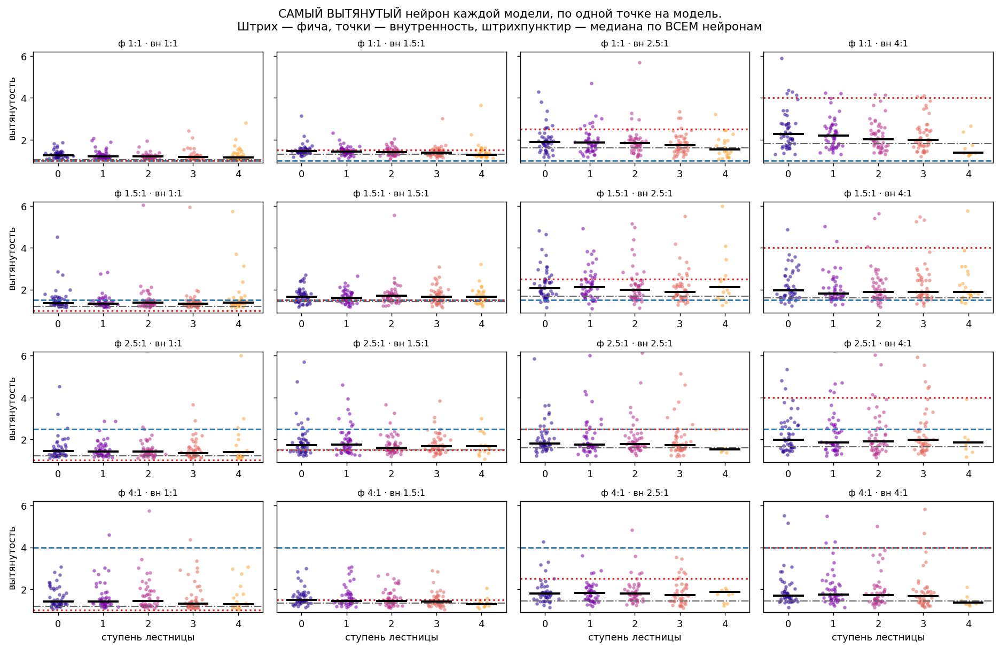

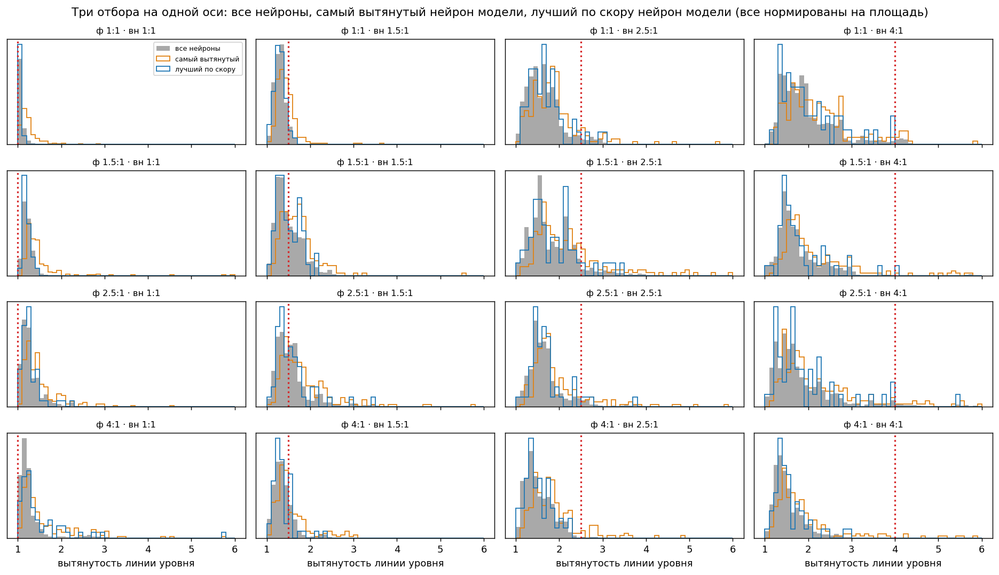


медиана вытянутости по ячейкам: все нейроны 1.05–1.82; самый вытянутый нейрон модели 1.20–2.09; лучший по скору нейрон модели 1.03–1.82
лучший по скору отличается от типичного на 0.022 — то есть ни на что


In [24]:
imap = gs.model_index_map(plan_A)
tgtA = df[(df.feature_role == "target") & (df.block == "A") & (df.layer_id > 0)].copy()
tgtA["model_path"] = tgtA.model_path.astype(str)
joined = (sub.merge(imap, on=["dataset_type", "model_index"])
             .merge(tgtA[["dataset_type", "model_path", "layer_id", "coord_id", gs.SCORE]]
                    .rename(columns={gs.SCORE: "скор"}),
                    on=["dataset_type", "model_path", "layer_id", "coord_id"], how="left"))
top = joined.loc[joined.groupby(["dataset_type", "model_index", "rung"]).aspect.idxmax()]
mid_j = joined[joined.rung == 2].dropna(subset=["скор"])
bysc = mid_j.loc[mid_j.groupby(["dataset_type", "model_index"]).скор.idxmin()]
print(f"кривых всего {len(sub)}; самых вытянутых по (модель, ступень) {len(top)}; "
      f"лучших по скору на модель {len(bysc)}")

fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.5), sharey=True)
rng = np.random.default_rng(3)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = top[top.dataset_type == name]
    allm = sub[sub.dataset_type == name].aspect.median()
    for j in range(5):
        v = g[g.rung == j].aspect
        if not len(v):
            continue
        ax.scatter(rng.normal(j, .10, len(v)), v, s=13, alpha=.55, color=ramp[j], linewidths=0)
        ax.plot([j-.32, j+.32], [v.median()]*2, color="k", lw=2.2, zorder=5)
    ax.axhline(allm, color="#666", lw=1.2, ls="-.")
    ax.axhline(meta.feature_aspect, color=gp.C_FEATURE, ls="--", lw=1.5)
    ax.axhline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=1.8)
    ax.set_xticks(range(5)); ax.set_ylim(.9, 6.2)
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ступень лестницы")
for ax in axes[:, 0]:
    ax.set_ylabel("вытянутость")
fig.suptitle("САМЫЙ ВЫТЯНУТЫЙ нейрон каждой модели, по одной точке на модель.\n"
             "Штрих — фича, точки — внутренность, штрихпунктир — медиана по ВСЕМ нейронам",
             fontsize=12)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 4, figsize=(14.5, 8.4), sharex=True)
bins = np.linspace(1, 6, 51)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    ax.hist(sub[sub.dataset_type == name].aspect, bins=bins, color="#9a9a9a",
            density=True, alpha=.85, label="все нейроны")
    ax.hist(top[top.dataset_type == name].aspect, bins=bins, density=True,
            histtype="step", lw=2.0, color="#e08214", label="самый вытянутый")
    ax.hist(bysc[bysc.dataset_type == name].aspect, bins=bins, density=True,
            histtype="step", lw=2.0, color=gp.C_FEATURE, label="лучший по скору")
    ax.axvline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=1.8)
    ax.set_yticks([])
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("вытянутость линии уровня")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Три отбора на одной оси: все нейроны, самый вытянутый нейрон модели, "
             "лучший по скору нейрон модели (все нормированы на площадь)", fontsize=12)
plt.tight_layout(); plt.show()

med_all = sub.groupby("dataset_type").aspect.median()
med_top = top.groupby("dataset_type").aspect.median()
med_sc = bysc.groupby("dataset_type").aspect.median()
print(f"\nмедиана вытянутости по ячейкам: все нейроны "
      f"{med_all.min():.2f}–{med_all.max():.2f}; самый вытянутый нейрон модели "
      f"{med_top.min():.2f}–{med_top.max():.2f}; лучший по скору нейрон модели "
      f"{med_sc.min():.2f}–{med_sc.max():.2f}")
print(f"лучший по скору отличается от типичного на "
      f"{np.abs(med_sc - med_all).median():.3f} — то есть ни на что")


**Наблюдения.**

- **Крайний нейрон каждой модели заметно вытянутее типичного, но не радикально.** Медиана
  самого вытянутого нейрона идёт **1.20 … 2.09** по ячейкам против **1.05 … 1.85** у всех
  нейронов: сдвиг есть везде, он порядка 0.15–0.30 и растёт вместе с внутренностью.
- **Верхние 5 % и «самый вытянутый на модель» — разные вещи, и разница поучительна.**
  95-й перцентиль по всем кривым ячейки идёт 1.23 … 3.94, то есть систематически выше. Это не
  противоречие: перцентиль режет объединённую выборку из ~2 500 кривых и берёт её верхние 125,
  а второй отбор берёт медиану 250 экстремумов, по одному с каждой пары (модель, ступень).
  Первый отвечает «как выглядит верхушка ячейки», второй — «на что способна отдельная сеть»,
  и для вопроса о популяции нужен второй: он гарантирует по точке с каждой сети, а перцентиль мог
  бы целиком состоять из кривых пяти удачных моделей.
- **Лучший по скору нейрон по форме неотличим от типичного** — медианы совпадают с точностью до
  второго знака. Это выглядит подозрительно (критерий как будто слеп к форме) и таковым и
  оказывается: в 2.3.2 показано, что внутри ячейки он к форме как раз **чувствительнее всего**,
  просто предпочитает круглые кривые при круглой фиче и вытянутые при вытянутой, а усреднение по
  сетке эти два предпочтения гасит. Что действительно следует отсюда — вытянутая группа не
  является отбраковкой: её не выбирают и не отбрасывают систематически.
- **До формы вытянутой фичи не дотягивается почти никто.** В нижней строке (фича 4:1) доля
  моделей, у которых самый вытянутый нейрон достигает аспекта 4, равна **0.04 · 0.01 · 0.08 ·
  0.07**. В верхней строке (фича — окружность) её превосходят, разумеется, все 100 %.
- **Осторожно с максимумом.** Сам максимум по ячейке упирается в потолок шкалы (14:1) в
  девяти ячейках из шестнадцати: это кривые, у которых `a₂` больше, чем у любого эллипса, и
  «отношение осей» для них уже не определено. Поэтому здесь читается **медиана экстремумов**, а
  не экстремум.


### 2.3.2 Четыре проверки

Картинки показали, что группа есть. Теперь четыре независимых способа отличить популяцию от
мусора; каждый мог бы провалиться отдельно.

**1. Кучкуются ли вытянутые кривые по моделям.** Если это шум извлечения, вытянутые кривые
рассыпаны по моделям равномерно и их число на модель ведёт себя как биномиальное. Если это
свойство сети, одни модели дают их много, другие ни одной, и дисперсия окажется больше
биномиальной. Мера — **сверхдисперсия**: наблюдённая дисперсия числа на модель, делённая на
биномиальную при той же доле. Единица — как у монетки, много — кучкуется.

**2. Свойство нейрона или свойство ступени.** У нейрона до пяти ступеней. Если вытянутость —
случайность извлечения, вытянутой окажется одна ступень из пяти. Если это форма семейства,
вытянуты будут все. Считается доля нейронов, вытянутых **на всех** своих ступенях, и сравнивается
с тем, что дало бы независимое бросание при той же общей доле.

**3. Есть ли у вытянутости направление.** Случайно вытянутая кривая направлена куда попало:
доля «вдоль» была бы около 1/3. Настоящий отклик на геометрию пары направлен вдоль общей оси
объектов. Сравниваются вытянутая группа и умеренная.

**4. Значит ли эта группа что-нибудь для задачи.** Абляции у нас нет, поэтому «значит» здесь —
это структурный скор: подходят ли вытянутые кривые к фиче ближе или дальше остальных, и в каких
ячейках.


1. кучкуются ли вытянутые кривые по моделям (сверхдисперсия; 1 = как у монетки)
 фича  внутр  доля  моделей  сверхдисперсия  моделей_без_ни_одной
  1.0    1.0 0.000       50             NaN                  1.00
  1.0    1.5 0.002       49            1.01                  0.98
  1.0    2.5 0.137       49            7.38                  0.71
  1.0    4.0 0.340       48            7.82                  0.50
  1.5    1.0 0.005       50            0.96                  0.94
  1.5    1.5 0.069       48           10.20                  0.81
  1.5    2.5 0.320       50            9.46                  0.50
  1.5    4.0 0.241       50            8.91                  0.56
  2.5    1.0 0.033       50            6.10                  0.86
  2.5    1.5 0.136       49           11.75                  0.76
  2.5    2.5 0.176       49           11.57                  0.67
  2.5    4.0 0.300       50           10.88                  0.54
  4.0    1.0 0.062       48            5.39                  0

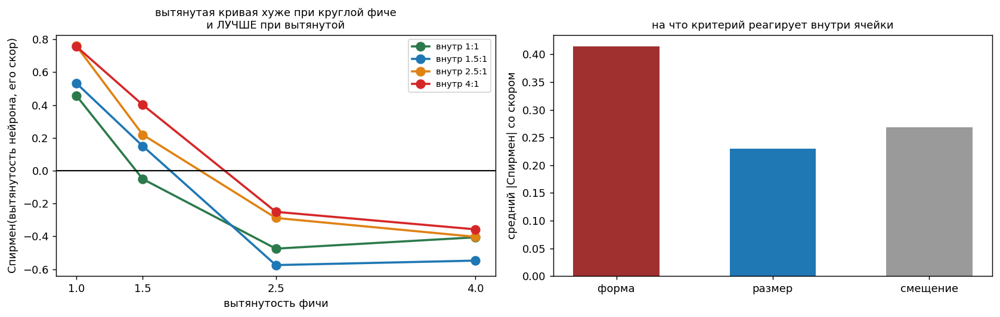

средний |Спирмен| скора: с формой 0.41, с размером 0.23, со смещением 0.27
знак связи со формой: положительный в 7 ячейках (круглая фича), отрицательный в 9 (вытянутая)

   доля вытянутых:
                среди всех нейронов  среди лучших по скору
feature_aspect                                            
1.0                           0.115                  0.140
1.5                           0.159                  0.171
2.5                           0.164                  0.176
4.0                           0.080                  0.100


In [25]:
from scipy.stats import spearmanr
one = sub[sub.rung == 2].copy(); one["hi"] = one.aspect > 2
rows = []
for name in plan_A:
    g = one[one.dataset_type == name]
    per = g.groupby("model_index").hi.agg(["sum", "size"])
    per = per[per["size"] >= 5]
    p = float(g.hi.mean())
    od = (per["sum"].var(ddof=1) / max((per["size"]*p*(1-p)).mean(), 1e-9)
          if 0 < p < 1 and len(per) >= 10 else np.nan)
    rows.append(dict(фича=cells_meta.loc[name, "feature_aspect"],
                     внутр=cells_meta.loc[name, "interior_aspect"],
                     доля=round(p, 3), моделей=len(per), сверхдисперсия=round(od, 2)
                     if od == od else np.nan,
                     моделей_без_ни_одной=round(float((per["sum"] == 0).mean()), 2)))
OD = pd.DataFrame(rows)
print("1. кучкуются ли вытянутые кривые по моделям (сверхдисперсия; 1 = как у монетки)")
print(OD.to_string(index=False))

w = sub.pivot_table(index=["dataset_type", "model_index", "layer_id", "coord_id"],
                    columns="rung", values="aspect")
w = w[w.notna().sum(axis=1) >= 3]
hi = (w > 2); n_have = w.notna().sum(axis=1); frac = hi.sum(axis=1) / n_have
p_hi = float(hi.sum().sum() / n_have.sum())
exp_all = p_hi ** float(n_have.mean())
print(f"\n2. свойство нейрона или ступени (нейронов с >= 3 ступенями: {len(w)})")
print(f"   вытянут на ВСЕХ своих ступенях:  {(frac == 1).mean():.3f}")
print(f"   не вытянут ни на одной:          {(frac == 0).mean():.3f}")
print(f"   смешанный ответ:                 {((frac > 0) & (frac < 1)).mean():.3f}")
print(f"   при независимых ступенях 'все' ожидалось бы {exp_all:.4f}, "
      f"наблюдается {(frac == 1).mean():.3f} — в {(frac == 1).mean()/max(exp_all,1e-9):.0f} раз больше")

g2 = sub[sub.a2 >= 0.10]
print("\n3. есть ли у вытянутости направление")
for lab, sel in (("вытянутые (аспект > 2)", g2.aspect > 2), ("умеренные (1.22–2)", g2.aspect <= 2)):
    a = g2[sel].angle2.values
    print(f"   {lab:24s} n = {len(a):6d}   вдоль {((a < 30) | (a > 150)).mean():.3f}   "
          f"поперёк {((a > 60) & (a < 120)).mean():.3f}   (случайность дала бы 0.33 и 0.33)")

jm = joined[joined.rung == 2].dropna(subset=["скор"]).copy(); jm["hi"] = jm.aspect > 2
print("\n4. значит ли группа что-нибудь для задачи: медиана структурного скора")
piv = jm.pivot_table(index="feature_aspect", columns="hi", values="скор", aggfunc="median")
piv.columns = ["умеренные", "вытянутые"]
piv["разница"] = piv["вытянутые"] - piv["умеренные"]
print(piv.round(3).to_string())
rho = []
for name, g in jm.groupby("dataset_type"):
    m = cells_meta.loc[name]
    rho.append(dict(dataset_type=name, фича=m.feature_aspect, внутр=m.interior_aspect,
                    по_форме=spearmanr(g.aspect, g["скор"])[0],
                    по_размеру=spearmanr(g.r0, g["скор"])[0],
                    по_смещению=spearmanr(np.hypot(g.cx, g.cy), g["скор"])[0]))
rho = pd.DataFrame(rho)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ia, g in rho.groupby("внутр"):
    g = g.sort_values("фича")
    axes[0].plot(g.фича, g.по_форме, "o-", color=COL[ia], lw=2.0, ms=8,
                 label=f"внутр {ia:g}:1")
axes[0].axhline(0, color="k", lw=1.2)
axes[0].set_xticks([1, 1.5, 2.5, 4]); axes[0].set_xlabel("вытянутость фичи")
axes[0].set_ylabel("Спирмен(вытянутость нейрона, его скор)")
axes[0].legend(fontsize=8)
axes[0].set_title("вытянутая кривая хуже при круглой фиче\nи ЛУЧШЕ при вытянутой",
                  fontsize=10)
axes[1].bar(range(3), [rho.по_форме.abs().mean(), rho.по_размеру.abs().mean(),
                       rho.по_смещению.abs().mean()],
            color=[gp.C_BAD, gp.C_FEATURE, gp.C_NULL], width=.55)
axes[1].set_xticks(range(3), ["форма", "размер", "смещение"])
axes[1].set_ylabel("средний |Спирмен| со скором")
axes[1].set_title("на что критерий реагирует внутри ячейки", fontsize=10)
plt.tight_layout(); plt.show()

print(f"средний |Спирмен| скора: с формой {rho.по_форме.abs().mean():.2f}, "
      f"с размером {rho.по_размеру.abs().mean():.2f}, "
      f"со смещением {rho.по_смещению.abs().mean():.2f}")
print(f"знак связи со формой: положительный в {int((rho.по_форме > 0).sum())} ячейках "
      f"(круглая фича), отрицательный в {int((rho.по_форме < 0).sum())} (вытянутая)")

share = pd.DataFrame({
    "среди всех нейронов": jm.groupby("feature_aspect").hi.mean(),
    "среди лучших по скору": bysc.assign(hi=lambda d: d.aspect > 2)
                                 .groupby("feature_aspect").hi.mean()})
print("\n   доля вытянутых:")
print(share.round(3).to_string())


**Наблюдения.**

1. **Вытянутые кривые сильно кучкуются по моделям.** Там, где у группы есть вес, сверхдисперсия
   **5–12**: одни сети дают вытянутые кривые пачками, другие — ни одной (доля моделей без единой
   доходит до 0.7 при общей доле 0.14). А в двух ячейках, где группы практически нет
   (доля 0.002 и 0.005), сверхдисперсия равна **0.96 и 1.01** — ровно единице. Это внутренний
   контроль самой меры: она даёт единицу там, где кучковаться нечему, и не даёт там, где есть.
2. **Это свойство нейрона, а не ступени.** **11.0 %** нейронов вытянуты на **всех** своих
   ступенях против **0.03 %**, ожидаемых при независимых ступенях, — в **400 раз** больше.
   Смешанный ответ дают лишь 5.7 %. Нейрон либо рисует вытянутое семейство целиком, либо не
   рисует вовсе.
3. **У вытянутости есть направление, и у вытянутой группы оно чётче.** Доля «вдоль» —
   **0.961** у вытянутых против 0.872 у умеренных, поперёк 0.007 против 0.025. Случайные
   направления дали бы 0.33. Мусор так себя не ведёт.
4. **Группа осмысленна для задачи, и знак эффекта меняется ровно там, где надо.** Медиана
   структурного скора у вытянутых **хуже** при круглой фиче (0.122 против 0.058) и **лучше** при
   вытянутой (0.102 против 0.138 при 4:1). Внутри ячейки видно то же самое и сильнее: связь скора
   с **формой** нейрона положительна (вытянутый хуже) в 7 ячейках — все с круглой или почти
   круглой фичей — и отрицательна (вытянутый лучше) в 9, где фича вытянута.

   Это, кстати, снимает подозрительное утверждение из 2.3.1, будто «критерий не отбирает ни
   круглые кривые, ни вытянутые». Отбирает, и сильно: **средний |Спирмен| скора с формой 0.41**
   против 0.23 с размером и 0.27 со смещением — форма для критерия важнее обеих. Просто он
   предпочитает **разное в разных ячейках**, и при усреднении по сетке два противоположных
   предпочтения гасят друг друга, оставляя видимость безразличия. Медиана по строке этого не
   ловит, потому что внутри строки вытянутая фича одновременно и повышает награду за вытянутую
   кривую, и делает такие кривые редкими.

**Вывод. Это популяция, а не выбросы.** Четыре независимые проверки согласны: вытянутые кривые
кучкуются по сетям, держатся всего семейства уровней одного нейрона, ориентированы вдоль общей
оси объектов и ведут себя осмысленно по отношению к задаче. Значит у сети есть **два способа**
обвести внутренность, и вывод раздела 2.2 нужно читать как утверждение о **большем** из них:
типичный нейрон рисует почти круглую кривую, а меньшинство — устойчиво вытянутую, и это
меньшинство тем многочисленнее, чем вытянутее внутренность.

**Чего эта проверка не даёт.** Она не говорит, **зачем** сети второй способ, — для этого нужна
абляция, которой в программе нет. И она не отделяет «два механизма» от «одного механизма с
двумя устойчивыми состояниями»: обе картины дали бы ту же статистику.


### 2.3.3 Что особенного в сетях, которые рисуют вытянутые кривые

Сверхдисперсия из проверки 1 говорит, что вытянутые кривые **кучкуются по сетям**: одни модели
дают их пачками, другие ни одной. Это само по себе просится в вопрос — чем такие сети
отличаются? Возможных ответов три, и они различимы.

* **Хуже обучены.** Тогда доля вытянутых кривых должна расти у моделей, которым понадобилось
  больше эпох, и падать у тех, кто учился быстро.
* **Хуже решают задачу.** Тогда она должна коррелировать со структурным скором модели —
  вытянутые сети должны быть теми, чей лучший нейрон дальше от фичи.
* **Ставят кривые в другом месте.** Тогда она должна коррелировать с **размером** кривых модели:
  по закону раздутия из 2.2.3 кривая тем круглее, чем больше `δ`, а `δ` виден как `r₀`. Сеть,
  чьи линии уровня прижаты к внутренности, обязана рисовать более вытянутые кривые — не потому
  что она хуже, а потому что так устроена геометрия раздутия.

Единица наблюдения — модель; величина — доля её нейронов с вытянутостью выше 2 на средней
ступени. Связь считается **внутри ячейки**, чтобы геометрия ячейки не подменяла собой ответ.


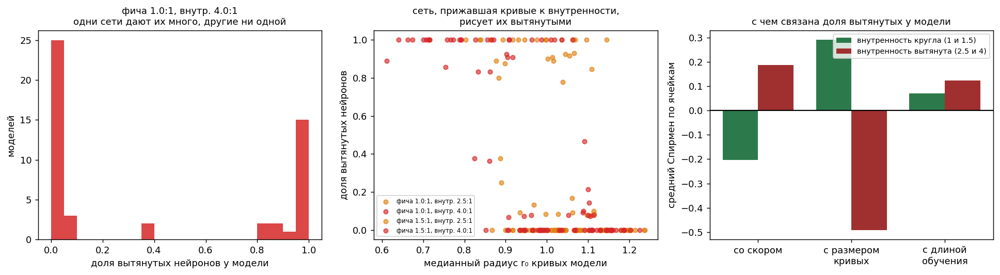

внутренность кругла (1 и 1.5): со скором -0.20, с размером кривых +0.29, с длиной обучения +0.07
внутренность вытянута (2.5 и 4): со скором +0.19, с размером кривых -0.49, с длиной обучения +0.12
фича кругла (1 и 1.5): со скором +0.37, с размером кривых -0.38, с длиной обучения +0.20
фича вытянута (2.5 и 4): со скором -0.32, с размером кривых +0.10, с длиной обучения +0.01

связь с длиной обучения не выходит за шум ни в одной ячейке: |ро| от 0.06 до 0.43, медиана 0.15


In [26]:
per = (jm.groupby(["dataset_type", "model_path"])
         .agg(доля=("hi", "mean"), лучший_скор=("скор", "min"),
              медиана_r0=("r0", "median"), нейронов=("hi", "size")).reset_index())
ep = (df[(df.feature_role == "target") & (df.block == "A")]
      .assign(model_path=lambda d: d.model_path.astype(str))
      .groupby(["dataset_type", "model_path"]).train_stopped_epoch.first().rename("эпох"))
per = per.merge(ep, on=["dataset_type", "model_path"])

rows = []
for name, g in per.groupby("dataset_type"):
    if g.доля.std() == 0:
        continue
    m = cells_meta.loc[name]
    rows.append(dict(dataset_type=name, фича=m.feature_aspect, внутр=m.interior_aspect,
                     со_скором=spearmanr(g.доля, g.лучший_скор)[0],
                     с_размером=spearmanr(g.доля, g.медиана_r0)[0],
                     с_эпохами=spearmanr(g.доля, g.эпох)[0]))
CR = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
BIG = plan_A[3]                                   # фича кругла, внутренность 4:1
g = per[per.dataset_type == BIG]
axes[0].hist(g.доля, bins=np.linspace(0, 1, 21), color=COL[4.0], alpha=.85)
axes[0].set_xlabel("доля вытянутых нейронов у модели"); axes[0].set_ylabel("моделей")
axes[0].set_title(f"{cells_meta.loc[BIG, 'label']}\nодни сети дают их много, другие ни одной",
                  fontsize=10)

for name, gg in per[per.dataset_type.isin(plan_A[2:4] + plan_A[6:8])].groupby("dataset_type"):
    axes[1].scatter(gg.медиана_r0, gg.доля, s=22, alpha=.65,
                    color=COL[cells_meta.loc[name, "interior_aspect"]],
                    label=cells_meta.loc[name, "label"])
axes[1].set_xlabel("медианный радиус r₀ кривых модели")
axes[1].set_ylabel("доля вытянутых нейронов")
axes[1].legend(fontsize=6.5)
axes[1].set_title("сеть, прижавшая кривые к внутренности,\nрисует их вытянутыми", fontsize=10)

x = np.arange(3); wdt = .38
SPLIT = [("внутренность кругла (1 и 1.5)", CR.внутр <= 1.5),
         ("внутренность вытянута (2.5 и 4)", CR.внутр > 1.5)]
for k, (lab, sel) in enumerate(SPLIT):
    vals = [CR[sel].со_скором.mean(), CR[sel].с_размером.mean(), CR[sel].с_эпохами.mean()]
    axes[2].bar(x + (k - .5)*wdt, vals, wdt, label=lab,
                color=[gp.C_GOOD, gp.C_BAD][k])
axes[2].axhline(0, color="k", lw=1.2)
axes[2].set_xticks(x, ["со скором", "с размером\nкривых", "с длиной\nобучения"])
axes[2].set_ylabel("средний Спирмен по ячейкам"); axes[2].legend(fontsize=8)
axes[2].set_title("с чем связана доля вытянутых у модели", fontsize=10)
plt.tight_layout(); plt.show()

for lab, sel in SPLIT + [("фича кругла (1 и 1.5)", CR.фича <= 1.5),
                         ("фича вытянута (2.5 и 4)", CR.фича > 1.5)]:
    s = CR[sel]
    print(f"{lab}: со скором {s.со_скором.mean():+.2f}, с размером кривых "
          f"{s.с_размером.mean():+.2f}, с длиной обучения {s.с_эпохами.mean():+.2f}")
print(f"\nсвязь с длиной обучения не выходит за шум ни в одной ячейке: "
      f"|ро| от {CR.с_эпохами.abs().min():.2f} до {CR.с_эпохами.abs().max():.2f}, "
      f"медиана {CR.с_эпохами.abs().median():.2f}")


**Наблюдения.**

- **Дело не в обучении.** Связь доли вытянутых кривых с числом эпох до остановки не выходит за
  шум: медиана |ρ| = 0.15, максимум 0.43, средние по половинам сетки +0.07 и +0.12 — без
  устойчивого знака. Сети, рисующие вытянутые кривые, не «недоучены».
- **Со скором связь есть, но она про мишень, а не про сеть.** Знак меняется вместе с фичей:
  при круглой фиче **+0.37** (больше вытянутых кривых — хуже скор), при вытянутой **−0.32**
  (больше вытянутых — лучше). Это тот же разворот, что в проверке 4 из 2.3.2, и он говорит о том,
  какая форма выгодна против данной мишени.
- **Главная связь — с тем, ГДЕ сеть ставит кривые, и она разная по половинам сетки.**
  Там, где внутренность вытянута, доля вытянутых кривых связана с медианным радиусом кривых
  модели **отрицательно, −0.49** (в отдельных ячейках до −0.85): сеть, прижавшая линии уровня к
  внутренности, рисует их вытянутыми; отпустившая наружу — круглыми. Там, где внутренность
  кругла, знак **обратный, +0.29**, и наибольшие значения — в ячейках с вытянутой фичей.
- **И оба знака предсказывает один и тот же закон раздутия** (2.2.3), без дополнительных
  гипотез. Раздутие круглой внутренности есть окружность при любом `δ` — наследовать вытянутость
  не от чего, и единственный доступный источник формы это фича, до которой ближе **бо́льшие**
  кривые: отсюда плюс. Раздутие вытянутой внутренности тем круглее, чем больше `δ`: отсюда
  минус. Закон, выведенный на медианах шестнадцати ячеек, работает и **внутри** ячейки, между
  моделями, причём в обе стороны.

**Вывод.** Отдельного «класса сетей, рисующих эллипсы» нет. Есть один параметр — на каком
расстоянии от внутренности встают линии уровня, — и он меняется и от ячейки к ячейке, и от сети
к сети внутри ячейки. Вытянутость есть его следствие, а не самостоятельное свойство. Это
объединяет 2.2.3 и 2.3.2 в одно утверждение и снимает вопрос «что особенного в этих моделях»:
особенного ничего, они просто ставят кривые ближе к внутренности.


## 2.4 Чью форму несёт кривая: ближайший нейрон модели

Вытянутость — одна координата формы. Теперь полная: расстояние по шести гармоникам с фазами
(1.2) от линии уровня до трёх эталонов.

* до **фичи** — повторяет ли кривая форму замкнутой кривой, которую нейрон якобы свидетельствует;
* до **внутренности** — повторяет ли она форму области противоположного класса;
* до **окружности** — то есть просто `|u|/√2`, длина вектора формы. Третий эталон здесь не
  украшение: если кривая не похожа ни на один из объектов, надо знать, на что она похожа, а
  «круглая» — единственная гипотеза, которую можно назвать заранее, не подглядывая в данные.

**Протокол — «есть ли у модели такой нейрон».** У каждой модели 20 нейронов на слоях 1–4; берётся
тот, что ближе всего к эталону, и модель считается один раз. Это тот же протокол, которым
эксперименты 1, 2 и 4 считали свидетелей: единица наблюдения — модель, значение — её лучший
нейрон. Вопрос ставится так: **встречается ли в сети нейрон такой формы**, а не «какова форма
типичного нейрона».

**Порог 0.144 — это соглашение, а не измеренная ошибка.** Он взят как расстояние между
окружностью и эллипсом 1.5:1, то есть как наименьшая разница форм, которую дизайн эксперимента
обязан различать (1.3). Ниже показаны и доли при этом пороге, и **сами расстояния**: если
распределения лежат далеко от 0.144 с обеих сторон, выбор порога ни на что не влияет, а если
жмутся к нему — влияет, и это будет видно.


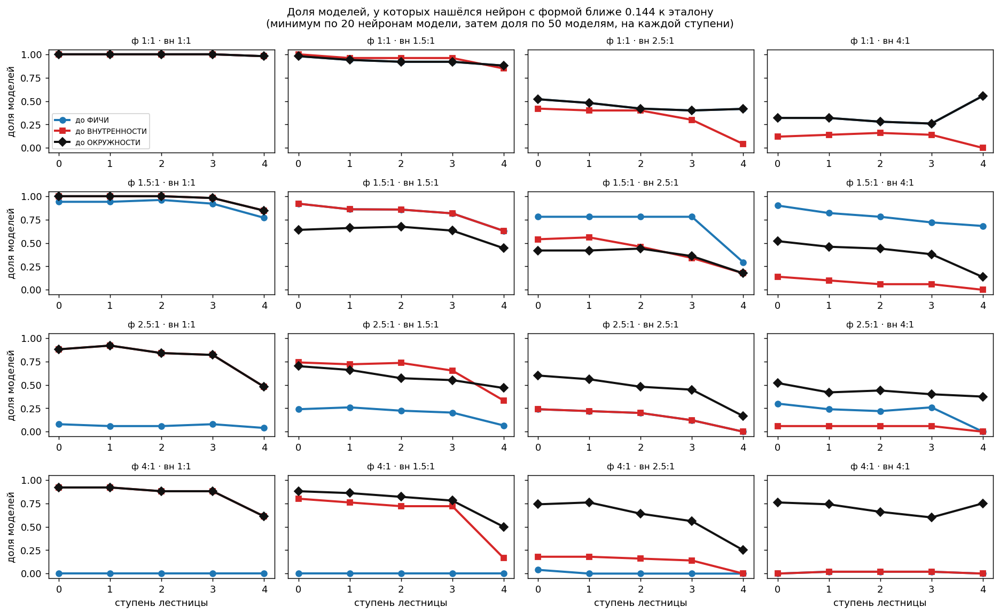

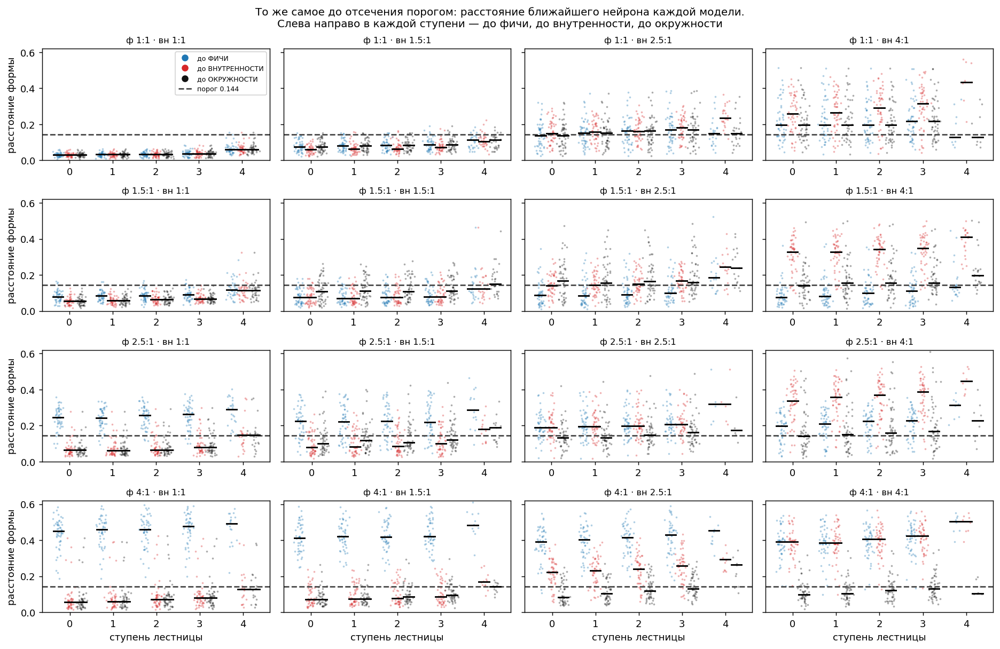

СРЕДНЯЯ СТУПЕНЬ — доля моделей, у которых есть нейрон ближе 0.144:

до ФИЧИ:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  0.92  0.42  0.28
1.5              0.96  0.86  0.78  0.78
2.5              0.06  0.22  0.20  0.22
4.0              0.00  0.00  0.00  0.02

до ВНУТРЕННОСТИ:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  0.96  0.40  0.16
1.5              1.00  0.86  0.46  0.06
2.5              0.84  0.73  0.20  0.06
4.0              0.88  0.72  0.16  0.02

до ОКРУЖНОСТИ:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  0.92  0.42  0.28
1.5              1.00  0.67  0.44  0.44
2.5              0.84  0.57  0.48  0.44
4.0              0.88  0.82  0.64  0.66

медиана самого расстояния на средней ступени (не доля):

до ФИЧИ:
interior_aspect    1.0    1.5    2.5    4.0
feature_aspect                             
1.0           

In [27]:
TH = 0.144
REFS = [("dfeat", "до ФИЧИ", gp.C_FEATURE, "o"),
        ("dint", "до ВНУТРЕННОСТИ", gp.C_INTERIOR, "s"),
        ("d_circle", "до ОКРУЖНОСТИ", gp.C_CURVE, "D")]

# у каждой модели на каждой ступени — ближайший к эталону нейрон
per = (sub.groupby(["dataset_type", "feature_aspect", "interior_aspect",
                    "model_index", "rung"])
          .agg(**{c: (c, "min") for c, *_ in REFS},
               нейронов=("dfeat", "size")).reset_index())

frac = (per.groupby(["dataset_type", "feature_aspect", "interior_aspect", "rung"])
        .agg(**{c: (c, lambda s: (s < TH).mean()) for c, *_ in REFS},
             моделей=("dfeat", "size")).reset_index())

fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.0), sharey=True)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = frac[frac.dataset_type == name].sort_values("rung")
    for col, lab, colr, mk in REFS:
        ax.plot(g.rung, g[col], mk + "-", color=colr, lw=2.2, ms=6, label=lab)
    ax.set_ylim(-.05, 1.05); ax.set_xticks(range(5))
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ступень лестницы")
for ax in axes[:, 0]:
    ax.set_ylabel("доля моделей")
axes[0, 0].legend(fontsize=7.5)
fig.suptitle(f"Доля моделей, у которых нашёлся нейрон с формой ближе {TH} к эталону\n"
             "(минимум по 20 нейронам модели, затем доля по 50 моделям, на каждой ступени)",
             fontsize=11)
plt.tight_layout(); plt.show()

# то же самое до отсечения порогом: сами расстояния, по одной точке на модель
fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.5), sharey=True)
rng = np.random.default_rng(2)
offs = {"dfeat": -.26, "dint": 0.0, "d_circle": .26}
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = per[per.dataset_type == name]
    for col, lab, colr, mk in REFS:
        for j in range(5):
            v = g[g.rung == j][col].dropna()
            if not len(v):
                continue
            ax.scatter(rng.normal(j + offs[col], .055, len(v)), v, s=4, alpha=.35,
                       color=colr, linewidths=0)
            ax.plot([j + offs[col] - .12, j + offs[col] + .12], [v.median()]*2,
                    color="k", lw=1.6, zorder=5)
    ax.axhline(TH, color="#444", ls="--", lw=1.5)
    ax.set_xticks(range(5)); ax.set_ylim(0, .62)
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ступень лестницы")
for ax in axes[:, 0]:
    ax.set_ylabel("расстояние формы")
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=l)
                           for _, l, c, _ in REFS]
                  + [plt.Line2D([], [], ls="--", color="#444", label=f"порог {TH}")],
                  fontsize=7)
fig.suptitle("То же самое до отсечения порогом: расстояние ближайшего нейрона каждой модели.\n"
             "Слева направо в каждой ступени — до фичи, до внутренности, до окружности",
             fontsize=11)
plt.tight_layout(); plt.show()

m2 = frac[frac.rung == 2].copy()
print(f"СРЕДНЯЯ СТУПЕНЬ — доля моделей, у которых есть нейрон ближе {TH}:")
for col, lab, *_ in REFS:
    print(f"\n{lab}:")
    print(m2.pivot(index="feature_aspect", columns="interior_aspect", values=col)
          .round(2).to_string())
m2 = m2.rename(columns={"dfeat": "ф", "dint": "в", "d_circle": "круг"})
print("\nмедиана самого расстояния на средней ступени (не доля):")
pm = per[per.rung == 2]
for col, lab, *_ in REFS:
    print(f"\n{lab}:")
    print(pm.pivot_table(index="feature_aspect", columns="interior_aspect", values=col,
                         aggfunc="median").round(3).to_string())


**Наблюдения.**

- **Форма фичи есть у нейронов ровно тогда, когда фича кругла.** Вниз по первому столбцу
  (внутренность круглая) доля моделей с нейроном формы фичи идёт **1.00 → 0.96 → 0.06 → 0.00**.
  При фиче 2.5:1 и 4:1 таких нейронов практически нет ни у одной из 50 моделей.
- **Форма внутренности есть у нейронов ровно тогда, когда кругла сама внутренность.** Вправо по
  первой строке (фича кругла, вытягивается внутренность) доля моделей с нейроном формы
  внутренности идёт **1.00 → 0.96 → 0.40 → 0.16**. То же падение, что у фичи в предыдущем пункте,
  только вдоль другой оси.
- **Форма окружности есть почти везде.** В первом столбце 1.00 · 1.00 · 0.84 · 0.88, а в самой
  тяжёлой ячейке «оба 4:1» — **0.66** против 0.02 и 0.02 у двух объектов. Ниже всего значение
  0.28, и оно в ячейке «фича круглая, внутренность 4:1», где «окружность» и «фича» — одно и то
  же, так что этот минимум не про окружность, а про то, что в этой ячейке трудно всё.
- **Проверка самой себя.** В верхней строке «до фичи» и «до окружности» совпадают до последнего
  знака — фича там и есть окружность. Прибор обязан был дать это тождество и дал.
- **Порог почти нигде не решает.** Вторая фигура показывает сами расстояния. В нижнем левом углу
  (фича 4:1, внутренность кругла) до фичи 0.46, а до окружности 0.06 — разница в семь раз, и
  никакой порог между 0.1 и 0.3 ничего не изменит. Единственная зона, где порог действительно
  работает, — верхний правый угол (фича кругла, внутренность 2.5:1 и 4:1): там все три
  расстояния лежат в 0.16–0.29, то есть прямо на пороге, и доли в этих трёх ячейках надо читать
  как «примерно половина», а не как точное число.
- **Вдоль лестницы картина устойчива**: линии почти горизонтальны на ступенях 0–3. Ступень 4
  выпадает там, где она есть у немногих.

**Вывод.** Ни один из двух объектов не описывает форму линии уровня во всей сетке. Описывает её
**окружность**: единственный эталон, у которого доля не падает до нуля ни в одной ячейке. Это не
значит, что сеть «стремится к круглому», — сказать так, не имея абляции, нельзя. Сказать можно
следующее: **типичная линия уровня остаётся близкой к круглой при любой форме обоих объектов и
совпадает с объектом ровно тогда, когда сам объект близок к круглому.** Слово «типичная» здесь не
смягчение, а часть утверждения: у меньшинства нейронов кривая устойчиво вытянута (до трети в
некоторых ячейках), это отдельная популяция, и разбирается она в 2.3.


## 2.5 Ориентация: куда именно вытянута кривая

Расстояние формы учитывает фазу, но в одно число её не увидеть, а ориентация — вопрос более
чувствительный, чем величина. В блоке A **оба объекта вытянуты вдоль оси x**, поэтому по
ориентации нельзя отличить «следует за фичей» от «следует за внутренностью» — обе гипотезы
предсказывают одно и то же. Различает их блок B, где внутренность повёрнута поперёк.

Здесь ориентация нужна для другого: она говорит, **осмысленна ли вытянутость вообще**. Кривая с
вытянутостью 2, направленной куда попало от нейрона к нейрону, и кривая с вытянутостью 2, всегда
направленной вдоль объектов, — это два разных факта, а по величине `a₂` они неразличимы.

**Как считается.** Радиальный профиль раскладывается в ряд, и вторая гармоника даёт
`a₂·cos(2(θ − φ₂))`. Максимум профиля приходится на `θ = φ₂` (по модулю π), поэтому направление
большой оси — это в точности `φ₂ mod π`. Заметьте: **углы здесь — направления, а не векторы**,
0° и 180° — одно и то же направление.

Ориентация определена только тогда, когда вытянутость реальна: у почти круглой кривой большая ось
неустойчива и её угол — шум. Поэтому в счёт идут кривые с `a₂ ≥ 0.10` (вытянутость от 1.22), а
доля отброшенных печатается.

**Сначала — проверка самого измерения** на четырёх кривых, у которых ответ известен заранее.


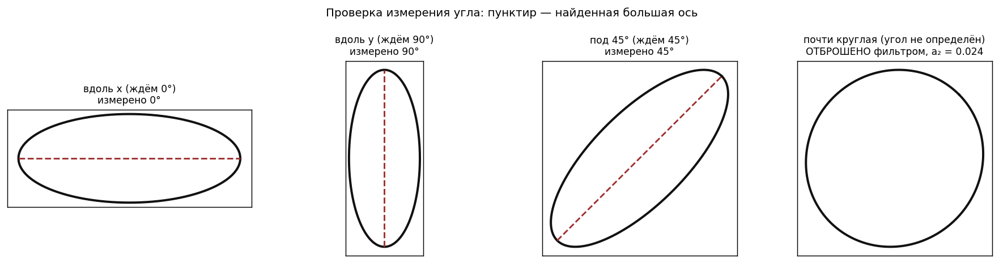

In [28]:
GATE = .10
ANG = np.linspace(0, 2*np.pi, 721)[:-1]

def ellipse(a, b, rot=0.0):
    p = np.stack([a*np.cos(ANG), b*np.sin(ANG)], 1)
    if rot:
        c_, s_ = np.cos(rot), np.sin(rot)
        p = p @ np.array([[c_, -s_], [s_, c_]]).T
    return p

CHECKS = [(2.5, 1.0, 0.0, "вдоль x", "ждём 0°"),
          (1.0, 2.5, 0.0, "вдоль y", "ждём 90°"),
          (2.5, 1.0, np.pi/4, "под 45°", "ждём 45°"),
          (1.05, 1.0, np.pi/4, "почти круглая", "угол не определён")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (a, b, rot, lab, exp) in zip(axes, CHECKS):
    pts = ellipse(a, b, rot)
    ax.plot(*pts.T, color=gp.C_CURVE, lw=2.2)
    d_ = fourier_descriptor(torch.tensor(pts, dtype=torch.float32))
    ang = np.degrees(d_["phase"][2] % np.pi)
    passes = d_["amplitude"][2] >= GATE
    ok = "измерено" if passes else "ОТБРОШЕНО фильтром, a₂ ="
    val = f"{ang:.0f}°" if passes else f"{d_['amplitude'][2]:.3f}"
    if passes:                                   # у круглой оси нет — не рисуем
        L = max(a, b)
        ax.plot([-L*np.cos(np.radians(ang)), L*np.cos(np.radians(ang))],
                [-L*np.sin(np.radians(ang)), L*np.sin(np.radians(ang))],
                color=gp.C_BAD, lw=1.6, ls="--")
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{lab} ({exp})\n{ok} {val}", fontsize=9.5)
fig.suptitle("Проверка измерения угла: пунктир — найденная большая ось", fontsize=11)
plt.tight_layout(); plt.show()


Прибор возвращает ровно то, что ожидается, и на почти круглой кривой честно отказывается отвечать.

**Теперь настоящие данные.** Ниже — «роза» углов для каждой из шестнадцати ячеек. Это
**гистограмма, а не усреднение**: у каждой кривой ячейки берётся её собственный угол `φ₂`, углы
раскладываются по 36 секторам шириной 10°, и высота лепестка есть доля кривых, попавших в сектор
(каждая панель нормирована на свой максимум, поэтому сравнивать между панелями можно только
форму розы, не длину лепестков). Никакого среднего угла не считается — среднее по направлениям
плохо определено, а медиана скрыла бы именно то, ради чего картинка и рисуется: есть ли у
направлений разброс. В счёт идут все кривые ячейки, прошедшие фильтр по `a₂`: все нейроны, все
модели, все ступени.
Поскольку угол — направление, а не вектор, каждое измерение отложено дважды, при `φ` и при
`φ + 180°`, отчего роза симметрична; читать её надо как «ось», а не как «стрелку».

**Как читать.** Горизонтальный лепесток (вправо-влево) — кривая вытянута **вдоль** объектов.
Вертикальный (вверх-вниз) — **поперёк**. Равномерный круг — направления нет, вытянутость есть, но
она случайна от нейрона к нейрону. В заголовке каждой панели — доля кривых в секторе ±30° от оси
объектов и доля прошедших фильтр по `a₂`.


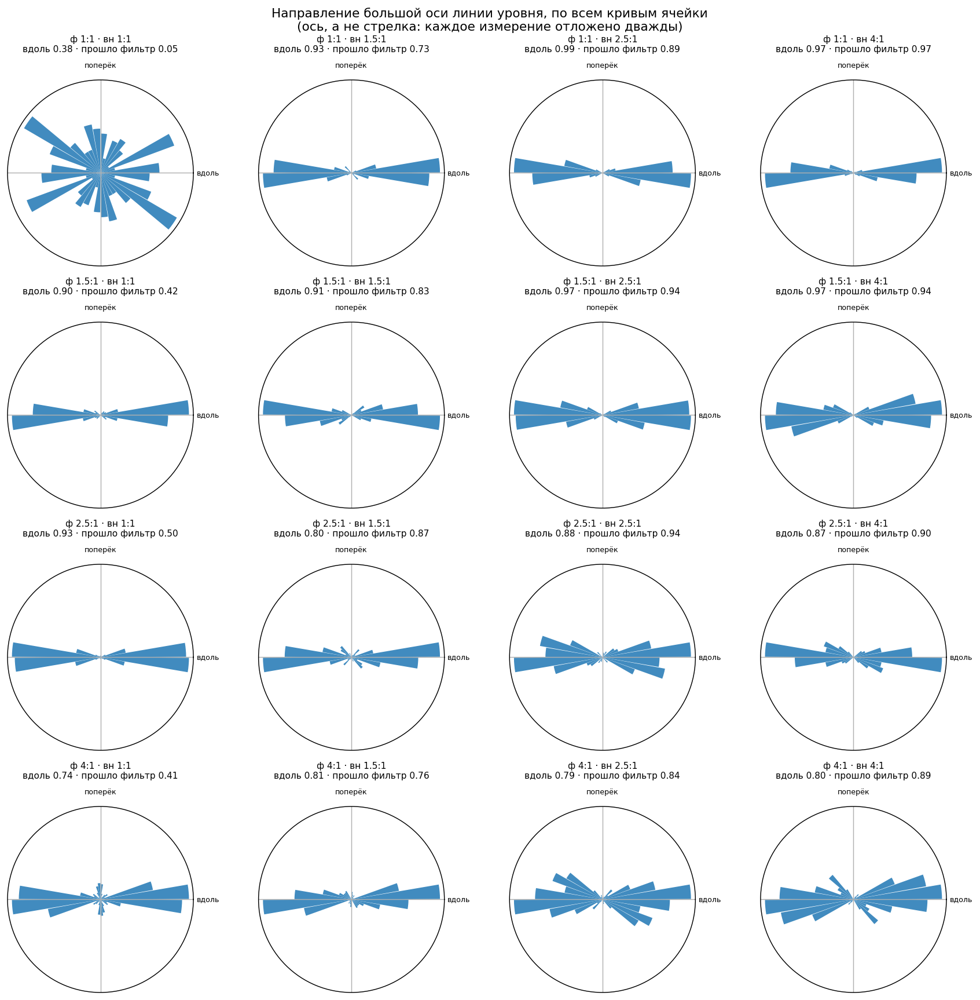

кривых всего 39718, из них с a₂ ≥ 0.1: 74%

доли по ячейкам:
 фича  внутр    n  прошло  вдоль  косо  поперёк
  1.0    1.0  144    0.05   0.38  0.33     0.29
  1.0    1.5 1800    0.73   0.93  0.06     0.01
  1.0    2.5 2121    0.89   0.99  0.00     0.00
  1.0    4.0 2130    0.97   0.97  0.03     0.00
  1.5    1.0 1139    0.42   0.90  0.10     0.01
  1.5    1.5 2058    0.83   0.91  0.08     0.01
  1.5    2.5 2351    0.94   0.97  0.03     0.00
  1.5    4.0 2464    0.94   0.97  0.03     0.00
  2.5    1.0 1240    0.50   0.93  0.03     0.03
  2.5    1.5 2192    0.87   0.80  0.17     0.03
  2.5    2.5 2336    0.94   0.88  0.09     0.03
  2.5    4.0 2315    0.90   0.87  0.12     0.01
  4.0    1.0  951    0.41   0.74  0.09     0.17
  4.0    1.5 1846    0.76   0.81  0.12     0.06
  4.0    2.5 1933    0.84   0.79  0.19     0.02
  4.0    4.0 2223    0.89   0.80  0.18     0.01

доля «вдоль» по строкам (аспект фичи):
фича
1.0    0.82
1.5    0.94
2.5    0.87
4.0    0.79
доля «вдоль» по столбцам (аспе

In [29]:
ori = sub[sub.a2 >= GATE].copy()
ori["dir"] = np.radians(ori.angle2)

fig, axes = plt.subplots(4, 4, figsize=(13.5, 13.5),
                         subplot_kw={"projection": "polar"})
edges = np.radians(np.arange(0, 361, 10))
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = ori[ori.dataset_type == name]
    allg = sub[sub.dataset_type == name]
    both = np.concatenate([g["dir"].values, g["dir"].values + np.pi]) % (2*np.pi)
    h, _ = np.histogram(both, bins=edges)
    h = h / max(h.max(), 1)
    ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4),
           color=gp.C_FEATURE, alpha=.85, edgecolor="none")
    a = g.angle2.values
    along = float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan
    ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
    ax.set_xticklabels(["вдоль", "поперёк", "", ""], fontsize=7)
    ax.set_title(f"ф {meta.feature_aspect:g}:1 · вн {meta.interior_aspect:g}:1\n"
                 f"вдоль {along:.2f} · прошло фильтр {len(g)/max(len(allg),1):.2f}",
                 fontsize=8.5, pad=9)
fig.suptitle("Направление большой оси линии уровня, по всем кривым ячейки\n"
             "(ось, а не стрелка: каждое измерение отложено дважды)", fontsize=12)
plt.tight_layout(); plt.show()

res = []
for name, g in ori.groupby("dataset_type"):
    a = g.angle2.values
    meta = cells_meta.loc[name]
    res.append(dict(фича=meta.feature_aspect, внутр=meta.interior_aspect, n=len(g),
                    прошло=len(g)/max(len(sub[sub.dataset_type == name]), 1),
                    вдоль=float(((a < 30) | (a > 150)).mean()),
                    косо=float((((a >= 30) & (a <= 60)) | ((a >= 120) & (a <= 150))).mean()),
                    поперёк=float(((a > 60) & (a < 120)).mean())))
res = pd.DataFrame(res).sort_values(["фича", "внутр"])
print(f"кривых всего {len(sub)}, из них с a₂ ≥ {GATE}: {(sub.a2 >= GATE).mean():.0%}")
print("\nдоли по ячейкам:")
print(res.round(2).to_string(index=False))
print("\nдоля «вдоль» по строкам (аспект фичи):")
print(res.groupby("фича")["вдоль"].mean().round(2).to_string())
print("доля «вдоль» по столбцам (аспект внутренности):")
print(res.groupby("внутр")["вдоль"].mean().round(2).to_string())


**Наблюдения.**

- **Контроль сработал.** В базовой ячейке «круг в круге» фильтр по `a₂` проходит лишь **5 %**
  кривых, и их роза изотропна: направление размазано по всем углам. Оба объекта круглые,
  выделенного направления нет — и прибор его не выдумал. В любой другой ячейке фильтр проходят
  41–97 % кривых.
- **Везде, где вытянутость есть, она вдоль объектов.** Доля углов в секторе ±30° от оси x —
  **0.74–0.99** по всем пятнадцати остальным ячейкам. Поперёк (90° ± 30°) — 0.00–0.03 везде,
  кроме одной ячейки.
- **Порядок в направлении растёт от внутренности, а не от фичи.** По столбцам (аспект
  внутренности) доля «вдоль» идёт 0.74 → 0.86 → 0.91 → 0.90; по строкам (аспект фичи) —
  0.82 → 0.94 → 0.87 → **0.79**, то есть у самой вытянутой фичи она наименьшая. Круглая
  внутренность и вытянутая фича (нижний левый угол) дают самую беспорядочную розу из
  непустых: «вдоль» 0.74, «поперёк» 0.17.
- **Косые направления появляются там же**, где падает порядок: 0.12–0.19 в нижней строке против
  0.00–0.03 в верхней.

**Вывод, и он ограниченный.** В блоке A **оба** объекта вытянуты вдоль оси x, поэтому «вдоль»
не различает гипотезы (а) и (б) — обе предсказывают одно и то же. Что ориентация здесь
устанавливает, так это осмысленность самой величины: вытянутость кривой не случайный шум,
у неё есть устойчивое направление, и это направление задаётся геометрией пары. Различает
гипотезы блок B, где внутренность повёрнута поперёк фичи.


## 2.6 Насколько форма меняется вдоль лестницы

До сих пор говорилось, что ступени дают примерно одно и то же, и это было видно на облаках (2.2)
и на почти горизонтальных линиях (2.4). Но обе проверки косвенные: они сравнивают **расстояния до
эталонов**, а не сами формы между собой. Две кривые могут быть одинаково далеки от фичи и при этом
совершенно разными. Прямой вопрос — насколько форма линии уровня меняется, когда мы идём от
внутренности к фиче, — до сих пор не задавался.

Меряется он двумя способами, и оба нужны:

* **накопленное изменение** — расстояние формы между кривой ступени 0 и кривой ступени 4 у
  одного и того же нейрона: насколько форма ушла за весь путь. Считается только у тех нейронов,
  у которых есть **обе** крайние ступени, а таких 14 % (1.5) — это надо помнить: выборка здесь
  смещена в сторону нейронов с широким семейством;
* **шаг между соседями** — расстояние между кривыми соседних ступеней: меняется ли форма
  постепенно или скачком.

**Третья панель — что с чем сравнивается.** По вертикали то же накопленное изменение (медиана по
ячейке). По горизонтали — `d(фича, внутренность)`, расстояние формы **между самими объектами
ячейки**, то есть насколько эта ячейка вообще ставит вопрос: на диагонали блока A объекты подобны
и это расстояние равно нулю, в углу «круг против 4:1» оно максимально. Смысл сравнения такой:
если бы форма кривой определялась тем, около какого объекта она проходит, то, проходя от одного
объекта к другому, она должна была бы измениться **примерно на различие между объектами** — то
есть точки легли бы вдоль диагонали. Насколько они ниже диагонали — настолько кривая **не
переключается** с одной формы на другую.

Все три величины считаются в одних единицах — расстояние формы по шести гармоникам с фазами — и
сравниваются с двумя масштабами: собственной ошибкой прибора (0.010) и шагом сетки аспектов
дизайна (0.144).


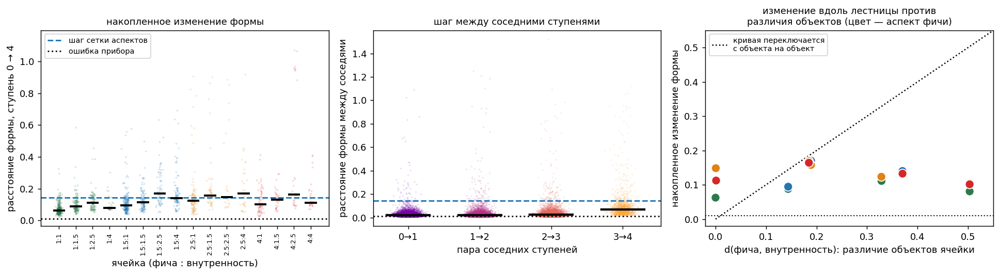

накопленное изменение формы (ступень 0 → 4): медиана 0.099, 75-й перцентиль 0.144, n = 1558
шаг между соседями: медиана 0.022
пара
0→1    0.021
1→2    0.019
2→3    0.023
3→4    0.068

различие объектов, медиана по ячейкам 0.187, максимум 0.503

Спирмен(накопленное изменение, различие объектов) = +0.068, p = 0.80, n = 16

накопленное изменение по ячейкам (медиана) против различия объектов:
 feature_aspect  interior_aspect  накопл  objects_shape
            1.0              1.0   0.062          0.000
            1.0              1.5   0.088          0.144
            1.0              2.5   0.111          0.329
            1.0              4.0   0.081          0.503
            1.5              1.0   0.094          0.144
            1.5              1.5   0.114          0.000
            1.5              2.5   0.170          0.189
            1.5              4.0   0.140          0.370
            2.5              1.0   0.123          0.328
            2.5              1.5   0.158        

In [30]:
# полный вектор формы: шесть гармоник с фазами, как в определении расстояния (1.2)
UC = [f"u{k}{ax}" for k in range(1, 7) for ax in ("c", "s")]
key = ["dataset_type", "model_index", "layer_id", "coord_id"]
wide = sub.pivot_table(index=key, columns="rung", values=UC)
acc, step = [], []
for idx, r in wide.iterrows():
    v = {}
    for j in range(5):
        vec = np.array([r[(u, j)] for u in UC])
        if np.isfinite(vec).all():
            v[j] = vec
    if 0 in v and 4 in v:
        acc.append(dict(dataset_type=idx[0], d=float(np.linalg.norm(v[4]-v[0])/np.sqrt(2))))
    for j in range(4):
        if j in v and j+1 in v:
            step.append(dict(dataset_type=idx[0], пара=f"{j}→{j+1}",
                             d=float(np.linalg.norm(v[j+1]-v[j])/np.sqrt(2))))
acc = pd.DataFrame(acc).merge(cells[["dataset_type", "feature_aspect", "interior_aspect"]],
                              on="dataset_type")
step = pd.DataFrame(step).merge(cells[["dataset_type", "feature_aspect", "interior_aspect"]],
                                on="dataset_type")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = sorted(acc.groupby(["feature_aspect", "interior_aspect"]).groups)
rng = np.random.default_rng(1)
for i, (fa, ia) in enumerate(order):
    v = acc[(acc.feature_aspect == fa) & (acc.interior_aspect == ia)].d
    axes[0].scatter(rng.normal(i, .08, len(v)), v, s=4, alpha=.18, color=COL[fa],
                    linewidths=0)
    axes[0].plot([i-.3, i+.3], [v.median()]*2, color="k", lw=2.2, zorder=4)
axes[0].axhline(.144, color=gp.C_FEATURE, ls="--", lw=1.6, label="шаг сетки аспектов")
axes[0].axhline(.010, color=gp.C_CURVE, ls=":", lw=1.6, label="ошибка прибора")
axes[0].set_xticks(range(len(order)), [f"{a:g}:{b:g}" for a, b in order], fontsize=7, rotation=90)
axes[0].set_xlabel("ячейка (фича : внутренность)")
axes[0].set_ylabel("расстояние формы, ступень 0 → 4")
axes[0].legend(fontsize=8); axes[0].set_title("накопленное изменение формы", fontsize=10)

for i, p in enumerate(["0→1", "1→2", "2→3", "3→4"]):
    v = step[step["пара"] == p].d
    axes[1].scatter(rng.normal(i, .08, len(v)), v, s=3, alpha=.14, color=ramp[i+1],
                    linewidths=0)
    axes[1].plot([i-.3, i+.3], [v.median()]*2, color="k", lw=2.4, zorder=4)
axes[1].axhline(.144, color=gp.C_FEATURE, ls="--", lw=1.6)
axes[1].axhline(.010, color=gp.C_CURVE, ls=":", lw=1.6)
axes[1].set_xticks(range(4), ["0→1", "1→2", "2→3", "3→4"])
axes[1].set_xlabel("пара соседних ступеней")
axes[1].set_ylabel("расстояние формы между соседями")
axes[1].set_title("шаг между соседними ступенями", fontsize=10)

both = acc.groupby(["feature_aspect", "interior_aspect"]).d.median().rename("накопл").reset_index()
obj = (gs.shape_by_cell(gs.ladder_long(df, "value")).query("rung == 2 and block == 'A'")
       .groupby(["feature_aspect", "interior_aspect"]).objects_shape.first().reset_index())
both = both.merge(obj, on=["feature_aspect", "interior_aspect"])
axes[2].scatter(both.objects_shape, both["накопл"], s=90,
                c=[COL[f] for f in both.feature_aspect], edgecolor="white", zorder=3)
axes[2].plot([0, .55], [0, .55], ls=":", color="k", lw=1.4,
             label="кривая переключается\nс объекта на объект")
axes[2].axhline(.010, color=gp.C_CURVE, ls=":", lw=1.2)
axes[2].set_xlabel("d(фича, внутренность): различие объектов ячейки")
axes[2].set_ylabel("накопленное изменение формы")
axes[2].set_xlim(-.02, .55); axes[2].set_ylim(-.02, .55); axes[2].legend(fontsize=8)
axes[2].set_title("изменение вдоль лестницы против\nразличия объектов (цвет — аспект фичи)",
                  fontsize=10)
plt.tight_layout(); plt.show()

print(f"накопленное изменение формы (ступень 0 → 4): медиана {acc.d.median():.3f}, "
      f"75-й перцентиль {acc.d.quantile(.75):.3f}, n = {len(acc)}")
print(f"шаг между соседями: медиана {step.d.median():.3f}")
print(step.groupby('пара').d.median().round(3).to_string())
print(f"\nразличие объектов, медиана по ячейкам {obj.objects_shape.median():.3f}, "
      f"максимум {obj.objects_shape.max():.3f}")
from scipy.stats import spearmanr
rho, pv = spearmanr(both["накопл"], both.objects_shape)
print(f"\nСпирмен(накопленное изменение, различие объектов) = {rho:+.3f}, "
      f"p = {pv:.2f}, n = {len(both)}")
print("\nнакопленное изменение по ячейкам (медиана) против различия объектов:")
print(both.round(3).to_string(index=False))


**Наблюдения.**

- **Форма почти не меняется вдоль семейства.** Накопленное изменение от внутренней ступени к
  внешней: медиана **0.099**, 75-й перцентиль 0.144. То есть у трёх нейронов из четырёх вся
  дорога от внутренности до фичи меняет форму меньше, чем на один шаг сетки аспектов дизайна.
- **Меняется постепенно, кроме последнего шага.** Соседние ступени расходятся на 0.021 · 0.019 ·
  0.023 · **0.068**: первые три шага одинаковы и малы, последний втрое больше. Внешняя ступень —
  и самая редкая (10 %), и самая непохожая на остальные; это согласуется с тем, что там кривая
  подходит к краю окна и к области, где поле уже вышло на плато.
- **Изменение формы никак не связано с тем, насколько различаются объекты.** Спирмен между
  медианным накопленным изменением ячейки и `d(фича, внутренность)` равен **+0.07** при p = 0.80
  на 16 ячейках. Накопленное изменение лежит в узком коридоре 0.062–0.170, тогда как различие
  объектов меняется от 0 до 0.503 — то есть в восемь раз больше. На третьей панели это видно
  прямо: все точки лежат под диагональю и почти не поднимаются вправо.
- **Оговорка о выборке.** Накопленное изменение считается только у 14 % нейронов — тех, у кого
  есть обе крайние ступени (1.5). Эта подвыборка смещена в сторону нейронов с широким
  семейством кривых. Шаг между соседями такого смещения не имеет и даёт тот же ответ.

**Вывод.** Если бы форма кривой определялась тем, около какого объекта она сейчас проходит, то
на пути от внутренности к фиче она менялась бы примерно на различие между ними. Она меняется на
одну и ту же малую величину независимо от этого различия. **Семейство линий уровня одного нейрона
имеет одну форму, а не переключается с формы одного объекта на форму другого.**


## 2.7 Что говорят два прежних критерия

Дескриптор ответил на вопрос блока. Теперь структурный и гомологический критерии, ради сшивки с
экспериментами 1, 2 и 4: они меряют не форму, а совпадение с мишенью, и их поведение должно быть
согласовано с найденным. Протокол у структурного критерия тот же, что и выше — лучший нейрон
модели, затем доля моделей, — поэтому числа прямо сравнимы.

Показаны **распределения, а не линии по ячейкам**. Причина простая: доля свидетелей — это одно
число, полученное отсечением распределения порогом, и по нему нельзя отличить «мишень уехала от
нулей» от «мишень и нули лежат вместе, а порог оказался посередине». Ячейка за ячейкой видно и
то, и другое. Сами доли остаются в таблицах под картинками.

Гомологический критерий читается **в другую сторону**: у него больше — лучше, поэтому работа
критерия выглядит как мишень СПРАВА от нулей.


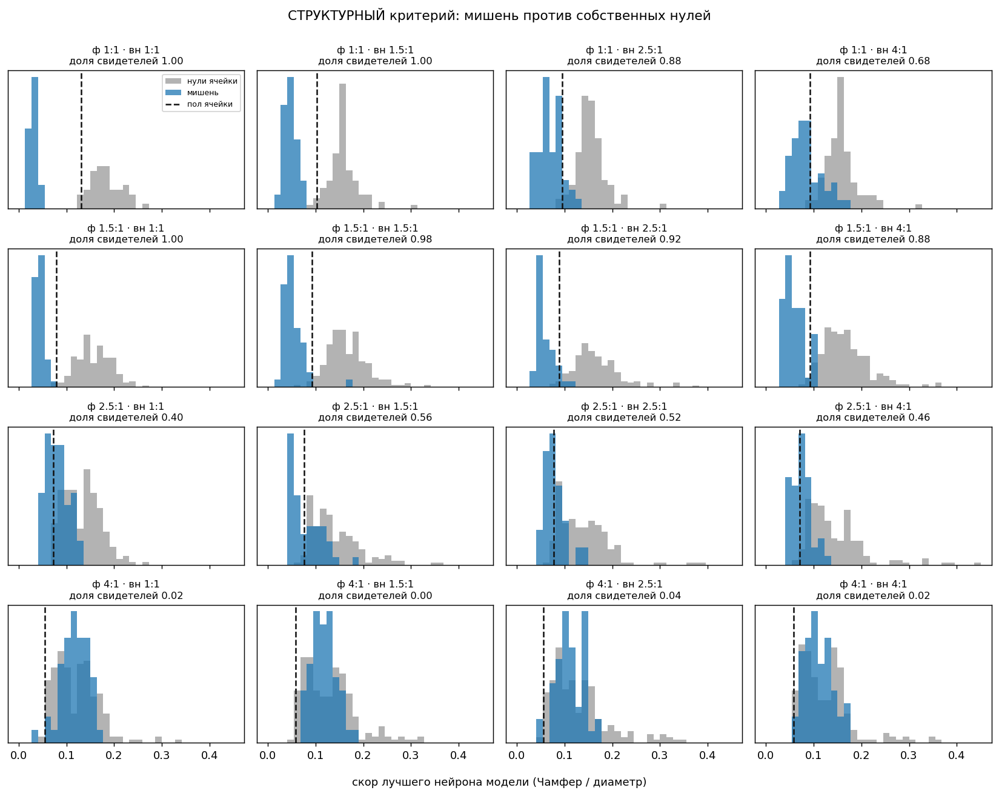

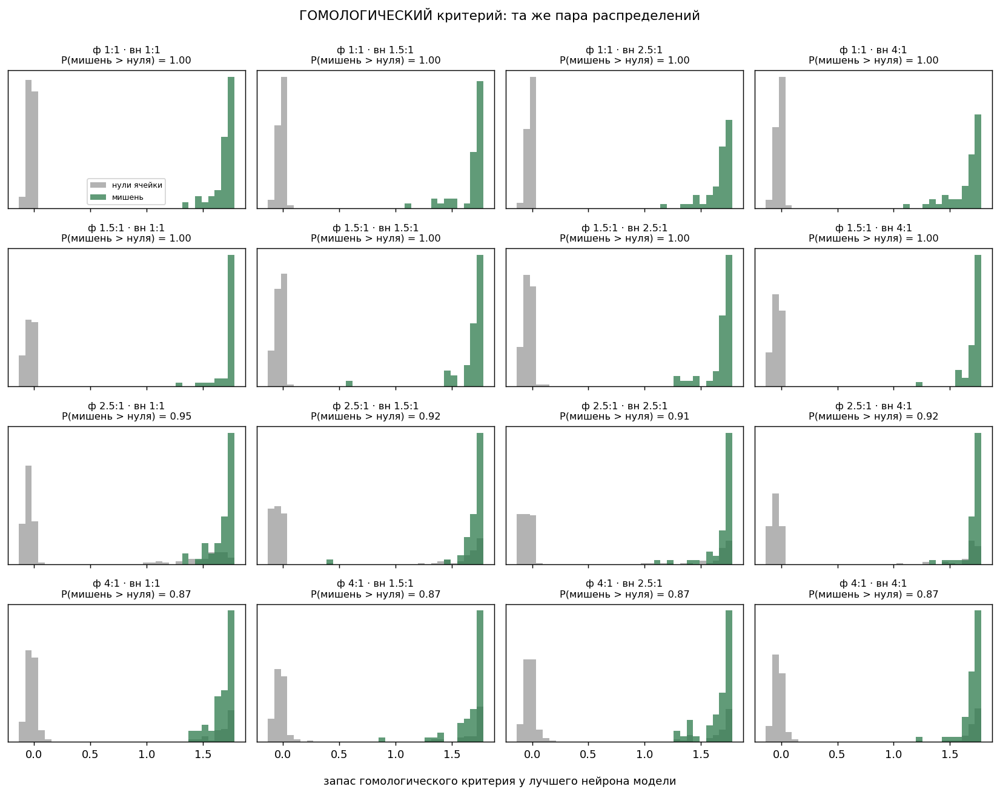

структурный критерий по строкам (среднее по строке):
                rate_floor  rate_p5
feature_aspect                     
1.0                  0.890     0.93
1.5                  0.945     0.98
2.5                  0.485     0.60
4.0                  0.020     0.03

структурный критерий по ячейкам — доля свидетелей:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  1.00  0.88  0.68
1.5              1.00  0.98  0.92  0.88
2.5              0.40  0.56  0.52  0.46
4.0              0.02  0.00  0.04  0.02

медиана скора лучшего нейрона (в скобках — пол ячейки):
  фича 1:1: вн 1 → 0.030 (0.131)   вн 1.5 → 0.045 (0.102)   вн 2.5 → 0.065 (0.095)   вн 4 → 0.079 (0.092)
  фича 1.5:1: вн 1 → 0.043 (0.078)   вн 1.5 → 0.049 (0.093)   вн 2.5 → 0.051 (0.088)   вн 4 → 0.054 (0.092)
  фича 2.5:1: вн 1 → 0.081 (0.072)   вн 1.5 → 0.067 (0.077)   вн 2.5 → 0.076 (0.077)   вн 4 → 0.072 (0.070)
  фича 4:1: вн 1 → 0.121 (0.055)   вн 1.5 → 0.117 (0.058)   

feature_role     null  target
feature_aspect               
1.0             0.798   0.360
1.5             0.748   0.281
2.5             0.530   0.240
4.0             0.356   0.238

для сравнения — доля моделей с нейроном формы фичи (дескриптор, средняя ступень):
feature_aspect
1.0    0.655
1.5    0.844
2.5    0.176
4.0    0.005


In [31]:
Ac = cells[cells.block == "A"]
titles_A = [f"ф {r.feature_aspect:g}:1 · вн {r.interior_aspect:g}:1"
            for r in cells_meta.loc[plan_A].itertuples()]

gp.plot_score_panels(best, plan_A, titles_A, floors=floors, ncols=4,
                     suptitle="СТРУКТУРНЫЙ критерий: мишень против собственных нулей")
plt.show()

# гомологический: у него лучший нейрон — с НАИБОЛЬШИМ запасом
hm = (df[df.block == "A"]
      .groupby(["dataset_type", "feature_role", "feature_name", "model_path"])
      .homological_persistence_margin.max().rename("margin").reset_index())
gp.plot_margin_panels(hm, plan_A, titles_A, ncols=4,
                      suptitle="ГОМОЛОГИЧЕСКИЙ критерий: та же пара распределений")
plt.show()

print("структурный критерий по строкам (среднее по строке):")
print(Ac.groupby("feature_aspect")[["rate_floor", "rate_p5"]].mean().round(3).to_string())
print("\nструктурный критерий по ячейкам — доля свидетелей:")
print(Ac.pivot(index="feature_aspect", columns="interior_aspect", values="rate_floor")
      .round(2).to_string())
print("\nмедиана скора лучшего нейрона (в скобках — пол ячейки):")
piv_s = Ac.pivot(index="feature_aspect", columns="interior_aspect", values="target_median")
piv_f = Ac.pivot(index="feature_aspect", columns="interior_aspect", values="floor")
for fa in piv_s.index:
    print(f"  фича {fa:g}:1: " + "   ".join(
        f"вн {ia:g} → {piv_s.loc[fa, ia]:.3f} ({piv_f.loc[fa, ia]:.3f})"
        for ia in piv_s.columns))

t_all = df[(df.feature_role == "target") & (df.block == "A")]
print("\nгомологический критерий по аспекту фичи:")
print(t_all.groupby("feature_aspect").agg(
    доля_нейронов=("homological_is_witness", "mean"),
    медиана_маржи=("homological_persistence_margin", "median")).round(3).to_string())
print("\nдоля ПУСТЫХ диаграмм (петли не найдено вовсе), по аспекту фичи:")
print(df[df.block == "A"].assign(
    пусто=lambda d: d.homological_persistence_margin.isna())
    .pivot_table(index="feature_aspect", columns="feature_role", values="пусто")
    .round(3).to_string())

print("\nдля сравнения — доля моделей с нейроном формы фичи (дескриптор, средняя ступень):")
print(m2.pivot(index="feature_aspect", columns="interior_aspect", values="ф").mean(axis=1)
      .round(3).to_string())


**Наблюдения.**

- **Структурный критерий воспроизводит найденное дескриптором.** Доля моделей со свидетелем
  падает по строкам **0.89 → 0.95 → 0.49 → 0.02** с вытягиванием фичи; доля моделей с нейроном
  **формы** фичи идёт 0.66 → 0.84 → 0.18 → 0.005. Два прибора, разные величины, один и тот же
  перелом между аспектами 1.5 и 2.5.
- **Пол движется навстречу скору.** У круглой фичи пол 0.092–0.131, у фичи 4:1 — 0.055–0.058:
  у вытянутой мишени случайно приблизиться легче, и абсолютный скор 0.106 при фиче 4:1 — это
  вдвое ХУЖЕ пола, тогда как 0.030 при круглой — вчетверо лучше. Это и есть причина, по которой
  доля считается по собственному полу ячейки, а `τ = 0.1` здесь не применима.
- **Гомологический критерий работает во всех шестнадцати ячейках.** `P(мишень > нуля)` равно
  **1.00** в двух верхних строках, 0.91–0.95 в третьей и **0.87** в нижней. Распределения
  разнесены: у мишени запас лучшего нейрона собран у 1.7, у нулей — у нуля.
- **Но и он слабеет с вытягиванием фичи, только иначе.** Медиана запаса по всем нейронам падает
  0.96 → 0.86 → 0.77 → 0.69, а доля пустых диаграмм **у нулей** падает 0.80 → 0.75 → 0.53 →
  0.36: чем вытянутее мишень, тем чаще петля находится и у нулевого размещения. Слабеет,
  следовательно, не чувствительность, а специфичность.
- **Доля нейронов, у которых критерий срабатывает, действительно плоская**: 0.546 · 0.562 ·
  0.575 · 0.565. Замкнутая петля есть у половины нейронов при любой геометрии.

**Вывод.** Три прибора согласованы и говорят разное о разном. Замкнутая петля у нейрона есть
всегда, и она отличима от нулевой — гомологический критерий. Совпадает она с фичей только когда
та кругла — структурный. **Почему** не совпадает — форма кривой задана не фичей — дескриптор.


## 2.8 Итог блока A

Всё считано по одному правилу: минимум по нейронам внутри модели, затем распределение по 50
моделям; порог похожести — шаг сетки аспектов дизайна 0.144. Данные — пересчитанная лестница по
всем 10 905 нейронам блока (39 718 кривых), лестница **по значению поля**.

1. **Форму линии уровня задаёт прежде всего не фича.** При вытянутой фиче форму фичи не несёт
   почти ни один нейрон ни у одной модели: доля моделей 0.00–0.02 при аспекте 4:1 и 0.06–0.22 при
   2.5:1, на всех пяти ступенях (2.4). Предельный эффект вытянутости фичи на вытянутость кривой —
   **0.14** при её собственном размахе 3.0, и ряд даже не монотонен (2.2). Но нулю этот эффект не
   равен, и виден он чище всего там, где внутренность кругла и не перебивает его: в первом столбце
   сетки медиана вытянутости поднимается с **1.05** («круг в круге») до **1.20 / 1.23 / 1.19** при
   фиче 1.5 / 2.5 / 4:1. То есть фича кривую вытягивает — просто втрое слабее внутренности и без
   монотонного продолжения.
2. **Отклик на внутренность есть, он монотонен, но слаб.** Предельный эффект внутренности —
   **0.46**, втрое больше эффекта фичи и по порядку (2.2). Форму внутренности несут 0.84–1.00
   моделей, когда её аспект 1:1, и 0.02–0.16, когда 4:1 (2.4).
3. **Кривая остаётся близкой к окружности.** Это единственный из трёх эталонов, чья доля не
   падает до нуля нигде: 0.28–1.00 по всем шестнадцати ячейкам. В ячейке «оба 4:1», где до фичи
   и до внутренности по 0.02, до окружности **0.66** (2.4). Медианная вытянутость кривой по
   ячейкам — 1.05–1.85 при объектах 1–4 (2.2).
4. **Вытянутость кривой не случайна, но и она задаётся внутренностью.** Направление большой оси
   лежит вдоль общей оси объектов у 0.74–0.99 кривых; порядок в направлении растёт с
   вытянутостью **внутренности** (0.74 → 0.90) и слабеет с вытянутостью **фичи** (0.82 → 0.79).
   В базовой ячейке, где оба объекта круглые, роза изотропна — контроль прибора. Различить (а) и
   (б) ориентацией в блоке A нельзя: объекты делят одну ось (2.5).
5. **Семейство линий уровня одного нейрона имеет ОДНУ форму.** Накопленное изменение от ступени
   0 к ступени 4 — медиана **0.099** при 75-м перцентиле 0.144, и оно **никак не связано** с
   различием объектов ячейки: Спирмен +0.07 при p = 0.80, коридор 0.062–0.170 против размаха
   различия 0–0.503 (2.6). Кривая не переключается с формы одного объекта на форму другого.
6. **Прежние критерии согласованы и добавляют своё.** Структурный даёт тот же перелом между
   аспектами 1.5 и 2.5. Гомологический разделяет мишень и нули во всех ячейках
   (`P` = 0.87–1.00), но с вытягиванием фичи теряет **специфичность**: доля пустых диаграмм у
   нулей падает 0.80 → 0.36 (2.7).
7. **Внутри модели нейроны почти взаимозаменяемы.** Лучший и медианный по скору нейроны — всегда
   разные нейроны, но их кривые расходятся по форме медианно на 0.025, вшестеро меньше шага
   дизайна (2.1).

**Чего блок A сказать не может.** Во всех шестнадцати ячейках внутренность помещается в
окружность, вписанную в фичу, — значит круглая линия уровня **разделяет классы** везде, и сеть
никогда не обязана строить другую. Поэтому «форму задаёт не фича» здесь неотделимо от «фича не
требует иной формы». Что из двух верно, блок A не решает; это разбирается в
`exp5_new_datasets_decision.ipynb`.

Второе ограничение — **абляции нет**, поэтому всё сказанное есть утверждение о **выравнивании**:
форма линий уровня согласована с геометрией пары так-то и так-то. Что нейрон «кодирует» форму,
из этого не следует и здесь не утверждается.


# 3. Блок B. Ориентация: тот же вопрос, поставленный жёстко

## Постановка

Блок A не мог различить две гипотезы. В нём **оба объекта вытянуты вдоль оси x**, поэтому
«кривая следует за фичей» и «кривая следует за внутренностью» предсказывают одно и то же
направление. Различить их можно только развернув объекты относительно друг друга — этим блок B
и занимается.

**Сетка та же, 4 × 4**, и собирается она из трёх источников:

* **девять ячеек обучены заново** — вытянутость фичи × вытянутость внутренности по ряду
  1.5 / 2.5 / 4, внутренность повёрнута на 90°. Только здесь объекты действительно конкурируют;
* **четыре ячейки первого столбца** (внутренность круглая) берутся из блока A как есть: поворот
  круга ничего не меняет. Это **контроль фичи**: у кривой нет оси от внутренности, и если
  направление всё-таки есть, его задала фича;
* **три ячейки первой строки** (фича круглая) берутся из блока A **повёрнутыми на 90°**: круглая
  фича инвариантна к повороту, поэтому такая ячейка и есть ⊥-версия себя самой. Это **контроль
  внутренности**: оси от фичи нет, направление может задать только внутренность.

Такая сборка даёт то, чего не даёт ни один из блоков по отдельности: **два края сетки измеряют
вклад каждого объекта поодиночке, а середина — что происходит, когда они спорят.**

**Что здесь измеряется.** В блоке A основной величиной была вытянутость, здесь — **направление
большой оси кривой**. Оно и есть прямой ответ: 0° означает «за фичей», 90° — «за внутренностью».
Для трёх повёрнутых ячеек измеренный угол разворачивается на 90° вместе с датасетом.

Протокол тот же: лестница по значению поля, все нейроны слоёв 1–4 всех 50 моделей, угол считается
только у кривых с `a₂ ≥ 0.10`, доля прошедших фильтр печатается.


## 3.1 Датасеты

Шестнадцать конфигураций. Первый столбец — внутренность круглая (взято из блока A), первая строка — круглая фича (блок A, повёрнутый на 90°), остальные девять обучены заново.


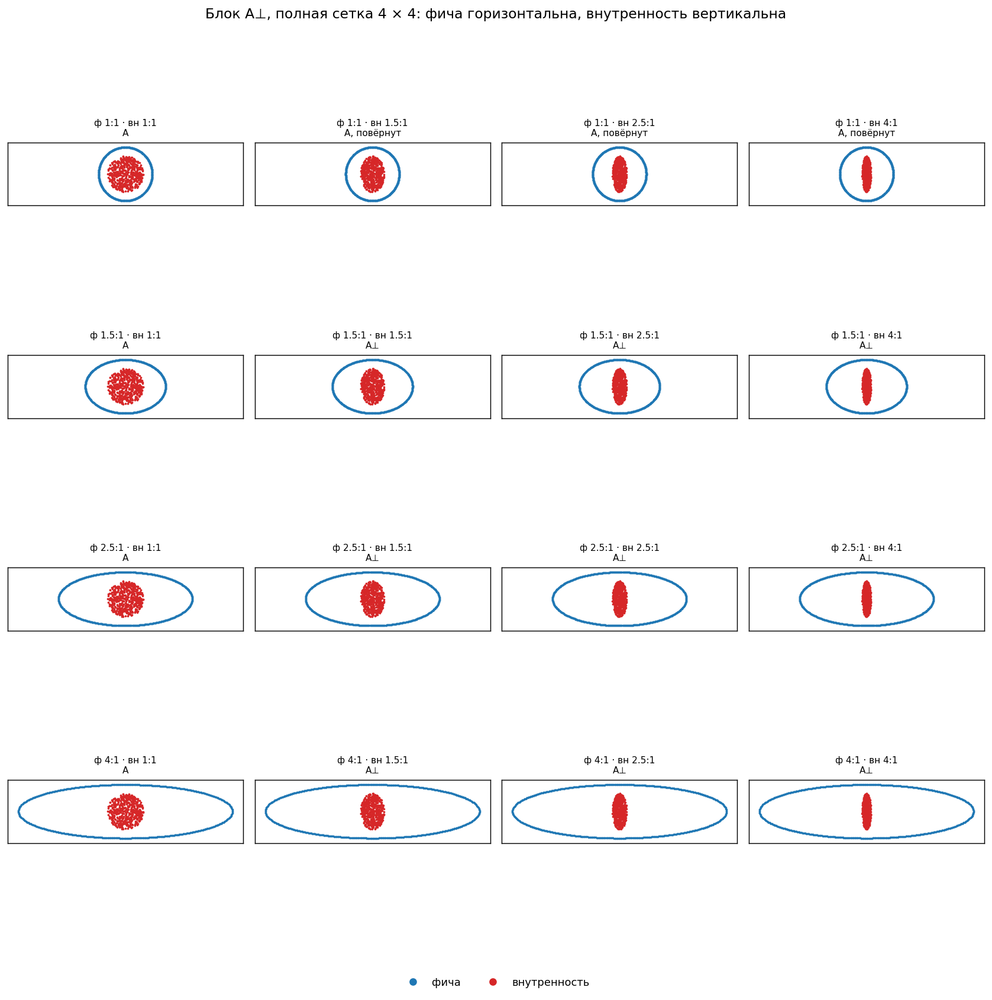

источники ячеек:
  фича 1:1  A             A, повёрнут   A, повёрнут   A, повёрнут 
  фича 1.5:1  A             A⊥            A⊥            A⊥          
  фича 2.5:1  A             A⊥            A⊥            A⊥          
  фича 4:1  A             A⊥            A⊥            A⊥          


In [32]:
ASP = [1.0, 1.5, 2.5, 4.0]

def perp_cell(fa, ia):
    # ячейка ⊥-сетки: (имя, поворот в градусах, откуда взята)
    if fa > 1.0 and ia > 1.0:
        q = cells_meta[(cells_meta.block == "A⊥") & (cells_meta.feature_aspect == fa)
                       & (cells_meta.interior_aspect == ia)]
        return q.index[0], 0, "A⊥"
    q = cells_meta[(cells_meta.block == "A") & (cells_meta.feature_aspect == fa)
                   & (cells_meta.interior_aspect == ia)]
    return q.index[0], (90 if ia > 1.0 else 0), ("A, повёрнут" if ia > 1.0 else "A")

GRID = [[perp_cell(fa, ia) for ia in ASP] for fa in ASP]

def rot(P, deg):
    if not deg:
        return P
    t = np.radians(deg); c_, s_ = np.cos(t), np.sin(t)
    return np.asarray(P) @ np.array([[c_, -s_], [s_, c_]]).T

hx_all = hy_all = 0.0
for row in GRID:
    for name, deg, _ in row:
        h1, h2 = gp.cells_extent([name])
        if deg:
            h1, h2 = h2, h1
        hx_all, hy_all = max(hx_all, h1), max(hy_all, h2)

fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for r, fa in enumerate(ASP):
    for c, ia in enumerate(ASP):
        ax = axes[r, c]; name, deg, src = GRID[r][c]
        Xc, yc, Ac = gs.dataset_points(name)[:3]
        Xi = rot(np.asarray(Xc[yc == 1]), deg); Af = rot(np.asarray(Ac), deg)
        ax.scatter(Xi[:, 0], Xi[:, 1], s=1.1, c=gp.C_INTERIOR, zorder=1)
        ax.scatter(Af[:, 0], Af[:, 1], s=1.1, c=gp.C_FEATURE, zorder=2)
        ax.set_xlim(-hx_all, hx_all); ax.set_ylim(-hy_all, hy_all)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"ф {fa:g}:1 · вн {ia:g}:1\n{src}", fontsize=8.5)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=gp.C_FEATURE, label="фича"),
                    plt.Line2D([], [], marker="o", ls="", color=gp.C_INTERIOR,
                               label="внутренность")],
           loc="lower center", ncol=2, fontsize=10, frameon=False, bbox_to_anchor=(.5, -.01))
fig.suptitle("Блок A⊥, полная сетка 4 × 4: фича горизонтальна, внутренность вертикальна",
             fontsize=13)
plt.tight_layout(rect=[0, .015, 1, 1]); plt.show()
print("источники ячеек:")
for r, fa in enumerate(ASP):
    print(f"  фича {fa:g}:1  " + "  ".join(f"{GRID[r][c][2]:12s}" for c in range(4)))


## 3.2 Куда направлена кривая — решающее измерение

Розы читаются как в 2.5: круговая гистограмма направления большой оси по всем кривым ячейки,
каждое измерение отложено дважды (угол — ось, а не стрелка), каждая панель нормирована на свой
максимум. Горизонтальный лепесток означает «вдоль **фичи**», вертикальный — «вдоль
**внутренности**».


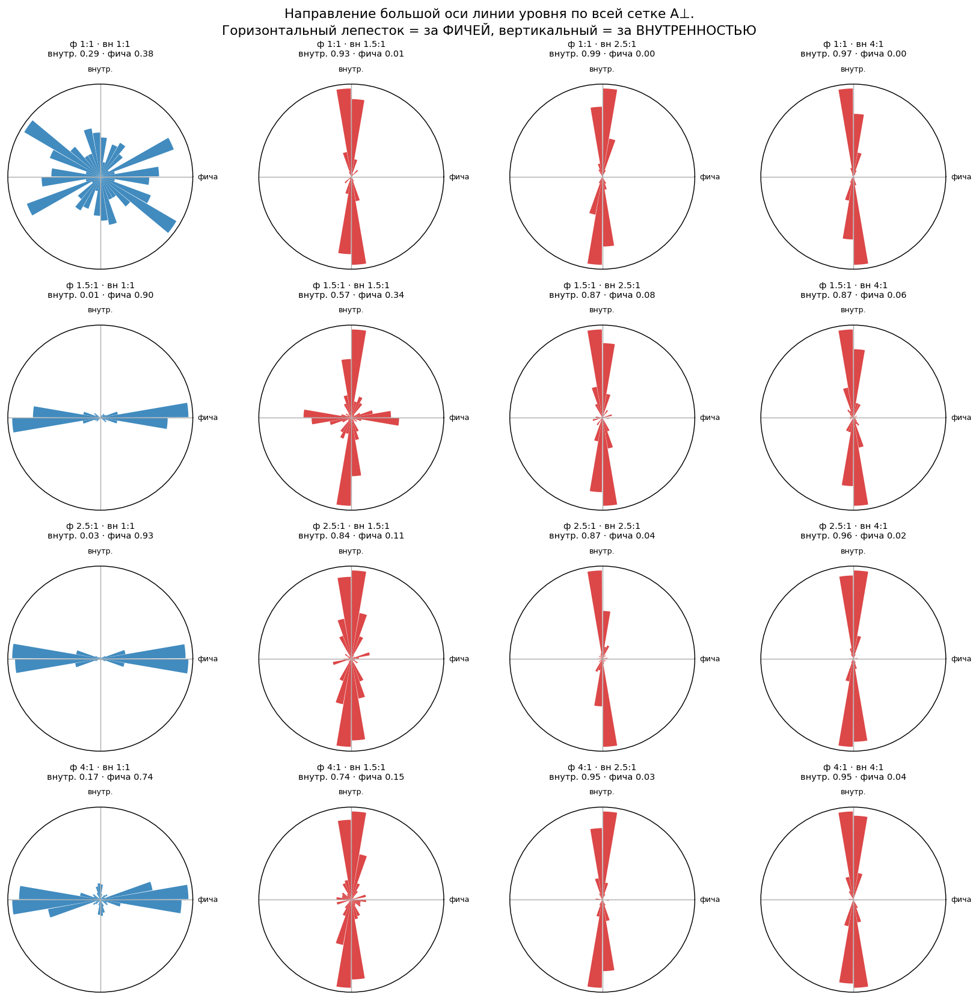

 фича  внутр    источник  прошло  вдоль_фичи  вдоль_внутр  аспект  свид  скор
  1.0    1.0           A   0.052       0.382        0.292   1.054  1.00 0.030
  1.0    1.5 A, повёрнут   0.728       0.008        0.929   1.303  1.00 0.045
  1.0    2.5 A, повёрнут   0.887       0.003        0.992   1.623  0.88 0.065
  1.0    4.0 A, повёрнут   0.973       0.000        0.971   1.824  0.68 0.079
  1.5    1.0           A   0.418       0.896        0.008   1.202  1.00 0.043
  1.5    1.5          A⊥   0.502       0.338        0.567   1.225  0.88 0.068
  1.5    2.5          A⊥   0.738       0.081        0.871   1.481  0.58 0.089
  1.5    4.0          A⊥   0.848       0.058        0.870   1.731  0.46 0.115
  2.5    1.0           A   0.504       0.931        0.034   1.225  0.40 0.081
  2.5    1.5          A⊥   0.576       0.108        0.838   1.265  0.10 0.110
  2.5    2.5          A⊥   0.843       0.045        0.869   1.569  0.08 0.130
  2.5    4.0          A⊥   0.873       0.020        0.962   1.72

In [33]:
GATE = .10
fig, axes = plt.subplots(4, 4, figsize=(13, 13), subplot_kw={"projection": "polar"})
edges = np.radians(np.arange(0, 361, 10))
rows = []
for r, fa in enumerate(ASP):
    for c, ia in enumerate(ASP):
        ax = axes[r, c]; name, deg, src = GRID[r][c]
        g_all = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        g = g_all[g_all.a2 >= GATE]
        a = (g.angle2.values + deg) % 180                 # поворот вместе с датасетом
        both = np.concatenate([np.radians(a), np.radians(a) + np.pi]) % (2*np.pi)
        h, _ = np.histogram(both, bins=edges); h = h / max(h.max(), 1)
        colr = gp.C_INTERIOR if ia > 1.0 else gp.C_FEATURE
        ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4), color=colr,
               alpha=.85, edgecolor="none")
        along = float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan
        across = float(((a > 60) & (a < 120)).mean()) if len(a) else np.nan
        rows.append(dict(фича=fa, внутр=ia, источник=src, прошло=len(g)/max(len(g_all), 1),
                         вдоль_фичи=along, вдоль_внутр=across,
                         аспект=float(g_all.aspect.median()),
                         свид=float(cells_meta.loc[name, "rate_floor"]),
                         скор=float(cells_meta.loc[name, "target_median"])))
        ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
        ax.set_xticklabels(["фича", "внутр.", "", ""], fontsize=7)
        ax.set_title(f"ф {fa:g}:1 · вн {ia:g}:1\nвнутр. {across:.2f} · фича {along:.2f}",
                     fontsize=8, pad=8)
fig.suptitle("Направление большой оси линии уровня по всей сетке A⊥.\n"
             "Горизонтальный лепесток = за ФИЧЕЙ, вертикальный = за ВНУТРЕННОСТЬЮ", fontsize=12)
plt.tight_layout(); plt.show()

RP = pd.DataFrame(rows)
print(RP.round(3).to_string(index=False))
core = RP[(RP.фича > 1) & (RP.внутр > 1)]
# из края с круглой внутренностью исключаем ячейку «круг в круге»: там оси нет
# ни у одного объекта, и фильтр по a2 проходит 5 % кривых
edge_f = RP[(RP.внутр == 1.0) & (RP.фича > 1.0)]
edge_i = RP[(RP.фича == 1.0) & (RP.внутр > 1.0)]
deg = RP[(RP.фича == 1.0) & (RP.внутр == 1.0)].iloc[0]
print(f"\nвырожденная ячейка «круг в круге»: фильтр проходит {deg.прошло:.0%} кривых, "
      f"роза изотропна ({deg.вдоль_фичи:.2f} против {deg.вдоль_внутр:.2f})")
print(f"первый столбец без неё, внутренность кругла (контроль фичи): вдоль фичи "
      f"{edge_f.вдоль_фичи.min():.2f}–{edge_f.вдоль_фичи.max():.2f}")
print(f"первая строка, фича кругла (контроль внутренности): вдоль внутренности "
      f"{edge_i.вдоль_внутр.min():.2f}–{edge_i.вдоль_внутр.max():.2f}")
print(f"ядро 3 × 3, объекты спорят: вдоль внутренности "
      f"{core.вдоль_внутр.min():.2f}–{core.вдоль_внутр.max():.2f}, вдоль фичи "
      f"{core.вдоль_фичи.min():.2f}–{core.вдоль_фичи.max():.2f}; "
      f"внутренность выигрывает в {int((core.вдоль_внутр > core.вдоль_фичи).sum())} из {len(core)}")


**Наблюдения.**

- **Каждый объект по отдельности направление задаёт.** В первом столбце, где внутренность
  круглая, кривая идёт **вдоль фичи** в 0.74–0.93 случаев. В первой строке, где круглая фича,
  она идёт **вдоль внутренности** в 0.93–0.99. То есть ни один из объектов не «нейтрален»: при
  отсутствии конкурента каждый разворачивает кривую к себе.
- **Когда они спорят, выигрывает внутренность, и с большим отрывом.** В ядре 3 × 3 доля вдоль
  внутренности **0.57–0.96** против **0.02–0.34** вдоль фичи; внутренность выигрывает во всех
  девяти ячейках.
- **Самый близкий счёт — там, где внутренность наименее вытянута** (1.5:1 при фиче 1.5:1):
  0.57 против 0.34. Чем вытянутее внутренность, тем однозначнее ответ: при 4:1 доля 0.87–0.96.
- **Угловой контроль.** В ячейке «круг в круге» фильтр по `a₂` проходит лишь 5 % кривых, и роза
  изотропна: там, где направления нет, прибор его не выдумывает.
- **Доля прошедших фильтр сама по себе информативна**: 0.41–0.50 в столбце с круглой
  внутренностью и 0.73–0.97 в остальных. Вытянутость кривой в основном приносит внутренность,
  фича даёт слабую.

**Вывод.** Сетка отвечает на вопрос, который блок A поставить не мог, и отвечает в трёх режимах
сразу: фича направление задаёт, но только когда конкурента нет; внутренность задаёт всегда;
при конкуренции побеждает внутренность.


## 3.3 Что предсказывали модели

Проверка идёт на **девяти ядровых ячейках** — только там объекты конкурируют, и только там
предсказания конструкций расходятся. Три конструкции из 2.2.3 давали в блоке A близкие
предсказания и **расходятся здесь**, потому что
теперь у объектов разные оси. Это самая жёсткая их проверка во всём эксперименте: промах на
прямой угол ни списать, ни подогнать нельзя.


In [ ]:
def _angle_aspect(pts):
    desc = fourier_descriptor(torch.tensor(np.asarray(pts), dtype=torch.float32))
    return (float(np.degrees(desc["phase"][2] % np.pi)),
            float(gs.a2_to_aspect(np.array([desc["amplitude"][2]]))[0]))

rows = []
for name in sorted(cells_meta[cells_meta.block == "A⊥"].index):
    meta = cells_meta.loc[name]
    obs = RP[(RP.фича == meta.feature_aspect) & (RP.внутр == meta.interior_aspect)].iloc[0]  # ядро
    ang_d, asp_d = _angle_aspect(sm.dilation_from_gap(name, 0.45)["curve"])
    xs, ys, F, c0 = sm.harmonic_potential(name)
    cu = sm.enclosing_level_curve(xs, ys, F, 0.40, c0)
    ang_h, asp_h = _angle_aspect(cu) if cu is not None else (np.nan, np.nan)
    ang_, r_in, r_out, centre = sm.annulus_radial(name)
    mid_line = centre + np.stack([(.5*(r_in+r_out))*np.cos(ang_),
                                  (.5*(r_in+r_out))*np.sin(ang_)], 1)
    ang_m, asp_m = _angle_aspect(mid_line)      # не 'mid': глобальная таблица форм
    rows.append(dict(фича=meta.feature_aspect, внутр=meta.interior_aspect,
                     срединная=ang_m, раздутие=ang_d, потенциал=ang_h,
                     за_внутр_набл=float(obs.вдоль_внутр),
                     асп_раздутие=asp_d, асп_потенциал=asp_h, асп_набл=float(obs.аспект)))
PM = pd.DataFrame(rows).sort_values(["фича", "внутр"]).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(len(PM))
for col, c_, mk in (("срединная", "#111", "s"), ("раздутие", "#e08214", "o"),
                    ("потенциал", "#2c7a4b", "D")):
    axes[0].plot(x, PM[col], mk, color=c_, ms=9, label=col)
axes[0].axhline(0, color=gp.C_FEATURE, lw=1.6, ls="--")
axes[0].axhline(90, color=gp.C_INTERIOR, lw=1.6, ls=":")
axes[0].text(.05, 4, "ось фичи", fontsize=8, color=gp.C_FEATURE)
axes[0].text(.05, 83, "ось внутренности", fontsize=8, color=gp.C_INTERIOR)
axes[0].set_xticks(x, [f"{a:g}:{b:g}" for a, b in zip(PM.фича, PM.внутр)], fontsize=7, rotation=90)
axes[0].set_ylabel("предсказанное направление, град"); axes[0].legend(fontsize=8)
axes[0].set_title("ориентация: срединная линия ошибается на 90°", fontsize=10)

axes[1].plot(x, PM.асп_набл, "o-", color="#111", lw=2.2, ms=8, label="наблюдается")
axes[1].plot(x, PM.асп_раздутие, "s--", color="#e08214", lw=1.6, ms=6, label="раздутие")
axes[1].plot(x, PM.асп_потенциал, "D--", color="#2c7a4b", lw=1.6, ms=6, label="потенциал")
axes[1].set_xticks(x, [f"{a:g}:{b:g}" for a, b in zip(PM.фича, PM.внутр)], fontsize=7, rotation=90)
axes[1].set_ylabel("вытянутость"); axes[1].legend(fontsize=8)
axes[1].set_title("величина: раздутие завышает, потенциал занижает", fontsize=10)
fig.suptitle("Блок A⊥: проверка трёх конструкций там, где они расходятся", fontsize=12)
plt.tight_layout(); plt.show()

print(PM.round(2).to_string(index=False))
for col in ("раздутие", "потенциал"):
    print(f"{col}: |ошибка| по вытянутости {np.abs(PM['асп_'+col] - PM.асп_набл).mean():.3f}")
U_perp = cell_uncertainty(sorted(cells_meta[cells_meta.block == "A⊥"].index))
print(f"против неопределённости самих чисел: ±{np.median(U_perp):.2f} "
      f"(бутстрап по 50 сетям), размах по этим 9 ячейкам "
      f"{PM.асп_набл.max() - PM.асп_набл.min():.2f}")


**Наблюдения.**

- **Срединная линия зазора ошибается на 90°** во всех девяти ячейках: она предсказывает 0.1–0.2°,
  то есть «вдоль фичи», а наблюдается «вдоль внутренности». Это независимое от блока A
  опровержение всего класса «компромисс между формами двух границ», и самое жёсткое из возможных.
- **Раздутие и потенциал ориентацию угадывают точно**: 90.0° и 89.8–92.3°. Обе конструкции
  локальны по внутренности, и здесь это видно прямо.
- **По величине сохраняется та же систематика, что в блоке A**: раздутие завышает (1.38–2.67
  против наблюдаемых 1.23–2.20), потенциал занижает (1.01–1.52).
- **А по величине обе здесь промахиваются**: средняя ошибка 0.43 у раздутия и 0.33 у потенциала
  при неопределённости самих чисел ±0.17 и размахе по этим девяти ячейкам 0.98 — вдвое-втрое
  больше того, что можно списать на шум. То есть ориентацию обе конструкции дают верно, а величину
  в повёрнутой конфигурации — нет, и это надо сказать прямо. Блок B для них тяжелее блока A.

**Вывод.** Блок B подтверждает разделение из 2.2.3 и добавляет к нему прямое доказательство: те
конструкции, что описывают наблюдаемое, локальны по внутренности; те, что усредняют по зазору,
дают неверный ответ уже на уровне направления.


## 3.4 Что стало со свидетельством

Ориентация — это про форму кривой. Отдельный вопрос: что поворот внутренности делает с самим
**свидетельством**, то есть со структурным критерием. Сравнение парное: та же фича, та же
внутренность, отличается только её поворот.


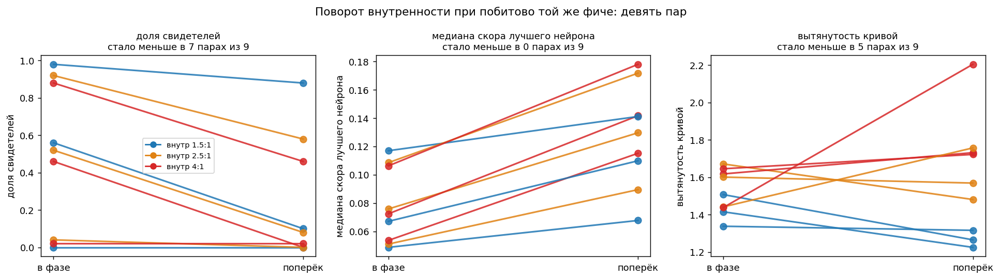

 фича  внутр  свид_фаза  свид_поперёк  скор_фаза  скор_поперёк  асп_фаза  асп_поперёк
  1.5    1.5       0.98          0.88      0.049         0.068     1.415        1.225
  1.5    2.5       0.92          0.58      0.051         0.089     1.671        1.481
  1.5    4.0       0.88          0.46      0.054         0.115     1.617        1.731
  2.5    1.5       0.56          0.10      0.067         0.110     1.507        1.265
  2.5    2.5       0.52          0.08      0.076         0.130     1.601        1.569
  2.5    4.0       0.46          0.00      0.072         0.142     1.645        1.722
  4.0    1.5       0.00          0.00      0.117         0.141     1.338        1.316
  4.0    2.5       0.04          0.00      0.109         0.172     1.441        1.757
  4.0    4.0       0.02          0.02      0.106         0.178     1.438        2.204

скор ухудшился в 9 парах из 9
доля свидетелей упала в 7 парах из 9
вытянутость кривой изменилась разнонаправленно: упала в 5, выросла в 4


In [35]:
turn_pairs = []
for fa in (1.5, 2.5, 4.0):
    for ia in (1.5, 2.5, 4.0):
        a = cells_meta[(cells_meta.block == "A") & (cells_meta.feature_aspect == fa)
                       & (cells_meta.interior_aspect == ia)].index[0]
        p = cells_meta[(cells_meta.block == "A⊥") & (cells_meta.feature_aspect == fa)
                       & (cells_meta.interior_aspect == ia)].index[0]
        ca, cp = cells_meta.loc[a], cells_meta.loc[p]
        turn_pairs.append(dict(фича=fa, внутр=ia,
                          свид_фаза=ca.rate_floor, свид_поперёк=cp.rate_floor,
                          скор_фаза=ca.target_median, скор_поперёк=cp.target_median,
                          асп_фаза=float(hl[hl.dataset_type == a].aspect.median()),
                          асп_поперёк=float(hl[hl.dataset_type == p].aspect.median())))
PR = pd.DataFrame(turn_pairs)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (c1, c2, lab) in zip(axes, [
        ("свид_фаза", "свид_поперёк", "доля свидетелей"),
        ("скор_фаза", "скор_поперёк", "медиана скора лучшего нейрона"),
        ("асп_фаза", "асп_поперёк", "вытянутость кривой")]):
    for _, r in PR.iterrows():
        ax.plot([0, 1], [r[c1], r[c2]], "o-", color=COL[r.внутр], lw=1.8, ms=7, alpha=.85)
    ax.set_xticks([0, 1], ["в фазе", "поперёк"]); ax.set_ylabel(lab)
    ax.set_title(f"{lab}\nстало меньше в {int((PR[c2] < PR[c1]).sum())} парах из 9", fontsize=10)
axes[0].legend(handles=[plt.Line2D([], [], color=c, marker="o", label=f"внутр {k:g}:1")
                        for k, c in COL.items() if k != 1.0], fontsize=8)
fig.suptitle("Поворот внутренности при побитово той же фиче: девять пар", fontsize=12)
plt.tight_layout(); plt.show()

print(PR.round(3).to_string(index=False))
print(f"\nскор ухудшился в {int((PR.скор_поперёк > PR.скор_фаза).sum())} парах из 9")
print(f"доля свидетелей упала в {int((PR.свид_поперёк < PR.свид_фаза).sum())} парах из 9")
print(f"вытянутость кривой изменилась разнонаправленно: упала в "
      f"{int((PR.асп_поперёк < PR.асп_фаза).sum())}, выросла в "
      f"{int((PR.асп_поперёк > PR.асп_фаза).sum())}")


**Наблюдения.**

- **Скор ухудшается во всех девяти парах**, часто вдвое: 0.049 → 0.068, 0.051 → 0.089,
  0.054 → 0.115, 0.067 → 0.110, 0.076 → 0.130, 0.072 → 0.142, 0.117 → 0.141, 0.109 → 0.172,
  0.106 → 0.178. Фича при этом побитово та же самая.
- **Доля свидетелей падает в 7 парах из 9**, в оставшихся двух она была нулевой уже в фазе.
  Самые заметные падения: 0.92 → 0.58, 0.88 → 0.46, 0.56 → 0.10, 0.52 → 0.08, 0.46 → 0.00.
- **А вытянутость кривой почти не меняется** — падает в 5 парах, растёт в 4. Поворот внутренности
  не делает кривую другой по величине, он её **разворачивает**.

**Вывод, и он центральный для всего эксперимента.** Одну и ту же окружность-фичу можно сделать
засвидетельствованной или нет, **ничего с ней не делая**: достаточно повернуть множество
противоположного класса внутри неё. Свидетельство есть свойство **пары**, а не фичи. Механизм
виден в одной величине: кривая разворачивается вслед за внутренностью и перестаёт совпадать с
фичей — при том, что сама фича не изменилась.


## 3.5 Итог блока B

1. **Полная сетка 4 × 4 разделяет вклады объектов.** Край с круглой внутренностью показывает, что
   фича направление задаёт (вдоль неё 0.74–0.93); край с круглой фичей — что внутренность задаёт
   тоже (0.93–0.99). Оба объекта «умеют» разворачивать кривую (3.2).
2. **При конкуренции выигрывает внутренность**: в ядре 3 × 3 доля вдоль внутренности 0.57–0.96
   против 0.02–0.34 вдоль фичи, во всех девяти ячейках.
3. **Это опровергает целый класс моделей независимо от блока A**: срединная линия зазора
   предсказывает направление вдоль фичи и ошибается на 90° девять раз из девяти; раздутие и
   гармонический потенциал дают 90.0° и 89.8–92.3° (3.3).
4. **Систематика величины та же, что в блоке A** (раздутие завышает, потенциал занижает), и обе
   конструкции здесь промахиваются вдвое-втрое дальше, чем позволяет шум: 0.43 и 0.33 при
   неопределённости самих чисел ±0.17.
5. **Поворот внутренности разрушает свидетельство при неизменной фиче**: скор хуже в 9 парах из
   9, доля свидетелей падает в 7 из 9, а вытянутость кривой при этом не меняется систематически
   (3.4). Одну и ту же окружность можно сделать засвидетельствованной или нет, ничего с ней не
   делая.
6. Как и везде, это утверждения о **согласии** величин, а не о причине: абляции нет.


# 4. Блок C. Плотность описания: проверка на то, что эффект геометрический

## Постановка

Блоки A и B показали, что форма линии уровня согласована с геометрией пары, и предложили три
конструкции, которые эту согласованность описывают. У всех трёх общее свойство: они считаются
**из геометрии и больше ни из чего**. Значит есть очевидная уязвимость — а вдруг форма кривой
зависит от того, чего геометрия не видит?

Блок C проверяет ровно это. Четыре геометрии берутся из блоков A и B, и в каждой варьируется
то, **сколькими точками описан каждый объект** при неизменной тысяче точек всего:

| точек **внутри** | точек **на фиче** | как читать |
|---|---|---|
| **200** | 800 | фича описана плотно, внутренность разрежена |
| **500** | 500 | поровну — это ячейка блока A или B |
| **800** | 200 | внутренность описана плотно, фича разрежена |

Дальше в тексте везде указывается **число точек внутри** — 200, 500 или 800, — а не доля, чтобы
не приходилось помнить, в чью сторону считается баланс.

| геометрия | зачем она здесь |
|---|---|
| фича 4:1, внутренность кругла | форму переносить нечего, работает только фича |
| фича кругла, внутренность 4:1 | наоборот, работает только внутренность |
| оба 4:1, в фазе | оба тянут в одну сторону |
| оба 4:1, поперёк | оба тянут в разные — самая напряжённая конфигурация |

**Ключевое свойство дизайна.** Внутри строки **геометрия побитово одна и та же**: те же эллипсы,
те же полуоси, тот же зазор. Меняется только плотность точек. Поэтому любая чисто геометрическая
модель обязана предсказывать в строке **одно и то же число**. Если наблюдаемое в строке меняется,
геометрии недостаточно — и вопрос в том, через что действует плотность.


## 4.1 Датасеты

Двенадцать конфигураций: четыре геометрии (строки) × три плотности (столбцы). Внутри строки формы совпадают точно, различается только число точек на каждом объекте — это видно по тому, насколько густо нарисован каждый цвет.


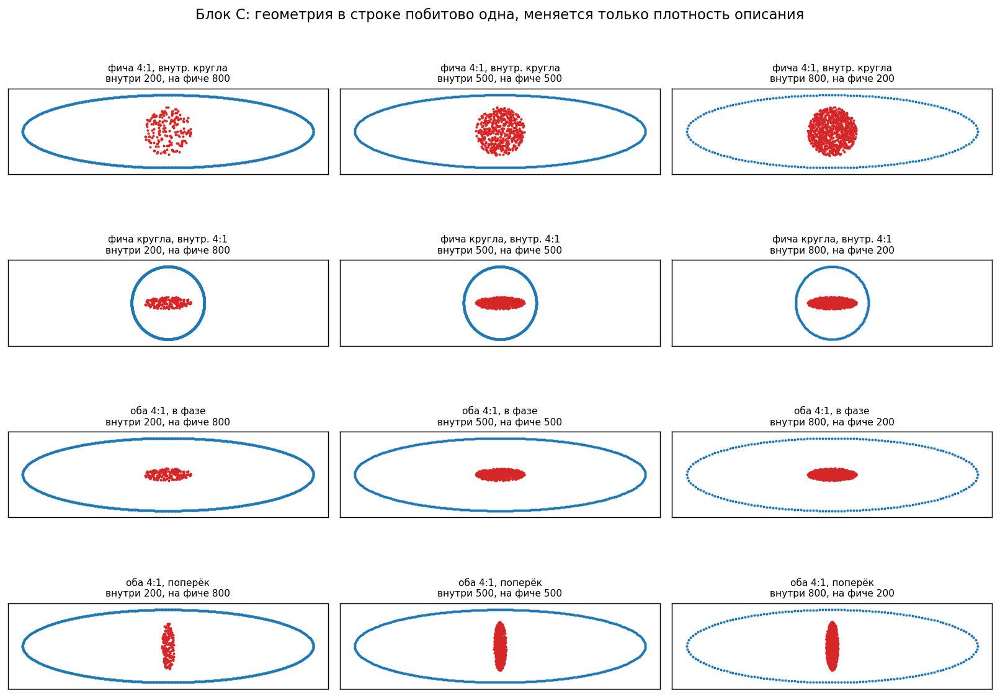

In [36]:
C_GEO = [("g5_f040_i010_s100", "фича 4:1, внутр. кругла"),
         ("g5_f010_i040_s100", "фича кругла, внутр. 4:1"),
         ("g5_f040_i040_s100", "оба 4:1, в фазе"),
         ("g5_f040_i040T_s100", "оба 4:1, поперёк")]
N_IN = [200, 500, 800]                      # точек внутри; на фиче — остальные до 1000

def c_cell(pref, n_in):
    q = cells_meta[[n.startswith(pref) for n in cells_meta.index]]
    return q[np.isclose(q.balance, n_in/1000)].index[0]

hxC = hyC = 0.0
for pref, _ in C_GEO:
    for n_in in N_IN:
        h1, h2 = gp.cells_extent([c_cell(pref, n_in)])
        hxC, hyC = max(hxC, h1), max(hyC, h2)

fig, axes = plt.subplots(4, 3, figsize=(12.5, 9.5))
for r, (pref, lab) in enumerate(C_GEO):
    for c, n_in in enumerate(N_IN):
        ax = axes[r, c]; name = c_cell(pref, n_in)
        Xc, yc, Ac = gs.dataset_points(name)[:3]
        ax.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=1.6, c=gp.C_INTERIOR, zorder=1)
        ax.scatter(Ac[:, 0], Ac[:, 1], s=1.6, c=gp.C_FEATURE, zorder=2)
        ax.set_xlim(-hxC, hxC); ax.set_ylim(-hyC, hyC)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{lab}\nвнутри {n_in}, на фиче {1000-n_in}", fontsize=8.5)
fig.suptitle("Блок C: геометрия в строке побитово одна, меняется только плотность описания",
             fontsize=12.5)
plt.tight_layout(); plt.show()


## 4.2 Что плотность делает с формой кривой

Величина та же, что в блоке A. Здесь она смотрится тремя способами, потому что «медиана
сдвинулась» — слишком слабое утверждение: сдвиг может идти от нескольких моделей, от одной
ступени лестницы или от хвоста распределения.

* **по моделям** — медиана вытянутости внутри каждой из 50 моделей, по одной точке на сеть.
  Если сдвиг популяционный, сдвинется всё облако; если его дают несколько сетей — увидим это;
* **по ступеням лестницы** — двигается ли всё семейство линий уровня или только его край;
* **по распределению целиком** — что происходит с правой группой (вытянутость выше 2).


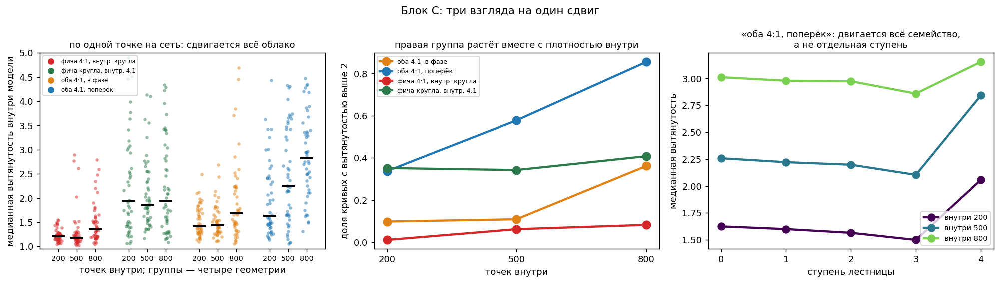

медиана по моделям [10-й – 90-й перцентиль] и проверка сдвига 200 против 800:
  фича 4:1, внутр. кругла  1.21 [1.09–1.45] | 1.18 [1.08–1.52] | 1.35 [1.16–2.13]   p = 1.8e-04, моделей при 800 выше медианы при 200: 0.74
  фича кругла, внутр. 4:1  1.94 [1.23–4.47] | 1.86 [1.37–2.92] | 1.94 [1.26–3.48]   p = 7.1e-01, моделей при 800 выше медианы при 200: 0.50
  оба 4:1, в фазе          1.42 [1.18–1.92] | 1.44 [1.23–1.95] | 1.68 [1.18–3.18]   p = 8.9e-03, моделей при 800 выше медианы при 200: 0.74
  оба 4:1, поперёк         1.63 [1.26–3.27] | 2.25 [1.25–3.73] | 2.82 [1.65–4.19]   p = 1.7e-06, моделей при 800 выше медианы при 200: 0.92

доля кривых выше аспекта 2:
внутри                    200   500   800
геометрия                                
оба 4:1, в фазе          0.10  0.11  0.36
оба 4:1, поперёк         0.34  0.58  0.86
фича 4:1, внутр. кругла  0.01  0.06  0.08
фича кругла, внутр. 4:1  0.35  0.34  0.41


In [37]:
from scipy.stats import mannwhitneyu
GC = {lab: c for (_, lab), c in zip(C_GEO, ["#d62728", "#2c7a4b", "#e08214", "#1f77b4"])}
rowsC = []
for pref, lab in C_GEO:
    for n_in in N_IN:
        name = c_cell(pref, n_in)
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        gg = g[g.a2 >= .10]; a = gg.angle2.values
        per = g.groupby("model_index").aspect.median()
        rowsC.append(dict(геометрия=lab, внутри=n_in, ячейка=name, кривых=len(g),
                          аспект=float(g.aspect.median()), r0=float(g.r0.median()),
                          по_моделям=per, выше2=float((g.aspect > 2).mean()),
                          вдоль=float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan,
                          поперёк=float(((a > 60) & (a < 120)).mean()) if len(a) else np.nan,
                          прошло=len(gg)/max(len(g), 1),
                          свид=float(cells_meta.loc[name, "rate_floor"]),
                          скор=float(cells_meta.loc[name, "target_median"]),
                          пол=float(cells_meta.loc[name, "floor"])))
CC = pd.DataFrame(rowsC)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
rng = np.random.default_rng(4)
xpos = 0; ticks, labels = [], []  # не 'pos': так зовут глобальную таблицу
for pref, lab in C_GEO:
    for k, n_in in enumerate(N_IN):
        v = CC[(CC.геометрия == lab) & (CC.внутри == n_in)].по_моделям.iloc[0]
        axes[0].scatter(rng.normal(xpos, .09, len(v)), v, s=13, alpha=.5, color=GC[lab],
                        linewidths=0)
        axes[0].plot([xpos-.3, xpos+.3], [v.median()]*2, color="k", lw=2.2, zorder=5)
        ticks.append(xpos); labels.append(str(n_in)); xpos += 1
    xpos += .8
axes[0].set_xticks(ticks, labels, fontsize=8)
axes[0].set_ylabel("медианная вытянутость внутри модели"); axes[0].set_ylim(.95, 5)
axes[0].set_xlabel("точек внутри; группы — четыре геометрии")
axes[0].set_title("по одной точке на сеть: сдвигается всё облако", fontsize=10)
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=l)
                        for l, c in GC.items()], fontsize=6.5)

hot = "оба 4:1, поперёк"
for lab, g in CC.groupby("геометрия"):
    g = g.sort_values("внутри")
    axes[1].plot(g.внутри, g.выше2, "o-", color=GC[lab], lw=2.4, ms=9, label=lab)
axes[1].set_xticks(N_IN); axes[1].set_xlabel("точек внутри")
axes[1].set_ylabel("доля кривых с вытянутостью выше 2"); axes[1].legend(fontsize=7)
axes[1].set_title("правая группа растёт вместе с плотностью внутри", fontsize=10)

for n_in in N_IN:
    name = c_cell(dict((l, p) for p, l in C_GEO)[hot], n_in)
    g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
    v = g.groupby("rung").aspect.median()
    axes[2].plot(v.index, v.values, "o-", lw=2.4, ms=8,
                 color=plt.cm.viridis((n_in-200)/600*.8), label=f"внутри {n_in}")
axes[2].set_xticks(range(5)); axes[2].set_xlabel("ступень лестницы")
axes[2].set_ylabel("медианная вытянутость"); axes[2].legend(fontsize=8)
axes[2].set_title(f"«{hot}»: двигается всё семейство,\nа не отдельная ступень", fontsize=10)
fig.suptitle("Блок C: три взгляда на один сдвиг", fontsize=12)
plt.tight_layout(); plt.show()

print("медиана по моделям [10-й – 90-й перцентиль] и проверка сдвига 200 против 800:")
for pref, lab in C_GEO:
    line = []
    for n_in in N_IN:
        v = CC[(CC.геометрия == lab) & (CC.внутри == n_in)].по_моделям.iloc[0]
        line.append(f"{v.median():.2f} [{v.quantile(.1):.2f}–{v.quantile(.9):.2f}]")
    v2 = CC[(CC.геометрия == lab) & (CC.внутри == 200)].по_моделям.iloc[0]
    v8 = CC[(CC.геометрия == lab) & (CC.внутри == 800)].по_моделям.iloc[0]
    pv = mannwhitneyu(v2, v8)[1]
    print(f"  {lab:24s} " + " | ".join(line) +
          f"   p = {pv:.1e}, моделей при 800 выше медианы при 200: {(v8 > v2.median()).mean():.2f}")
print("\nдоля кривых выше аспекта 2:")
print(CC.pivot(index="геометрия", columns="внутри", values="выше2").round(2).to_string())


**Наблюдения.**

- **Сдвиг популяционный, а не от нескольких сетей.** В «оба 4:1, поперёк» медиана по моделям идёт
  **1.63 → 2.25 → 2.82**, и при 800 точках внутри **92 % моделей** лежат выше медианы при 200
  (p = 2·10⁻⁶). В «оба 4:1, в фазе» и в «фича 4:1, внутренность кругла» — 74 % моделей и
  p = 9·10⁻³ и 2·10⁻⁴.
- **Ровно одна геометрия не реагирует** — «фича кругла, внутренность 4:1»: 1.94 → 1.86 → 1.94,
  p = 0.71, ровно половина моделей выше. Это не шум в данных, а осмысленное исключение, и в C.4
  видно, чем оно отличается от остальных.
- **Двигается всё семейство линий уровня**, а не край: в «поперёк» медиана по ступеням идёт
  1.63/1.60/1.57/1.50/2.06 при 200 точках внутри и 3.01/2.98/2.97/2.86/3.15 при 800. Разница
  примерно постоянна вдоль лестницы.
- **Правая группа растёт сильнее всего.** Доля кривых с вытянутостью выше 2 в «поперёк» идёт
  **0.34 → 0.58 → 0.86**: при 800 точках внутри почти все кривые вытянуты вдвое и больше. В
  «в фазе» — 0.10 → 0.11 → 0.36.

**Вывод.** Плотность описания — величина, которой в геометрии нет вовсе, — двигает форму линии
уровня, и двигает сильно: в самой напряжённой геометрии медиана растёт почти вдвое, а доля
сильно вытянутых кривых — в два с половиной раза. Это прямое ограничение на все три конструкции
из 2.2.3: **из одной геометрии форма не выводится**.


## 4.3 Направление

Форма — не только величина, но и направление. Розы читаются как в 2.5 и 3.2: круговая
гистограмма направления большой оси по всем кривым ячейки, каждое измерение отложено дважды,
каждая панель нормирована на свой максимум.


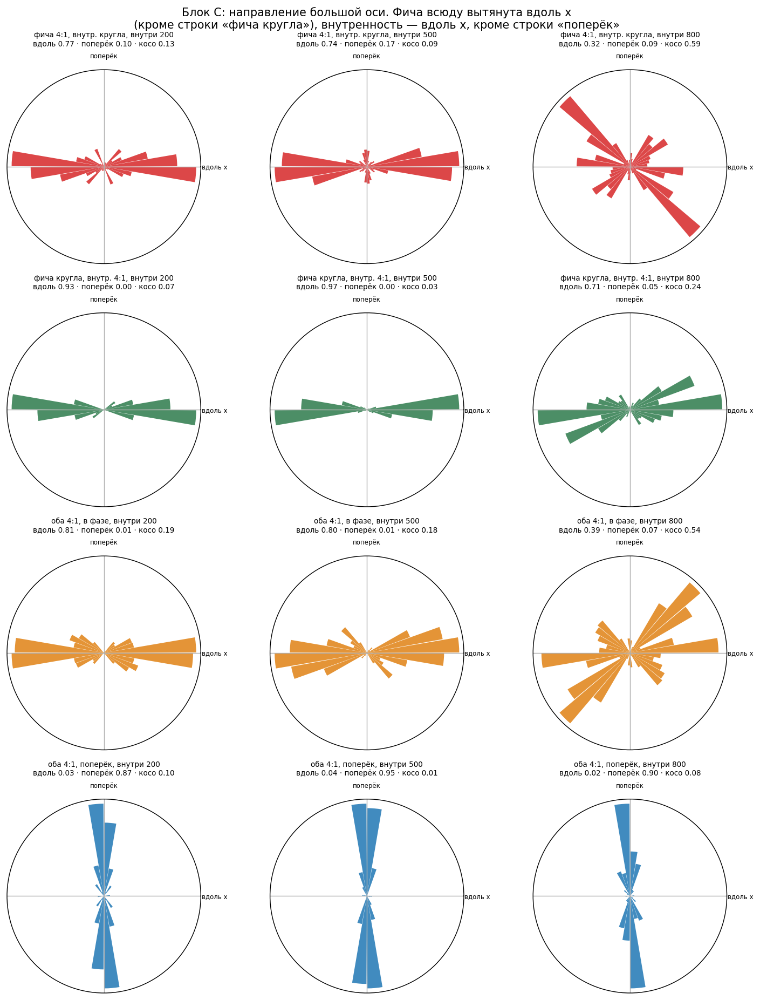

              геометрия  внутри  вдоль  поперёк  прошло
фича 4:1, внутр. кругла     200  0.773    0.096   0.504
фича 4:1, внутр. кругла     500  0.740    0.170   0.412
фича 4:1, внутр. кругла     800  0.324    0.091   0.659
фича кругла, внутр. 4:1     200  0.930    0.002   0.866
фича кругла, внутр. 4:1     500  0.971    0.000   0.973
фича кругла, внутр. 4:1     800  0.712    0.046   0.900
        оба 4:1, в фазе     200  0.806    0.006   0.863
        оба 4:1, в фазе     500  0.805    0.011   0.887
        оба 4:1, в фазе     800  0.393    0.067   0.878
       оба 4:1, поперёк     200  0.030    0.867   0.922
       оба 4:1, поперёк     500  0.037    0.949   0.886
       оба 4:1, поперёк     800  0.022    0.899   0.997

косо (ни вдоль, ни поперёк):
внутри                    200   500   800
геометрия                                
оба 4:1, в фазе          0.19  0.18  0.54
оба 4:1, поперёк         0.10  0.01  0.08
фича 4:1, внутр. кругла  0.13  0.09  0.59
фича кругла, внутр. 4:1  0.07  0

In [38]:
fig, axes = plt.subplots(4, 3, figsize=(11.5, 14.5), subplot_kw={"projection": "polar"})
edges = np.radians(np.arange(0, 361, 10))
for r, (pref, lab) in enumerate(C_GEO):
    for c, n_in in enumerate(N_IN):
        ax = axes[r, c]; name = c_cell(pref, n_in)
        g_all = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        g = g_all[g_all.a2 >= .10]; a = g.angle2.values
        both = np.concatenate([np.radians(a), np.radians(a) + np.pi]) % (2*np.pi)
        h, _ = np.histogram(both, bins=edges); h = h / max(h.max(), 1)
        ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4), color=GC[lab],
               alpha=.85, edgecolor="none")
        along = float(((a < 30) | (a > 150)).mean()); across = float(((a > 60) & (a < 120)).mean())
        obl = 1 - along - across
        ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
        ax.set_xticklabels(["вдоль x", "поперёк", "", ""], fontsize=6.5)
        ax.set_title(f"{lab}, внутри {n_in}\nвдоль {along:.2f} · поперёк {across:.2f} · "
                     f"косо {obl:.2f}", fontsize=7.5, pad=7)
fig.suptitle("Блок C: направление большой оси. Фича всюду вытянута вдоль x\n"
             "(кроме строки «фича кругла»), внутренность — вдоль x, кроме строки «поперёк»",
             fontsize=11.5)
plt.tight_layout(); plt.show()

print(CC[["геометрия", "внутри", "вдоль", "поперёк", "прошло"]].round(3).to_string(index=False))
print("\nкосо (ни вдоль, ни поперёк):")
CC2o = CC.assign(косо=lambda d: 1 - d.вдоль - d.поперёк)
print(CC2o.pivot(index="геометрия", columns="внутри", values="косо").round(2).to_string())


**Наблюдения.**

- **В «оба 4:1, поперёк» направление не меняется вовсе**: доля поперёк 0.87 → 0.95 → 0.90 при
  доле вдоль 0.03 → 0.04 → 0.02. То есть там, где плотность сильнее всего меняет **величину**
  вытянутости, она не трогает её **направление**. Две характеристики формы разъезжаются, и это
  важно: значит плотность действует не «поворотом» кривой.
- **В трёх геометриях, где обе оси горизонтальны, при 800 точках внутри порядок падает**:
  доля вдоль идёт 0.81 → 0.81 → 0.39, 0.77 → 0.74 → 0.32, 0.93 → 0.97 → 0.71. Пропавшие кривые
  уходят **не поперёк** (доля поперёк остаётся 0.02–0.09), а **в косые направления**, и это
  видно на розах как четыре наклонных лепестка.
- **Это не «размытие», а вполне определённое направление — около 45°.** Доля кривых в секторах
  30–60° и 120–150° идёт **0.13 → 0.09 → 0.59** (фича 4:1, внутренность кругла),
  **0.19 → 0.18 → 0.54** (оба 4:1, в фазе) и **0.07 → 0.03 → 0.24** (фича кругла, внутренность
  4:1). При 200 и 500 точках внутри косых почти нет, при 800 их становится в три-шесть раз
  больше. То есть направление не теряется, а **переключается** на диагональное.
- **И это верно даже там, где оба объекта вытянуты вдоль одной оси** («оба 4:1, в фазе»): казалось
  бы, там ничто не тянет кривую по диагонали, и всё равно при 800 точках внутри больше половины
  кривых уходят под 45°. Единственная геометрия, где скачка нет, — «оба 4:1, поперёк»
  (0.10 → 0.01 → 0.08): там внутренность держит направление жёстко.

Что порождает диагональ, из этих данных не видно. Отметить это стоит как **отдельное явление**,
общее для трёх геометрий из четырёх и появляющееся ровно при плотной внутренности.
- **Кривых с заметной вытянутостью при этом становится больше**: доля прошедших фильтр по `a₂`
  при 800 точках внутри выше, чем при 200, во всех четырёх геометриях (на 0.02–0.16), хотя ход
  через 500 не монотонен. То есть при плотной внутренности кривые вытянутее, но их направление
  менее упорядочено — кроме случая, когда сама внутренность жёстко его задаёт.

**Вывод.** Плотность действует на величину вытянутости и на её упорядоченность, но не
разворачивает кривую: направление по-прежнему задают объекты.


## 4.4 Через что действует плотность: где поле совершает переход

> **Вес этого раздела.** Главный результат блока C — предыдущий: плотность двигает форму при
> неизменной геометрии, и значит из геометрии форма не выводится. Ниже — попытка сказать, **через
> что** она действует, и это наблюдение **вторично**: величина, на которой оно держится,
> косвенна, интерпретируется с оговорками и не является самостоятельным результатом. Читать его
> стоит как правдоподобное объяснение, согласующееся с законом из 2.2.3, а не как ещё один вывод
> эксперимента.

Плотность точек не может изменить геометрию — в строке она побитово одна и та же. Значит она
меняет что-то в самом поле, а форма следует за этим. Ниже показано, что это «что-то» — **место,
где поле совершает переход между классами**.

### Что на самом деле меряет `r₀` описанной кривой

Тут важно не сказать больше, чем есть, и в первой версии этого раздела я как раз сказал больше.

Линия уровня у нейрона есть при **каждом** значении поля, то есть проходит через каждую точку
плоскости. «Средний радиус линий уровня» поэтому величина бессмысленная — их бесконечно много.
Описываются ровно **пять**, и выбираются они правилом лестницы (1.5): концы — среднее значение
поля **на границе внутренности** и **на фиче**, отрезок между ними делится на четыре равные части.

Отсюда точное значение величины. Ступень `k` — это кривая, на которой поле прошло **`k/4` пути**
от своего значения на внутренности до значения на фиче. Её радиус `r₀` отвечает на вопрос:
**на каком расстоянии от центра поле проходит эту долю пути.** Если поле меняется резко и близко
к внутренности, все пять ступеней соберутся там; если переход растянут — разъедутся.

То есть `r₀` ступеней меряет не «где линии уровня», а **где у поля складка** — и именно этим
величина интересна: складка есть то место, где нейрон отделяет один класс от другого, и её
положение — свойство решения, а не разметки. Формулировка из первой версии этого раздела была
неверной, и здесь она исправлена.

### Два возражения, которые надо снять до всяких выводов

**Первое: не отбор ли это?** У многих нейронов есть не все пять ступеней — внешняя доступна лишь
у 5–17 %. Если при разной плотности теряются разные ступени, «медианный `r₀`» будет двигаться
сам по себе, без всякого сдвига поля.

**Второе: не композиция ли это?** Даже при одинаковой доступности медиана по объединённой
выборке смешивает ступени, и её сдвиг может идти от изменения пропорций.

Оба возражения снимаются одной проверкой — сравнить `r₀` **отдельно на каждой ступени**. Тогда
сравнивается подобное с подобным, и ни отбор, ни композиция ни при чём.


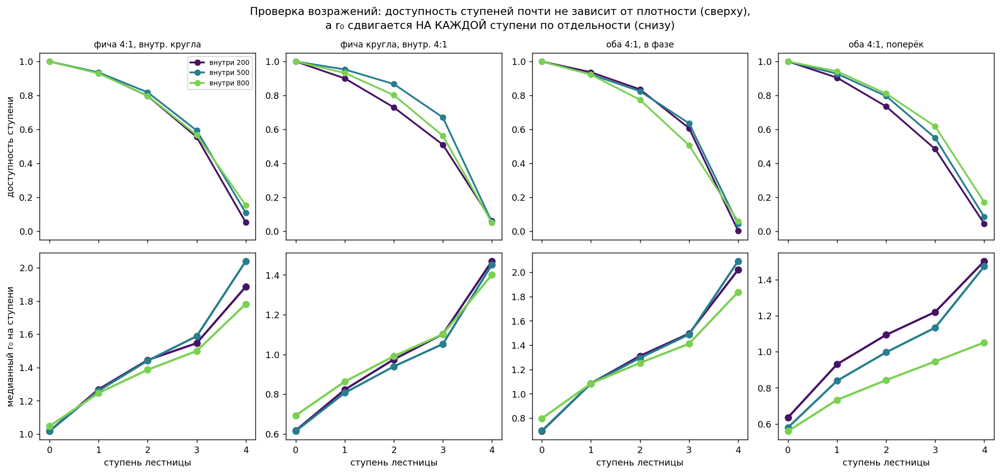

r₀ по ступеням (внутри 200 / 500 / 800):
  фича 4:1, внутр. кругла
    внутри 200: 1.018 1.269 1.445 1.546 1.885
    внутри 500: 1.018 1.261 1.441 1.588 2.039
    внутри 800: 1.047 1.247 1.387 1.499 1.782
  фича кругла, внутр. 4:1
    внутри 200: 0.617 0.822 0.975 1.102 1.469
    внутри 500: 0.614 0.806 0.939 1.052 1.452
    внутри 800: 0.693 0.863 0.990 1.102 1.401
  оба 4:1, в фазе
    внутри 200: 0.692 1.085 1.312 1.495 2.020
    внутри 500: 0.696 1.083 1.295 1.488 2.091
    внутри 800: 0.797 1.084 1.254 1.412 1.837
  оба 4:1, поперёк
    внутри 200: 0.635 0.931 1.093 1.220 1.501
    внутри 500: 0.580 0.839 0.996 1.133 1.472
    внутри 800: 0.560 0.733 0.843 0.946 1.051

«оба 4:1, поперёк»: сдвиг r₀ на каждой ступени -0.076 -0.198 -0.251 -0.274 -0.450 — все пять в одну сторону
доступность внешней ступени при 800 не ниже, а ВЫШЕ, чем при 200, то есть отбор работал бы против наблюдаемого сдвига


In [39]:
# сперва проверка: доступность ступеней и r0 ОТДЕЛЬНО на каждой ступени
fig, axes = plt.subplots(2, 4, figsize=(15.5, 7.4), sharex=True)
DENS = plt.cm.viridis(np.linspace(.05, .8, 3))
for c, (pref, lab) in enumerate(C_GEO):
    for n_in, col in zip(N_IN, DENS):
        name = c_cell(pref, n_in)
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        tot = g.groupby(["model_index", "layer_id", "coord_id"]).ngroups
        axes[0, c].plot(range(5), (g.groupby("rung").size()/tot).reindex(range(5)).values,
                        "o-", color=col, lw=2.0, ms=6, label=f"внутри {n_in}")
        axes[1, c].plot(range(5), g.groupby("rung").r0.median().reindex(range(5)).values,
                        "o-", color=col, lw=2.4, ms=7)
    axes[0, c].set_ylim(-.05, 1.05); axes[0, c].set_title(lab, fontsize=9.5)
    axes[1, c].set_xticks(range(5)); axes[1, c].set_xlabel("ступень лестницы")
axes[0, 0].set_ylabel("доступность ступени"); axes[0, 0].legend(fontsize=7.5)
axes[1, 0].set_ylabel("медианный r₀ на ступени")
fig.suptitle("Проверка возражений: доступность ступеней почти не зависит от плотности (сверху),\n"
             "а r₀ сдвигается НА КАЖДОЙ ступени по отдельности (снизу)", fontsize=12)
plt.tight_layout(); plt.show()

print("r₀ по ступеням (внутри 200 / 500 / 800):")
for pref, lab in C_GEO:
    print(f"  {lab}")
    for n_in in N_IN:
        g = hl[(hl.dataset_type == c_cell(pref, n_in)) & (hl.layer_id > 0)]
        v = g.groupby("rung").r0.median().reindex(range(5))
        print(f"    внутри {n_in}: " + " ".join(f"{x:.3f}" for x in v))
hotname = dict((l, p) for p, l in C_GEO)["оба 4:1, поперёк"]
g2 = hl[(hl.dataset_type == c_cell(hotname, 200)) & (hl.layer_id > 0)].groupby("rung").r0.median()
g8 = hl[(hl.dataset_type == c_cell(hotname, 800)) & (hl.layer_id > 0)].groupby("rung").r0.median()
print(f"\n«оба 4:1, поперёк»: сдвиг r₀ на каждой ступени "
      f"{' '.join(f'{d:+.3f}' for d in (g8 - g2))} — все пять в одну сторону")
print("доступность внешней ступени при 800 не ниже, а ВЫШЕ, чем при 200, "
      "то есть отбор работал бы против наблюдаемого сдвига")


**Возражения сняты.**

- **Доступность ступеней от плотности почти не зависит**: 1.00 / 0.93 / 0.80 / 0.57 / 0.05–0.17
  во всех двенадцати ячейках. Единственное систематическое различие — внешняя ступень, и она
  при 800 точках внутри доступна **чаще** (0.05 → 0.15 и 0.05 → 0.17). Внешняя ступень самая
  далёкая, значит отбор тянул бы медиану **наружу**, а наблюдается сдвиг **внутрь**: артефакт
  работал бы против эффекта, а не в его пользу.
- **Сдвиг есть на каждой ступени по отдельности.** В «оба 4:1, поперёк» от 200 к 800 точкам
  внутри: 0.635 → 0.560, 0.931 → 0.733, 1.093 → 0.843, 1.220 → 0.946, 1.501 → 1.051 — **все пять
  ступеней уезжают внутрь**, и чем дальше ступень, тем сильнее. Композицией это не объяснить.
- **В неотзывчивой геометрии** («фича кругла, внутренность 4:1») ступени двигаются в
  противоположную сторону и слабо: 0.617 → 0.693, 0.822 → 0.863, 0.975 → 0.990. Там же не
  менялась и вытянутость.

Значит величина измеряет настоящее свойство поля, а не свойство процедуры описания. Дальше можно
смотреть на медиану по всем ступеням как на сводку — с оговоркой, что она подтверждена ступень
за ступенью.


### Цепочка, которую проверяем

1. Плотность геометрию не меняет — в строке она побитово одна.
2. Зато она меняет, **где поле совершает переход**: чем больше точек внутри, тем ближе к
   внутренности собирается складка, то есть тем меньше `r₀` каждой ступени.
3. А форма кривой, как установлено в 2.2.3, определяется тем, **насколько кривая отошла от
   внутренности**: близко — почти копия внутренности, далеко — почти окружность.
4. Значит **плотность → положение складки → форма**, и напрямую на форму плотность не действует.

Ниже это видно на самих кривых, а потом проверено числом.


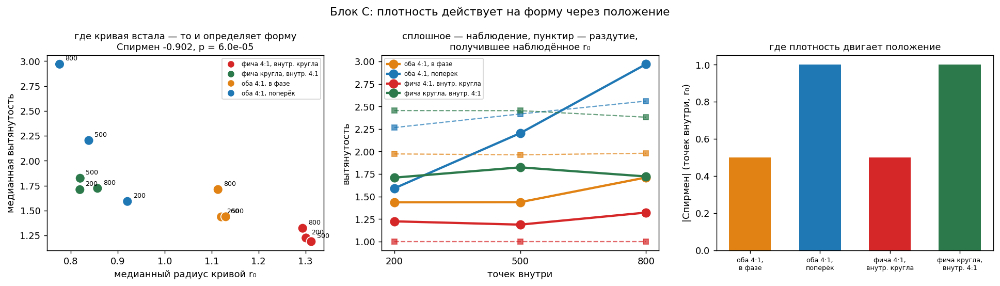

оба 4:1, в фазе          r₀ 1.121 → 1.130 → 1.114 | набл 1.44 → 1.44 → 1.71 | модель 1.97 → 1.96 → 1.98
оба 4:1, поперёк         r₀ 0.921 → 0.838 → 0.776 | набл 1.59 → 2.20 → 2.97 | модель 2.27 → 2.42 → 2.56
фича 4:1, внутр. кругла  r₀ 1.301 → 1.312 → 1.294 | набл 1.22 → 1.19 → 1.32 | модель 1.00 → 1.00 → 1.00
фича кругла, внутр. 4:1  r₀ 0.819 → 0.820 → 0.857 | набл 1.71 → 1.82 → 1.72 | модель 2.45 → 2.45 → 2.38

Спирмен(r₀, вытянутость) по 12 ячейкам: -0.902
Спирмен(точек внутри, r₀) внутри геометрий: оба 4:1, в фазе -0.5, оба 4:1, поперёк -1.0, фича 4:1, внутр. к -0.5, фича кругла, внутр +1.0
средняя |ошибка| модели на блоке C: 0.450


In [40]:
obsC = CC.set_index("ячейка")[["r0", "аспект"]].rename(columns={"аспект": "aspect"})
DC = gs.dilation_model(obsC)
CC3 = CC.merge(DC[["dataset_type", "predicted_aspect", "delta"]],
               left_on="ячейка", right_on="dataset_type")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].scatter(CC3.r0, CC3.аспект, s=110, c=[GC[l] for l in CC3.геометрия],
                edgecolor="white", zorder=3)
for _, r in CC3.iterrows():
    axes[0].annotate(int(r.внутри), (r.r0, r.аспект), fontsize=7,
                     textcoords="offset points", xytext=(6, 4))
rho, pv = spearmanr(CC3.r0, CC3.аспект)
axes[0].set_xlabel("медианный радиус кривой r₀"); axes[0].set_ylabel("медианная вытянутость")
axes[0].set_title(f"где кривая встала — то и определяет форму\nСпирмен {rho:+.3f}, p = {pv:.1e}",
                  fontsize=10)
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=l)
                        for l, c in GC.items()], fontsize=6.5)

for lab, g in CC3.groupby("геометрия"):
    g = g.sort_values("внутри")
    axes[1].plot(g.внутри, g.аспект, "o-", color=GC[lab], lw=2.4, ms=9, label=lab)
    axes[1].plot(g.внутри, g.predicted_aspect, "s--", color=GC[lab], lw=1.3, ms=6, alpha=.7)
axes[1].set_xticks(N_IN); axes[1].set_xlabel("точек внутри"); axes[1].set_ylabel("вытянутость")
axes[1].legend(fontsize=6.5)
axes[1].set_title("сплошное — наблюдение, пунктир — раздутие,\nполучившее наблюдённое r₀",
                  fontsize=10)

axes[2].bar(range(4), [abs(spearmanr(g.sort_values("внутри").внутри,
                                     g.sort_values("внутри").r0)[0])
                       for _, g in CC3.groupby("геометрия")],
            color=[GC[l] for l, _ in CC3.groupby("геометрия")], width=.6)
axes[2].set_xticks(range(4), [l.replace(", ", ",\n") for l, _ in CC3.groupby("геометрия")],
                   fontsize=7)
axes[2].set_ylabel("|Спирмен| (точек внутри, r₀)"); axes[2].set_ylim(0, 1.05)
axes[2].set_title("где плотность двигает положение", fontsize=10)
fig.suptitle("Блок C: плотность действует на форму через положение", fontsize=12)
plt.tight_layout(); plt.show()

for lab, g in CC3.groupby("геометрия"):
    g = g.sort_values("внутри")
    print(f"{lab:24s} r₀ {' → '.join(f'{x:.3f}' for x in g.r0)} | "
          f"набл {' → '.join(f'{x:.2f}' for x in g.аспект)} | "
          f"модель {' → '.join(f'{x:.2f}' for x in g.predicted_aspect)}")
print(f"\nСпирмен(r₀, вытянутость) по 12 ячейкам: {spearmanr(CC3.r0, CC3.аспект)[0]:+.3f}")
print("Спирмен(точек внутри, r₀) внутри геометрий: " + ", ".join(
    f"{l[:18]} {spearmanr(g.внутри, g.r0)[0]:+.1f}" for l, g in CC3.groupby("геометрия")))
print(f"средняя |ошибка| модели на блоке C: "
      f"{np.abs(CC3.predicted_aspect - CC3.аспект).mean():.3f}")


**Наблюдения.**

- **Складка смещается.** На картинке три ячейки одной геометрии: при 200 точках внутри семейство
  стоит на `r₀ = 0.92`, при 800 — на `0.78`, то есть примерно на **16 % ближе к внутренности**.
  Формы объектов при этом побитово те же.
- **Положение объясняет форму почти целиком.** По двенадцати ячейкам блока
  Спирмен(`r₀`, вытянутость) = **−0.90**: чем ближе складка к внутренности, тем вытянутее кривые.
  Это ровно то, что говорит конструкция раздутия, и здесь проверено **внутри одной геометрии**,
  где больше меняться нечему.
- **Плотность двигает складку там, и только там, где двигает форму.** Ранговая связь «точек
  внутри → `r₀`» равна −1.0 в «поперёк», −0.5 в двух геометриях и **+1.0 в «фича кругла,
  внутренность 4:1»** — ровно в той, где вытянутость **не менялась** (p = 0.71 из C.2).
  Совпадение исключения по двум независимым признакам — сильный аргумент за цепочку.
- **Модель, получив наблюдённое положение, воспроизводит направление, но не величину**:
  2.27 → 2.42 → 2.56 против наблюдаемых 1.59 → 2.20 → 2.97. Положение — необходимая часть
  объяснения, но недостаточная: наблюдаемый рост втрое круче предсказанного.
- **Средняя ошибка модели на блоке C — 0.45**, заметно хуже, чем на блоке A.

**Вывод.** Плотность описания действует на форму **не напрямую**: она сдвигает место, где поле
совершает переход, — туда, где точек больше, — а форма следует за этим положением по закону,
найденному в 2.2.3 на чистой геометрии. Правильная формулировка: **форма есть функция того, где
встала складка**, а где она встала — определяют и геометрия пары, и распределение данных.

**Чего эта величина не говорит.** `r₀` ступени — характеристика **одной** кривой из
бесконечного семейства, выбранной правилом по значению поля. Она не описывает поле целиком и не
является «размером линий уровня нейрона»; она говорит только, на каком расстоянии поле проходит
заданную долю пути между классами. Всё сказанное выше — про эту величину и ни про какую другую.


## 4.5 Свидетельство и скор

Последнее: что плотность делает со структурным критерием, то есть с тем, ради чего эксперимент
затевался.


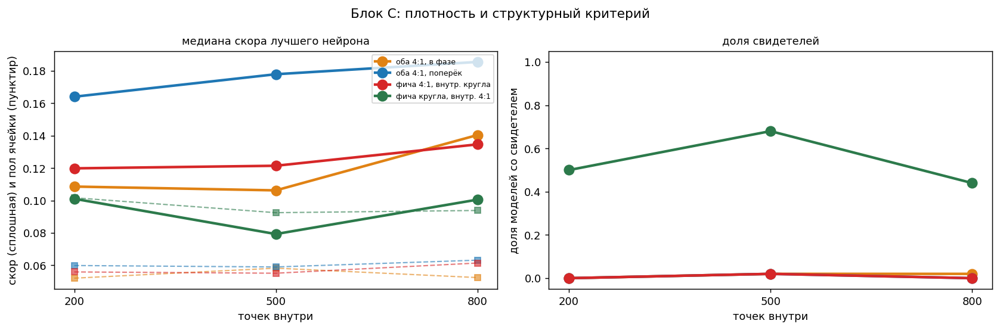

              геометрия  внутри  скор   пол  свид
фича 4:1, внутр. кругла     200 0.120 0.056  0.00
фича 4:1, внутр. кругла     500 0.121 0.055  0.02
фича 4:1, внутр. кругла     800 0.135 0.061  0.00
фича кругла, внутр. 4:1     200 0.101 0.102  0.50
фича кругла, внутр. 4:1     500 0.079 0.092  0.68
фича кругла, внутр. 4:1     800 0.101 0.094  0.44
        оба 4:1, в фазе     200 0.109 0.052  0.00
        оба 4:1, в фазе     500 0.106 0.058  0.02
        оба 4:1, в фазе     800 0.140 0.052  0.02
       оба 4:1, поперёк     200 0.164 0.060  0.00
       оба 4:1, поперёк     500 0.178 0.059  0.02
       оба 4:1, поперёк     800 0.186 0.063  0.00

скор при 800 точках внутри хуже, чем при 200, в 3 геометриях из 4
пол ячейки при этом почти неподвижен: размах внутри геометрий {'оба 4:1, в фазе': 0.006, 'оба 4:1, поперёк': 0.004, 'фича 4:1, внутр. кругла': 0.006, 'фича кругла, внутр. 4:1': 0.009}


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for lab, g in CC3.groupby("геометрия"):
    g = g.sort_values("внутри")
    axes[0].plot(g.внутри, g.скор, "o-", color=GC[lab], lw=2.4, ms=9, label=lab)
    axes[0].plot(g.внутри, g.пол, "s--", color=GC[lab], lw=1.2, ms=5, alpha=.6)
axes[0].set_xticks(N_IN); axes[0].set_xlabel("точек внутри")
axes[0].set_ylabel("скор (сплошная) и пол ячейки (пунктир)"); axes[0].legend(fontsize=7)
axes[0].set_title("медиана скора лучшего нейрона", fontsize=10)
for lab, g in CC3.groupby("геометрия"):
    g = g.sort_values("внутри")
    axes[1].plot(g.внутри, g.свид, "o-", color=GC[lab], lw=2.4, ms=9)
axes[1].set_xticks(N_IN); axes[1].set_xlabel("точек внутри")
axes[1].set_ylabel("доля моделей со свидетелем"); axes[1].set_ylim(-.05, 1.05)
axes[1].set_title("доля свидетелей", fontsize=10)
fig.suptitle("Блок C: плотность и структурный критерий", fontsize=12)
plt.tight_layout(); plt.show()

print(CC3[["геометрия", "внутри", "скор", "пол", "свид"]].round(3).to_string(index=False))
worse = sum(int(g.sort_values("внутри").скор.iloc[-1] > g.sort_values("внутри").скор.iloc[0])
            for _, g in CC3.groupby("геометрия"))
print(f"\nскор при 800 точках внутри хуже, чем при 200, в {worse} геометриях из 4")
print(f"пол ячейки при этом почти неподвижен: размах внутри геометрий "
      f"{CC3.groupby('геометрия').пол.apply(lambda s: s.max()-s.min()).round(3).to_dict()}")


**Наблюдения.**

- **Скор ухудшается по мере того, как точки переносятся с фичи внутрь, во всех четырёх
  геометриях**: 0.109 → 0.140,
  0.164 → 0.186, 0.120 → 0.135 и 0.101 → 0.101 (последняя через минимум 0.079 при равной
  плотности). Пол ячейки при этом почти неподвижен (размах 0.004–0.010), то есть ухудшение
  настоящее, а не сдвиг шкалы.
- **Доля свидетелей почти везде нулевая**, потому что в трёх геометриях из четырёх фича вытянута
  и свидетельствовать нечего. Единственная живая — «фича кругла, внутренность 4:1», и там доля
  немонотонна: **0.50 → 0.68 → 0.44**, с максимумом при равной плотности.
- Этот максимум согласуется с найденным в эксперименте 4: одинаковое число точек на объектах —
  не нейтральная точка, а лучшая для детектора.


## 4.6 Итог блока C

1. **Плотность описания двигает форму линии уровня** при побитово одинаковой геометрии: в самой
   напряжённой геометрии медиана растёт **1.59 → 2.97**, доля сильно вытянутых кривых —
   **0.34 → 0.86**. Сдвиг популяционный (92 % моделей) и охватывает всё семейство ступеней.
2. **Это прямое ограничение на конструкции из 2.2.3**: из одной геометрии форма не выводится.
3. **Вторично и с оговорками — о том, через что она действует.** Величина, которая это ловит, — радиус
   ступени лестницы: ступень `k` есть кривая, на которой поле прошло `k/4` пути между классами,
   и её радиус говорит, на каком расстоянии это произошло. Спирмен(`r₀`, вытянутость) = **−0.90**
   по двенадцати ячейкам; ранговая связь «точек внутри → `r₀`» отрицательна там, где вытянутость
   растёт, и **положительна ровно в той геометрии, где вытянутость не менялась**. Сдвиг проверен
   **на каждой ступени по отдельности**, так что ни отбор ступеней, ни композиция его не
   объясняют — тем более что доступность внешней ступени при плотной внутренности выше, то есть
   артефакт работал бы против эффекта.
4. **Направление при этом не меняется**: в «поперёк» доля кривых поперёк остаётся 0.87–0.95.
   Плотность меняет величину вытянутости и её упорядоченность, но не разворачивает кривую.
5. **Положения недостаточно для величины**: модель, получив наблюдённое `r₀`, даёт рост
   2.27 → 2.56 против наблюдаемого 1.59 → 2.97.
6. **Скор ухудшается по мере переноса точек с фичи внутрь** (200 → 800 точек внутри) во всех
   четырёх геометриях при почти неподвижном
   поле; доля свидетелей максимальна при равной плотности.
7. **Диагональные направления.** При 800 точках внутри в трёх геометриях из четырёх больше
   половины кривых уходят под ≈45° (доля косых 0.13 → 0.59, 0.19 → 0.54, 0.07 → 0.24), в том
   числе там, где оба объекта вытянуты вдоль одной оси. Явление устойчивое и необъяснённое.
8. **Формулировка после блока C.** Твёрдое: форма линии уровня **не является функцией одной
   геометрии пары** — при побитово той же геометрии она меняется вдвое от того, как распределены
   точки. Правдоподобное, но вторичное: действует плотность не на форму напрямую, а на то, где
   поле совершает переход, а форма следует за этим по закону из 2.2.3. Блоки A и B измеряли
   геометрическую половину при фиксированной второй.


# 5. Блок D. Положение: что происходит, когда объекты перестают быть концентричными

## Постановка

Все предыдущие блоки держали объекты **концентричными**. Это удобно и это же ограничение: пока
центры совпадают, у пары нет выделенного направления смещения, и вопрос «куда встанет кривая»
не имеет содержания — она встанет вокруг общего центра. Блок D снимает это ограничение.

**Двадцать три ячейки.** Пять геометрий пары × два направления сдвига × три положения:

| геометрия пары | что в ней особенного |
|---|---|
| круг в круге | нет выделенного направления ни у одного объекта |
| круг в эллипсе | направление есть только у фичи |
| эллипс в круге | направление есть только у внутренности |
| эллипс в эллипсе | оба вдоль одной оси |
| эллипс ⊥ эллипса | оси объектов перпендикулярны |

Направления сдвига — **вдоль** длинной оси фичи (ось x) и **поперёк** (ось y). Положения — 0 %,
50 % и 100 % от **наибольшего сдвига, который эта пара допускает**: внутренность обязана остаться
внутри фичи с зазором. Доля нужна потому, что абсолютное место различается всемеро: вдоль x при
вытянутой фиче внутренность можно увести на 5.25, поперёк — только на 1.12. У круглой пары
направления неразличимы, поэтому там три ячейки, а не пять.

**Внутренность здесь вдвое меньше**, чем в блоках A–C (`interior_scale = 0.5`), — иначе двигать
её было бы некуда.

**Главная величина блока — не форма, а положение.** Для каждой описанной кривой берётся её
центроид, и меряются **два расстояния**: до центра фичи (он же начало координат) и до центра
уехавшей внутренности. Пара этих чисел говорит всё: если кривая осталась при фиче, первое мало,
а второе равно сдвигу; если ушла за внутренностью — наоборот.

**Как считается агрегат — здесь и во всём блоке D.** Единица наблюдения — **отдельная описанная
кривая**: пара (нейрон, ступень лестницы). В ячейке их около 2 400: 50 моделей × 20 нейронов
слоёв 1–4 × до 5 ступеней, минус те, где замкнутой кривой не нашлось. По этим примерно 2 400
кривым берётся **медиана** — не среднее (устойчивость к хвостам) и не экстремум по моделям
(экстремум использовался в блоке A, где вопрос стоял «есть ли хоть один такой нейрон»; здесь
вопрос другой — «куда встаёт семейство целиком»). Никакого предварительного усреднения по
нейронам или по моделям не делается: медиана берётся сразу по всем кривым. Там, где величина
смотрится по ступеням отдельно, это сказано явно.

Отношение этих двух расстояний — это `λ_pos`, «доля пройденного пути от фичи к внутренности»:
0 — кривая у центра фичи, 1 — у центра внутренности. Оно появляется дальше как краткая сводка,
но основным показывается сама пара расстояний, потому что она определена и при нулевом сдвиге.

Форма (вытянутость и направление) остаётся здесь **второй** величиной: в блоке D она в основном
следствие того, куда кривую прижало.


## 5.1 Датасеты

Двадцать три конфигурации: пять геометрий (строки) × пять положений (0 %, 50 % и 100 % вдоль x, 50 % и 100 % поперёк). У круглой пары направления неразличимы, поэтому две ячейки пустые.


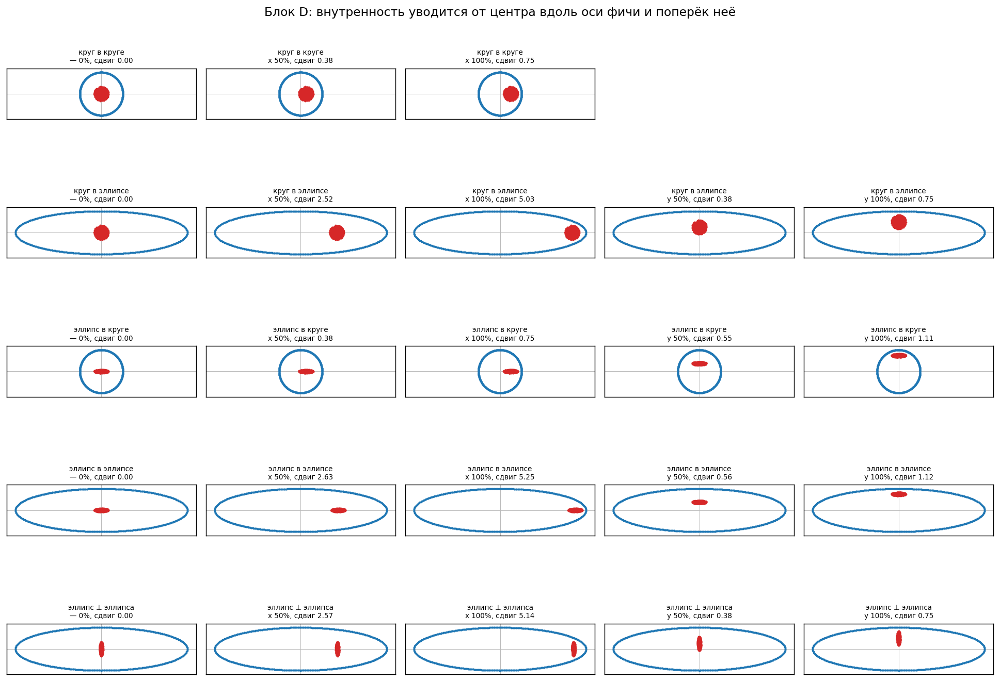

наибольший допустимый сдвиг по семействам (это и есть «100 %»):
  круг в круге         x: 0.75
  круг в эллипсе       x: 5.03   y: 0.75
  эллипс в круге       x: 0.75   y: 1.11
  эллипс в эллипсе     x: 5.25   y: 1.12
  эллипс ⊥ эллипса     x: 5.14   y: 0.75


In [42]:
D_FAM = ["круг в круге", "круг в эллипсе", "эллипс в круге", "эллипс в эллипсе",
         "эллипс ⊥ эллипса"]
D_POS = [("x", "0%"), ("x", "50%"), ("x", "100%"), ("y", "50%"), ("y", "100%")]

Dm = cells_meta[cells_meta.block == "D"].copy()
Dm["пара"] = [str(l).split(",")[0].strip() for l in Dm.label]
Dm["ось"] = [str(l).split(",")[1].strip() if len(str(l).split(",")) > 2 else "-"
             for l in Dm.label]
Dm["доля"] = [str(l).split(",")[-1].strip() for l in Dm.label]

def d_cell(fam, axis, frac):
    q = Dm[(Dm.пара == fam) & (Dm.доля == frac)]
    if frac == "0%":
        return q.index[0] if len(q) else None
    q = q[q.ось == axis]
    return q.index[0] if len(q) else None

hxD = hyD = 0.0
for fam in D_FAM:
    for ax, fr in D_POS:
        n = d_cell(fam, ax, fr)
        if n is None:
            continue
        h1, h2 = gp.cells_extent([n])
        hxD, hyD = max(hxD, h1), max(hyD, h2)

fig, axes = plt.subplots(5, 5, figsize=(15, 11))
for r, fam in enumerate(D_FAM):
    for c, (ax_, fr) in enumerate(D_POS):
        ax = axes[r, c]; name = d_cell(fam, ax_, fr)
        if name is None:
            ax.axis("off"); continue
        Xc, yc, Ac = gs.dataset_points(name)[:3]
        ax.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=1.3, c=gp.C_INTERIOR, zorder=1)
        ax.scatter(Ac[:, 0], Ac[:, 1], s=1.3, c=gp.C_FEATURE, zorder=2)
        ax.axhline(0, color="#bbb", lw=.6, zorder=0); ax.axvline(0, color="#bbb", lw=.6, zorder=0)
        ax.set_xlim(-hxD, hxD); ax.set_ylim(-hyD, hyD)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        off = float(cells_meta.loc[name, "offset_norm"])
        ax.set_title(f"{fam}\n{ax_ if fr != '0%' else '—'} {fr}, сдвиг {off:.2f}", fontsize=7.5)
fig.suptitle("Блок D: внутренность уводится от центра вдоль оси фичи и поперёк неё", fontsize=13)
plt.tight_layout(); plt.show()

print("наибольший допустимый сдвиг по семействам (это и есть «100 %»):")
for fam in D_FAM:
    line = []
    for ax_ in ("x", "y"):
        n = d_cell(fam, ax_, "100%")
        if n is not None:
            line.append(f"{ax_}: {float(cells_meta.loc[n, 'offset_norm']):.2f}")
    print(f"  {fam:20s} " + "   ".join(line))


## 5.2 Идёт ли кривая за внутренностью

Десять панелей: пять геометрий пары × два направления сдвига. В каждой — **два расстояния от
центроида кривой**: до центра внутренности (сплошная) и до центра фичи (пунктир), плюс серая
линия «расстояние между самими центрами», то есть величина сдвига.

Читается так: если сплошная лежит внизу, а пунктир идёт вверх вместе с серой — **кривая ушла за
внутренностью**. Если наоборот, пунктир внизу, а сплошная поднимается вдоль серой — **кривая
осталась при фиче**.

Каждая точка — медиана по всем примерно 2 400 кривым ячейки (50 моделей × 20 нейронов слоёв 1–4 ×
до 5 ступеней), как описано в постановке.


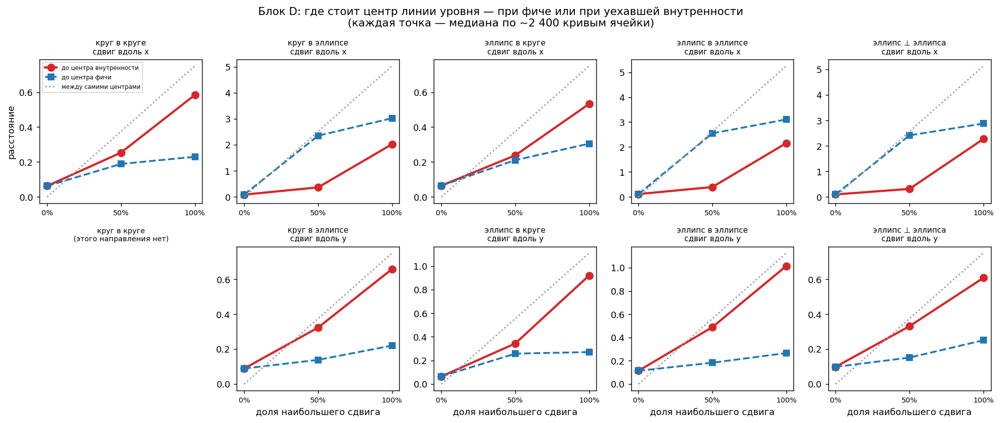

            пара ось доля  сдвиг  до_внутр  до_фичи   lam
    круг в круге   x   0%  0.000     0.063    0.063   NaN
    круг в круге   x  50%  0.375     0.254    0.189 0.324
    круг в круге   x 100%  0.750     0.584    0.230 0.221
    круг в круге   y   0%  0.000     0.063    0.063   NaN
  круг в эллипсе   x   0%  0.000     0.089    0.089   NaN
  круг в эллипсе   x  50%  2.516     0.366    2.352 0.854
  круг в эллипсе   x 100%  5.031     2.025    3.024 0.598
  круг в эллипсе   y   0%  0.000     0.089    0.089   NaN
  круг в эллипсе   y  50%  0.375     0.324    0.139 0.137
  круг в эллипсе   y 100%  0.750     0.659    0.220 0.122
  эллипс в круге   x   0%  0.000     0.065    0.065   NaN
  эллипс в круге   x  50%  0.375     0.238    0.211 0.366
  эллипс в круге   x 100%  0.750     0.533    0.305 0.290
  эллипс в круге   y   0%  0.000     0.065    0.065   NaN
  эллипс в круге   y  50%  0.555     0.344    0.258 0.380
  эллипс в круге   y 100%  1.109     0.920    0.271 0.170
эллипс в эллип

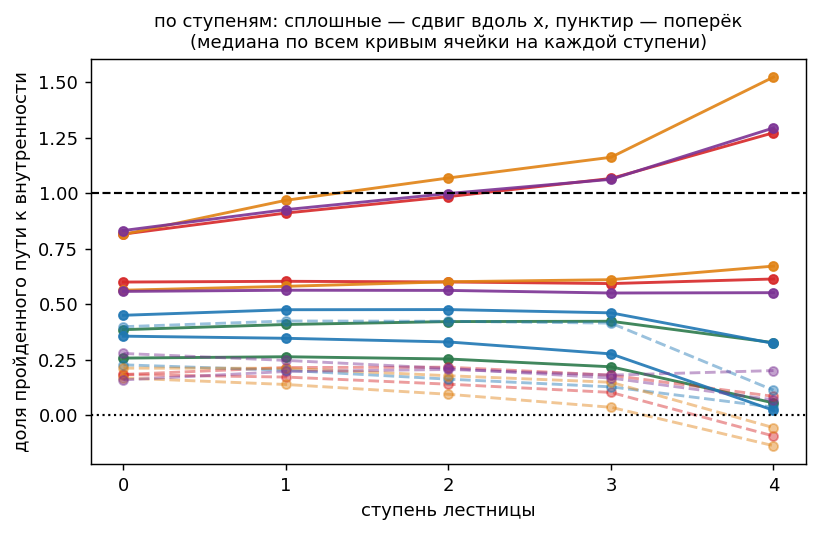

In [43]:
rowsD = []
for fam in D_FAM:
    for ax_, fr in D_POS:
        name = d_cell(fam, ax_, fr)
        if name is None or fr == "0%":
            continue
        m = cells_meta.loc[name]
        off = np.array([float(CO.loc[name, "offset_x"]), float(CO.loc[name, "offset_y"])])
        nrm = float(np.hypot(*off)); u = off/nrm
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        lam = (g.cx*u[0] + g.cy*u[1])/nrm
        gg = g[g.a2 >= .10]; a = gg.angle2.values
        rowsD.append(dict(пара=fam, ось=ax_, доля=fr, сдвиг=nrm, ячейка=name,
                          lam=float(lam.median()),
                          lam_по_ступеням=lam.groupby(g.rung).median().reindex(range(5)).values,
                          аспект=float(g.aspect.median()),
                          вдоль=float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan,
                          поперёк=float(((a > 60) & (a < 120)).mean()) if len(a) else np.nan,
                          скор=float(m.target_median), пол=float(m.floor), свид=float(m.rate_floor)))
DD = pd.DataFrame(rowsD)
FC = dict(zip(D_FAM, ["#2c7a4b", "#d62728", "#1f77b4", "#e08214", "#7b3294"]))

def d_pair(name):
    m = CO.loc[name]
    c = np.array([float(m.offset_x), float(m.offset_y)])
    g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
    return (float(np.hypot(g.cx - c[0], g.cy - c[1]).median()),   # до внутренности
            float(np.hypot(g.cx, g.cy).median()),                 # до фичи
            float(np.hypot(*c)))

fig, axes = plt.subplots(2, 5, figsize=(15.5, 6.6))
FR = [0.0, 0.5, 1.0]; FRL = ["0%", "50%", "100%"]
for r, axis in enumerate(("x", "y")):
    for c, fam in enumerate(D_FAM):
        ax = axes[r, c]
        names = [d_cell(fam, axis, fl) for fl in FRL]
        if any(n is None for n in names):
            ax.axis("off")
            ax.set_title(f"{fam}\n(этого направления нет)", fontsize=8); continue
        vals = [d_pair(n) for n in names]
        ax.plot(FR, [v[0] for v in vals], "o-", color=gp.C_INTERIOR, lw=2.4, ms=8,
                label="до центра внутренности")
        ax.plot(FR, [v[1] for v in vals], "s--", color=gp.C_FEATURE, lw=2.0, ms=7,
                label="до центра фичи")
        ax.plot(FR, [v[2] for v in vals], color="#999", lw=1.6, ls=":",
                label="между самими центрами")
        ax.set_xticks(FR, FRL, fontsize=8)
        ax.set_title(f"{fam}\nсдвиг вдоль {axis}", fontsize=8.5)
        if c == 0:
            ax.set_ylabel("расстояние")
        if r == 1:
            ax.set_xlabel("доля наибольшего сдвига")
axes[0, 0].legend(fontsize=6.5)
fig.suptitle("Блок D: где стоит центр линии уровня — при фиче или при уехавшей внутренности\n"
             "(каждая точка — медиана по ~2 400 кривым ячейки)", fontsize=12)
plt.tight_layout(); plt.show()

rows = []
for fam in D_FAM:
    for axis in ("x", "y"):
        for fl in FRL:
            n = d_cell(fam, axis, fl)
            if n is None:
                continue
            di, df, sh = d_pair(n)
            rows.append(dict(пара=fam, ось=axis, доля=fl, сдвиг=sh,
                             до_внутр=di, до_фичи=df,
                             lam=np.nan if sh == 0 else (sh - di)/sh))
DIST = pd.DataFrame(rows).drop_duplicates(subset=["пара", "ось", "доля"])
print(DIST.round(3).to_string(index=False))

print("\nкраткая сводка тем же числом, что раньше называлось λ_pos "
      "(доля пройденного пути от фичи к внутренности):")
WIDE = ["круг в эллипсе", "эллипс в эллипсе", "эллипс ⊥ эллипса"]   # фича 4:1
for frac in ("50%", "100%"):
    g = DIST[(DIST.ось == "x") & (DIST.доля == frac) & (DIST.пара.isin(WIDE))]
    h = DIST[(DIST.ось == "x") & (DIST.доля == frac) & (~DIST.пара.isin(WIDE))]
    print(f"  вдоль x при {frac:>4}: {g.lam.min():.2f}…{g.lam.max():.2f} там, где фича вытянута; "
          f"{h.lam.min():.2f}…{h.lam.max():.2f} где кругла")
y = DIST[(DIST.ось == "y") & (DIST.доля != "0%")]
print(f"  поперёк, любой сдвиг: {y.lam.min():.2f}…{y.lam.max():.2f}")

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for r_, row in DD.iterrows():
    ax.plot(range(5), row.lam_по_ступеням, "o-", color=FC[row.пара], lw=1.6, ms=5,
            alpha=.9 if row.ось == "x" else .45, ls="-" if row.ось == "x" else "--")
ax.axhline(1, color="k", ls="--", lw=1.2); ax.axhline(0, color="k", ls=":", lw=1.2)
ax.set_xticks(range(5)); ax.set_xlabel("ступень лестницы")
ax.set_ylabel("доля пройденного пути к внутренности")
ax.set_title("по ступеням: сплошные — сдвиг вдоль x, пунктир — поперёк\n"
             "(медиана по всем кривым ячейки на каждой ступени)", fontsize=10)
plt.tight_layout(); plt.show()


**Наблюдения.** Все числа — медианы по примерно 2 400 кривым ячейки.

- **Вдоль длинной оси вытянутой фичи кривая почти догоняет внутренность.** При сдвиге на половину
  допустимого центр кривой стоит в **0.31–0.40** от центра внутренности и в **2.35–2.55** от центра
  фичи, при том что сами центры разъехались на 2.5–2.6. То есть кривая прошла **85–88 %** пути.
- **При максимальном сдвиге она перестаёт успевать**: расстояния становятся 2.03–2.27 до
  внутренности и 2.88–3.11 до фичи при сдвиге 5.0–5.3 — пройдено **56–60 %**. Внутренность
  прижата к концу фичи, и кривая застревает примерно на полпути.
- **Поперёк она почти не идёт.** «Эллипс в эллипсе», сдвиг поперёк на максимум: центры разъехались
  на 1.13, а кривая стоит в **1.01** от внутренности и всего в **0.27** от фичи — пройдено **10 %**.
  По всем поперечным ячейкам — 0.10–0.38.
- **Там, где фича не вытянута, следование слабое и вдоль x тоже**: круглая пара проходит 0.32 и
  0.22 пути, «эллипс в круге» — 0.37 и 0.29. Дело не в направлении как таковом, а в том, есть ли
  в этом направлении место: у круглой фичи его нет ни вдоль, ни поперёк.
- **При нулевом сдвиге обе величины равны и малы** (0.06–0.11) — кривые стоят на общем центре, как
  и должно быть. Это опорная точка, а не результат.
- **За внутренностью идёт всё семейство**, но ход по ступеням у двух направлений
  **противоположный**. При сдвиге вдоль x внешние ступени следуют **охотнее**: доля пройденного
  пути растёт от 0.82 на ступени 0 до 1.0–1.5 на ступени 4, то есть дальние кривые уходят даже с
  перелётом. При сдвиге поперёк — наоборот, к внешней ступени следование **сходит на нет**. Вдоль
  оси фичи места хватает и дальше от центра; поперёк дальние кривые упираются в стенку и остаются
  при фиче.

**Вывод.** Разделяющая кривая идёт за внутренностью **настолько, насколько ей позволяет фича**.
Это первый блок, где фича проявляется как ограничитель напрямую и в одной величине: там, где она
оставляет место, следование почти полное; там, где не оставляет, его почти нет.


## 5.3 Что при этом становится с формой

Форма здесь величина вторая, но ведёт себя неожиданно. Сперва вытянутость, потом направление.

**Про направление важно смотреть на розы, а не на доли**, потому что доли «вдоль» и «поперёк» —
это два числа из трёх (третье, косое, обычно забывают), и по ним нельзя отличить «направление
исчезло» от «направление сменилось». Розы показывают всё распределение сразу.

**Что в сетке роз.** Строка — семейство пар, четыре столбца:

1. **для сравнения** — та же геометрия с **полноразмерной** внутренностью и без сдвига, то есть
   ячейка из блоков A, B или C. Она нужна, чтобы отделить эффект уменьшения внутренности от
   эффекта сдвига;
2. **0 %** — внутренность уже уменьшена вдвое, но не сдвинута;
3. **50 %** и 4. **100 %** — она же, сдвинутая.

В углу каждой панели нарисован сам датасет. Роза строится по всем кривым ячейки, прошедшим фильтр
`a₂ ≥ 0.10`; в подписи — доля прошедших и медианная вытянутость.


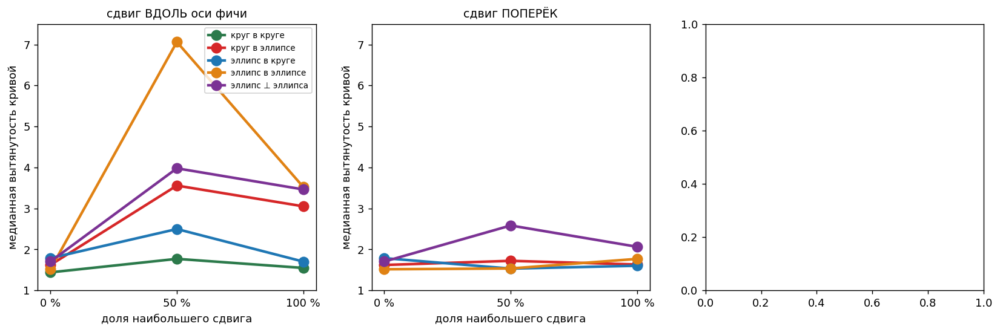

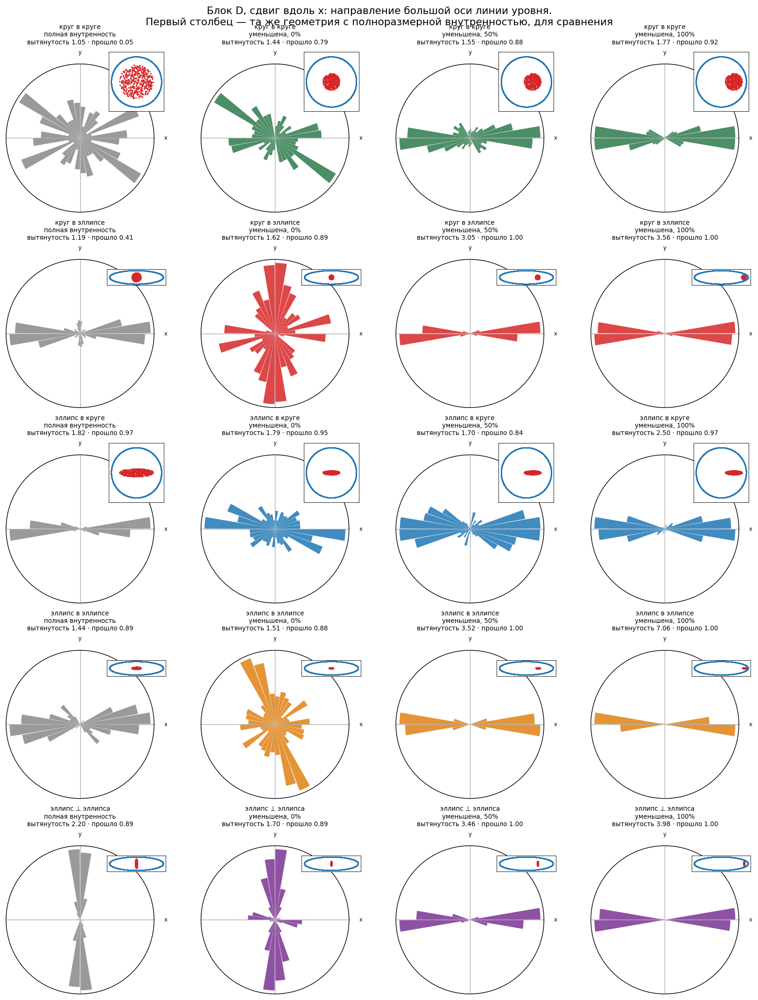

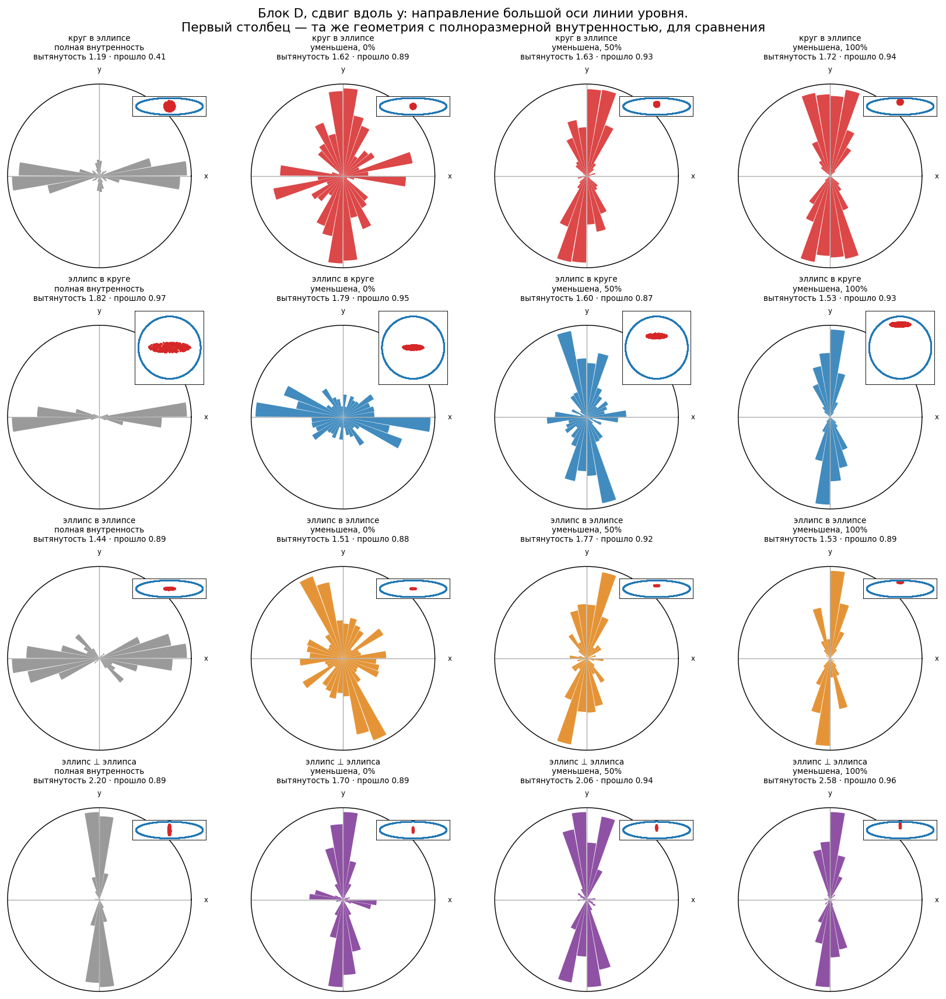

что делает уже само уменьшение внутренности (сдвига нет):
  круг в круге         полная: вытянутость 1.05, вдоль 0.38, поперёк 0.29, прошло 0.05  →  уменьшенная: 1.44, 0.38, 0.23, 0.79
  круг в эллипсе       полная: вытянутость 1.19, вдоль 0.74, поперёк 0.17, прошло 0.41  →  уменьшенная: 1.62, 0.26, 0.52, 0.89
  эллипс в круге       полная: вытянутость 1.82, вдоль 0.97, поперёк 0.00, прошло 0.97  →  уменьшенная: 1.79, 0.54, 0.20, 0.95
  эллипс в эллипсе     полная: вытянутость 1.44, вдоль 0.80, поперёк 0.01, прошло 0.89  →  уменьшенная: 1.51, 0.29, 0.48, 0.88
  эллипс ⊥ эллипса     полная: вытянутость 2.20, вдоль 0.04, поперёк 0.95, прошло 0.89  →  уменьшенная: 1.70, 0.22, 0.74, 0.89


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
for ax, axis, ttl in [(axes[0], "x", "сдвиг ВДОЛЬ оси фичи"),
                      (axes[1], "y", "сдвиг ПОПЕРЁК")]:
    for fam in D_FAM:
        n0 = d_cell(fam, axis, "0%")
        g = DD[(DD.пара == fam) & (DD.ось == axis)].sort_values("доля")
        if not len(g):
            continue
        a0 = float(hl[(hl.dataset_type == n0) & (hl.layer_id > 0)].aspect.median())
        ax.plot([0, .5, 1.], [a0] + list(g.аспект), "o-", color=FC[fam], lw=2.4, ms=9,
                label=fam)
    ax.set_xticks([0, .5, 1.], ["0 %", "50 %", "100 %"])
    ax.set_xlabel("доля наибольшего сдвига"); ax.set_ylabel("медианная вытянутость кривой")
    ax.set_ylim(1, 7.5); ax.set_title(ttl, fontsize=10.5)
axes[0].legend(fontsize=7.5)

FULL = {"круг в круге": "g5_f010_i010_s100_o+0000+0000",
        "круг в эллипсе": "g5_f040_i010_s100_o+0000+0000",
        "эллипс в круге": "g5_f010_i040_s100_o+0000+0000",
        "эллипс в эллипсе": "g5_f040_i040_s100_o+0000+0000",
        "эллипс ⊥ эллипса": "g5_f040_i040T_s100_o+0000+0000"}

def rose_panel(ax, name, title, colour):
    g_all = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
    g = g_all[g_all.a2 >= .10]; a = g.angle2.values
    both = np.concatenate([np.radians(a), np.radians(a) + np.pi]) % (2*np.pi)
    edges = np.radians(np.arange(0, 361, 10))
    h, _ = np.histogram(both, bins=edges); h = h/max(h.max(), 1)
    ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4), color=colour,
           alpha=.85, edgecolor="none")
    ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
    ax.set_xticklabels(["x", "y", "", ""], fontsize=6.5)
    ax.set_title(f"{title}\nвытянутость {g_all.aspect.median():.2f} · "
                 f"прошло {len(g)/max(len(g_all),1):.2f}", fontsize=7.5, pad=6)
    ins = ax.inset_axes([.68, .68, .40, .40])
    Xc, yc, Ac = gs.dataset_points(name)[:3]
    ins.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=.5, c=gp.C_INTERIOR, zorder=1)
    ins.scatter(Ac[:, 0], Ac[:, 1], s=.5, c=gp.C_FEATURE, zorder=2)
    hx3, hy3 = gp.cells_extent([name])
    ins.set_xlim(-hx3, hx3); ins.set_ylim(-hy3, hy3); ins.set_aspect("equal")
    ins.set_xticks([]); ins.set_yticks([])
    for sp in ins.spines.values():
        sp.set_linewidth(.5)

for axis, fams in (("x", D_FAM), ("y", [f for f in D_FAM if f != "круг в круге"])):
    fig, axes = plt.subplots(len(fams), 4, figsize=(13, 3.35*len(fams)),
                             subplot_kw={"projection": "polar"})
    axes = np.atleast_2d(axes)
    for r, fam in enumerate(fams):
        full = [n for n in cells_meta.index if n.startswith(FULL[fam])][0]
        panels = [(full, "полная внутренность")] + [
            (d_cell(fam, axis, fl), f"уменьшена, {fl}") for fl in ("0%", "50%", "100%")]
        for c, (name, ttl) in enumerate(panels):
            rose_panel(axes[r, c], name, f"{fam}\n{ttl}",
                       FC[fam] if c else "#888")
    fig.suptitle(f"Блок D, сдвиг вдоль {axis}: направление большой оси линии уровня.\n"
                 "Первый столбец — та же геометрия с полноразмерной внутренностью, "
                 "для сравнения", fontsize=12)
    plt.tight_layout(); plt.show()

print("что делает уже само уменьшение внутренности (сдвига нет):")
for fam in D_FAM:
    full = [n for n in cells_meta.index if n.startswith(FULL[fam])][0]
    small = d_cell(fam, "x", "0%")
    out = []
    for n in (full, small):
        g_all = hl[(hl.dataset_type == n) & (hl.layer_id > 0)]
        g = g_all[g_all.a2 >= .10]; a = g.angle2.values
        out.append((float(g_all.aspect.median()),
                    float(((a < 30) | (a > 150)).mean()), float(((a > 60) & (a < 120)).mean()),
                    len(g)/max(len(g_all), 1)))
    f_, s_ = out
    print(f"  {fam:20s} полная: вытянутость {f_[0]:.2f}, вдоль {f_[1]:.2f}, поперёк {f_[2]:.2f}, "
          f"прошло {f_[3]:.2f}  →  уменьшенная: {s_[0]:.2f}, {s_[1]:.2f}, {s_[2]:.2f}, {s_[3]:.2f}")


**Наблюдения.** Вытянутость — медиана по всем примерно 2 400 кривым ячейки; доли направлений —
по тем из них, что прошли фильтр `a₂ ≥ 0.10`.

**Про вытянутость.**

- **Сдвиг вдоль оси фичи резко вытягивает кривую**: 1.62 → 3.05 → 3.56, 1.51 → 3.52 → **7.06**,
  1.70 → 3.46 → 3.98. Это самые вытянутые кривые всего эксперимента — вчетверо-впятеро сильнее,
  чем что-либо в блоках A, B и C.
- **Сдвиг поперёк почти ничего не делает** там, где объекты вытянуты вдоль x: 1.62 → 1.63 → 1.72
  и 1.51 → 1.77 → 1.53. Исключение — «эллипс ⊥ эллипса» (1.70 → 2.06 → 2.58), где внутренность
  сама вытянута вдоль y и сдвиг идёт вдоль неё.

**Про направление — и здесь сетка роз показывает то, чего доли не показывали.**

- **Само уменьшение внутренности вдвое — уже сильное вмешательство, а не нейтральная подготовка.**
  При нулевом сдвиге, сравнивая с полноразмерной внутренностью: в «круг в эллипсе» направление
  **переворачивается** с горизонтального на вертикальное (вдоль 0.74 → 0.26, поперёк 0.17 → 0.52),
  в «эллипс в эллипсе» — так же (0.80 → 0.29 и 0.01 → 0.48). В «круг в круге» вытянутость растёт
  1.05 → 1.44, а доля кривых, у которых направление вообще определено, подскакивает **0.05 → 0.79**.
  Маленькая внутренность оставляет кривой много места, и та перестаёт быть круглой.
- **В «эллипс ⊥ эллипса» вертикальное направление уменьшение переживает**: 0.95 → 0.74 поперёк.
  То есть не уменьшение развернуло кривые — оно лишь ослабило порядок.
- **Разворачивает их сдвиг.** В том же «эллипс ⊥ эллипса» после сдвига вдоль x доля кривых вдоль
  x становится 0.99 при доле поперёк 0.00: внутренность по-прежнему вытянута поперёк, а кривые
  идут вдоль. Направление задаёт уже не форма объектов, а то, куда пару растащили.
- **Это общее правило блока**: при сдвиге по x доля кривых вдоль x равна **0.65–1.00**, при сдвиге
  по y доля кривых вдоль y — **0.58–0.93**. Случайность дала бы 0.33 в обоих случаях. (Эти два
  числа относятся к **разным** ячейкам и потому в сумму не складываются: сравнивать надо панель с
  панелью, а не доли между собой.)

**Вывод.** В блоке D форма перестаёт быть самостоятельной величиной: она становится следствием
положения. Куда кривую сдвинули — туда она и вытянулась, и тем сильнее, чем дальше сдвиг. А
подготовка блока — уменьшение внутренности — сама по себе меняет картину настолько, что нулевую
ячейку блока D нельзя считать «той же, что в блоке A»: её и нужно брать за точку отсчёта.


## 5.4 Единственное место, где геометрия вынуждает вытянутость

Во всех предыдущих блоках круглая линия уровня разделяла классы, и потому вся наблюдаемая
вытянутость была выбором сети, а не необходимостью (2.2.3). Блок D — единственное место, где это
перестаёт быть верным.

Проверка та же, что в 2.2.3: существует ли окружность, содержащая внутренность и лежащая внутри
фичи, **при центре, закреплённом в центре фичи**. Со свободным центром такая окружность есть во
всех 56 ячейках; с закреплённым — не везде.


In [ ]:
GEOD = gs.separating_geometry().set_index("dataset_type")
DD2 = DD.copy()
DD2["конц_окружность"] = [bool(GEOD.loc[n, "circle_fits_concentric"]) for n in DD2.ячейка]
DD2["запас"] = [float(GEOD.loc[n, "circle_margin_concentric"]) for n in DD2.ячейка]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
ok = DD2[DD2.конц_окружность]; bad = DD2[~DD2.конц_окружность]
axes[0].scatter(ok.запас, ok.аспект, s=90, color="#2c7a4b", edgecolor="white",
                label="концентрическая окружность разделяет", zorder=3)
axes[0].scatter(bad.запас, bad.аспект, s=90, color="#a03030", edgecolor="white",
                label="не разделяет", zorder=3)
axes[0].axvline(0, color="k", lw=1.4)
axes[0].set_xlabel("запас концентрической окружности"); axes[0].set_ylabel("вытянутость кривой")
axes[0].legend(fontsize=7.5)
axes[0].set_title("вытянутость взрывается ровно там,\nгде круглое решение исчезает", fontsize=10)

alld = pd.read_csv("analysis/results/experiments/exp5_geometry/shape_models.csv")
alld["конц"] = [bool(GEOD.loc[n, "circle_fits_concentric"]) for n in alld.dataset_type]
axes[1].hist(alld[alld.конц].observed, bins=np.linspace(1, 7.5, 30), color="#2c7a4b",
             alpha=.8, label=f"разделяет (n = {int(alld.конц.sum())})")
axes[1].hist(alld[~alld.конц].observed, bins=np.linspace(1, 7.5, 30), color="#a03030",
             alpha=.85, label=f"не разделяет (n = {int((~alld.конц).sum())})")
axes[1].set_xlabel("медианная вытянутость кривой ячейки"); axes[1].set_ylabel("ячеек")
axes[1].legend(fontsize=8)
axes[1].set_title("все 56 ячеек эксперимента", fontsize=10)

for col, lab, c_ in (("dilation", "раздутие", "#e08214"), ("harmonic", "потенциал", "#2c7a4b"),
                     ("midline", "срединная линия", "#111")):
    axes[2].scatter(alld[alld.block == "D"][col], alld[alld.block == "D"].observed, s=55,
                    color=c_, alpha=.85, label=lab, zorder=3)
axes[2].plot([1, 7.5], [1, 7.5], ls=":", color="k", lw=1.3)
axes[2].set_xlabel("предсказано"); axes[2].set_ylabel("наблюдается"); axes[2].legend(fontsize=8)
axes[2].set_title("блок D: все три конструкции промахиваются", fontsize=10)
fig.suptitle("Блок D: где геометрия впервые вынуждает вытянутость", fontsize=12.5)
plt.tight_layout(); plt.show()

print(f"концентрическая окружность не разделяет в {int((~alld.конц).sum())} ячейках из "
      f"{len(alld)} — вот они поимённо:")
for n in alld[~alld.конц].dataset_type:
    print(f"  {n}   «{cells_meta.loc[n, 'label']}»   запас "
          f"{float(GEOD.loc[n, 'circle_margin_concentric']):+.2f}   вытянутость "
          f"{float(alld[alld.dataset_type == n].observed.iloc[0]):.2f}")
print(f"\nмедианная вытянутость: там, где разделяет — "
      f"{alld[alld.конц].observed.median():.2f}; где нет — {alld[~alld.конц].observed.median():.2f}")
from scipy.stats import spearmanr
for col, lab in (("dilation", "раздутие"), ("harmonic", "потенциал"), ("midline", "срединная")):
    g = alld[alld.block == "D"]
    print(f"  {lab:16s} Спирмен {spearmanr(g[col], g.observed)[0]:+.3f}, "
          f"|ошибка| {np.abs(g[col]-g.observed).mean():.2f}")
U_D = cell_uncertainty(sorted(cells_meta[cells_meta.block == "D"].index))
print(f"  неопределённость самих чисел ±{np.median(U_D):.2f}; размах по блоку "
      f"{alld[alld.block=='D'].observed.max() - alld[alld.block=='D'].observed.min():.2f}; "
      f"в крайней ячейке наблюдается "
      f"{alld[alld.block=='D'].observed.max():.2f}, лучшая конструкция даёт "
      f"{alld.loc[alld[alld.block=='D'].observed.idxmax(), ['dilation','harmonic','midline']].min():.2f}")


**Наблюдения.**

- **Концентрическая окружность перестаёт разделять ровно в шести ячейках из 56**, и вот они:
  «круг в эллипсе, x, 50 %» и «x, 100 %», «эллипс в эллипсе, x, 50 %» и «x, 100 %»,
  «эллипс ⊥ эллипса, x, 50 %» и «x, 100 %». Общее у всех шести одно: **вытянутая фича плюс сдвиг
  вдоль её длинной оси**. Ни одна ячейка со сдвигом поперёк и ни одна с круглой фичей сюда не
  попадает. Это ровно те ячейки, где вытянутость 3.05–7.06: медиана по ним **3.54** против
  **1.60** по остальным пятидесяти, диапазоны не пересекаются.
- **Порог виден прямо**: на левой панели вытянутость взлетает ровно при переходе запаса через
  ноль. Пока круглое решение доступно — кривые в диапазоне 1.4–2.6; как только оно исчезает —
  3.0–7.1.
- **Все три конструкции здесь промахиваются, и по-разному.** Раздутие даёт Спирмен +0.15 и ошибку
  1.01, потенциал +0.54 и 1.12, срединная линия — **+0.61**, то есть неожиданно оказывается
  лучшей по упорядоченности. Причина понятна: срединная линия следует за фичей, а в блоке D
  вытянутая фича действительно становится главной, потому что упирается.
- **Промахи здесь не спишешь на шум**: ошибки 1.01, 1.12 и 1.03 при неопределённости самих чисел
  ±0.21, а в крайней ячейке наблюдается **7.06** там, где лучшая из конструкций даёт **1.55**.
  Блок D для геометрических конструкций непроходим.

**Вывод.** Блок D содержит единственные ячейки эксперимента, где вытянутость **вынуждена**
геометрией, а не выбрана сетью. Это делает их и самыми информативными, и самыми трудными: там,
где круглого решения нет, ни одна из наших конструкций не работает.


## 5.5 Что становится со свидетельством

Последнее: как сдвиг влияет на структурный критерий.


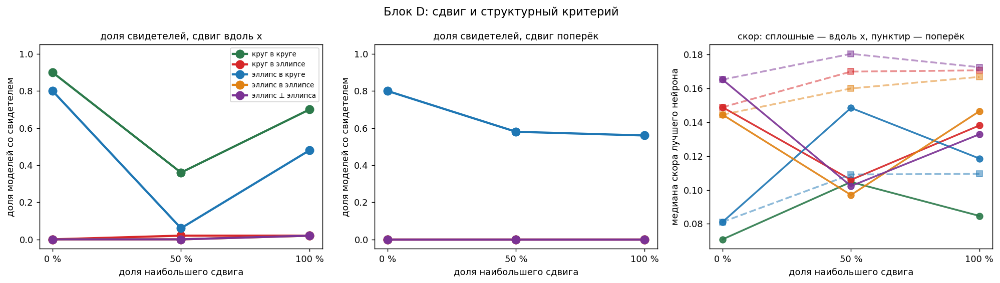

            пара ось доля  скор   пол  свид
    круг в круге   x  50% 0.085 0.107  0.70
    круг в круге   x 100% 0.105 0.096  0.36
  круг в эллипсе   x  50% 0.138 0.045  0.02
  круг в эллипсе   x 100% 0.106 0.043  0.02
  круг в эллипсе   y  50% 0.171 0.059  0.00
  круг в эллипсе   y 100% 0.170 0.058  0.00
  эллипс в круге   x  50% 0.119 0.111  0.48
  эллипс в круге   x 100% 0.148 0.108  0.06
  эллипс в круге   y  50% 0.110 0.122  0.56
  эллипс в круге   y 100% 0.109 0.117  0.58
эллипс в эллипсе   x  50% 0.146 0.050  0.02
эллипс в эллипсе   x 100% 0.097 0.048  0.00
эллипс в эллипсе   y  50% 0.167 0.058  0.00
эллипс в эллипсе   y 100% 0.160 0.056  0.00
эллипс ⊥ эллипса   x  50% 0.133 0.052  0.02
эллипс ⊥ эллипса   x 100% 0.102 0.038  0.00
эллипс ⊥ эллипса   y  50% 0.172 0.058  0.00
эллипс ⊥ эллипса   y 100% 0.180 0.059  0.00


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
for ax, axis, ttl in [(axes[0], "x", "доля свидетелей, сдвиг вдоль x"),
                      (axes[1], "y", "доля свидетелей, сдвиг поперёк")]:
    for fam in D_FAM:
        n0 = d_cell(fam, axis, "0%")
        g = DD[(DD.пара == fam) & (DD.ось == axis)].sort_values("доля")
        if not len(g):
            continue
        w0 = float(cells_meta.loc[n0, "rate_floor"])
        ax.plot([0, .5, 1.], [w0] + list(g.свид), "o-", color=FC[fam], lw=2.4, ms=9, label=fam)
    ax.set_xticks([0, .5, 1.], ["0 %", "50 %", "100 %"]); ax.set_ylim(-.05, 1.05)
    ax.set_xlabel("доля наибольшего сдвига"); ax.set_ylabel("доля моделей со свидетелем")
    ax.set_title(ttl, fontsize=10.5)
axes[0].legend(fontsize=7.5)

for fam in D_FAM:
    for axis, mk in (("x", "o-"), ("y", "s--")):
        n0 = d_cell(fam, axis, "0%")
        g = DD[(DD.пара == fam) & (DD.ось == axis)].sort_values("доля")
        if not len(g):
            continue
        s0 = float(cells_meta.loc[n0, "target_median"])
        axes[2].plot([0, .5, 1.], [s0] + list(g.скор), mk, color=FC[fam], lw=2.0, ms=7,
                     alpha=.9 if axis == "x" else .5)
axes[2].set_xticks([0, .5, 1.], ["0 %", "50 %", "100 %"])
axes[2].set_xlabel("доля наибольшего сдвига"); axes[2].set_ylabel("медиана скора лучшего нейрона")
axes[2].set_title("скор: сплошные — вдоль x, пунктир — поперёк", fontsize=10)
fig.suptitle("Блок D: сдвиг и структурный критерий", fontsize=12.5)
plt.tight_layout(); plt.show()

print(DD[["пара", "ось", "доля", "скор", "пол", "свид"]].round(3).to_string(index=False))


**Наблюдения.**

- **Там, где свидетели были, сдвиг их убивает.** Круглая пара: 0.90 → 0.70 → 0.36. «Эллипс в
  круге» вдоль x: 0.80 → 0.48 → 0.06. Фича при этом не менялась — двигалась только внутренность.
- **Поперёк убивает слабее**: у «эллипс в круге» 0.80 → 0.56 → 0.58, то есть почти не падает.
  Опять та же асимметрия: поперёк кривая за внутренностью не идёт, значит и от фичи не уходит.
- **Там, где свидетелей не было, сдвиг ничего не меняет** — три семейства с вытянутой фичей
  стоят на 0.00–0.02 при любом сдвиге.
- **Скор при этом ведёт себя противоположно в двух половинах.** У круглой фичи он ухудшается
  (0.071 → 0.105, 0.081 → 0.148), у вытянутой — **улучшается** (0.149 → 0.106, 0.144 → 0.097,
  0.165 → 0.102). Второе объяснимо: при сдвиге вдоль x кривая вытягивается и становится похожей
  на вытянутую фичу, то есть подходит к ней ближе. Но пол ячейки падает вместе со скором
  (0.057 → 0.043), поэтому доля свидетелей остаётся нулевой: приблизились не только кривые, но и
  нули.

**Вывод.** Сдвиг внутренности разрушает свидетельство ровно так же, как её поворот в блоке B, и
через тот же механизм: кривая уходит вслед за внутренностью и перестаёт совпадать с неизменной
фичей.


## 5.6 Итог блока D

1. **Кривая следует за уехавшей внутренностью настолько, насколько позволяет фича.** Вдоль
   длинной оси вытянутой фичи при половинном сдвиге центр кривой стоит в 0.31–0.40 от центра
   внутренности при разъезде центров на 2.5–2.6 — пройдено **85–88 %** пути; при максимальном
   сдвиге **56–60 %**; поперёк — **10–38 %** при любом сдвиге; у круглой фичи слабо в обе стороны
   (22–37 %). За внутренностью идёт всё семейство ступеней, а не отдельная кривая.
2. **Форма становится следствием положения.** Сдвиг вдоль оси фичи даёт самые вытянутые кривые
   всего эксперимента (до **7.06**), сдвиг поперёк — почти ничего (1.53–1.77). Кривая вытягивается
   **вдоль направления сдвига**, в том числе против формы обоих объектов: в «эллипс ⊥ эллипса»
   внутренность вытянута поперёк, а после сдвига вдоль x 0.99 кривых идут вдоль x.
3. **Подготовка блока сама по себе меняет картину.** Уменьшение внутренности вдвое при нулевом
   сдвиге переворачивает направление в двух семействах из пяти и вчетверо-пятнадцатикратно
   поднимает долю кривых с определённым направлением. Поэтому точкой отсчёта в блоке D служит его
   собственная нулевая ячейка, а не одноимённая ячейка блока A.
4. **Здесь единственное место эксперимента, где вытянутость вынуждена геометрией.**
   Концентрическая окружность перестаёт разделять в 6 ячейках из 56 — все они в блоке D, и ровно
   у них вытянутость 3.05–7.06 против 1.60 в остальных пятидесяти.
5. **Все три геометрические конструкции здесь проваливаются** (+0.15, +0.54, +0.61 по
   упорядоченности, ошибки 1.01–1.12 при неопределённости самих чисел **±0.21**; в крайней ячейке
   7.06 против 1.55). Причём лучшей
   неожиданно оказывается срединная линия — та самая, что хуже всех в блоке A: когда фича
   действительно упирается, следовать за ней становится правильным.
6. **Сдвиг разрушает свидетельство так же, как поворот в блоке B**: 0.90 → 0.36 и 0.80 → 0.06 при
   неизменной фиче. Скор при вытянутой фиче при этом улучшается, но вместе с ним падает и пол,
   так что доля свидетелей не растёт.
7. Как и везде, это утверждения о **согласии** величин: абляции нет, о причинах речи не идёт.


---


# 6. Синтез

Четыре блока мерили четыре разные величины и на разных сетках. Здесь они собираются вместе:
сначала что измерено, потом — что из этого складывается, потом — что не складывается.


## 6.1 Что измерено

| блок | главная величина | результат |
|---|---|---|
| **A** (16 ячеек) | вытянутость кривой | медиана по ячейкам **1.05–1.85** при объектах от 1 до 4; двигает её внутренность (предельный эффект 0.46, монотонно), а не фича (0.14, немонотонно) |
| **A** | доля прошедшей формы | через кривую проходит около **41 %** вытянутости внутренности; наблюдаемая форма лежит между окружностью и формой внутренности в 27 ячейках из 27 |
| **A** | распределение | не одна мода: выше вытянутости 2 живёт отдельная **популяция** (вес до 34 %), подтверждённая четырьмя независимыми проверками |
| **B** (16 ячеек) | направление большой оси | при круглой внутренности кривая идёт **вдоль фичи** (0.74–0.93); при круглой фиче — **вдоль внутренности** (0.93–0.99); когда оси объектов спорят, **внутренность выигрывает 9 раз из 9** (0.57–0.96 против 0.02–0.34) |
| **B** | парное сравнение | поворот внутренности при **побитово той же фиче** ухудшает скор в 9 парах из 9 и роняет долю свидетелей в 7 из 9 |
| **C** (12 ячеек) | вытянутость при неизменной геометрии | перенос точек с фичи внутрь двигает медиану **1.59 → 2.97**, сдвиг популяционный (92 % моделей) |
| **D** (23 ячейки) | положение центра кривой | вдоль длинной оси вытянутой фичи кривая проходит **85–88 %** пути к уехавшей внутренности при сдвиге на половину допустимого и **56–60 %** при сдвиге на весь допустимый; поперёк — **10–38 %** при любом сдвиге |
| **D** | вытянутость | сдвиг вдоль оси фичи даёт самые вытянутые кривые эксперимента (до **7.06**); кривая вытягивается **вдоль направления сдвига** |

Плюс два измерения, общих для всех блоков:

* **свидетельство разрушается при неизменной фиче** — дважды и двумя разными способами: поворотом
  внутренности (блок B) и её сдвигом (блок D);
* **круглая линия уровня разделяет классы в 50 ячейках из 56**, поэтому почти вся наблюдаемая
  вытянутость — выбор сети, а не необходимость. Шесть исключений — в блоке D.


## 6.2 Три величины оказались тремя разными вопросами

Начиная эксперимент, естественно было думать, что «форма линии уровня» — одна величина. Это
оказалось не так: **вытянутость, направление и положение ведут себя по-разному и отвечают на
разные вопросы**, и путать их нельзя.

* **Вытянутость** — самая инертная. Она сжата: кривая несёт лишь около 41 % вытянутости
  внутренности, а форма фичи двигает её слабо (предельный эффект 0.14 против 0.46). В блоке C её
  двигает даже то, что геометрией не является, — плотность точек.
* **Направление** — самая чистая. Оно не сжимается и не размывается: каждый объект по
  отдельности разворачивает кривую к себе почти нацело (0.74–0.93 вдоль фичи при круглой
  внутренности, 0.93–0.99 вдоль внутренности при круглой фиче), а когда оси спорят, ответ
  однозначен — внутренность. Именно направление дало единственное измерение всего эксперимента,
  где промах модели нельзя списать на калибровку: срединная линия зазора ошибается на **90°**
  девять раз из девяти.
* **Положение** — самая «послушная»: кривая идёт за внутренностью настолько, насколько ей
  позволяет фича, и это видно как непрерывная величина, а не как «да/нет».

Отсюда практическое следствие для программы: **структурный критерий видит только первую из трёх**.
Он меряет расстояние от кривой до фичи, то есть смешивает форму, размер и положение в одно число.
Всё, что мы узнали в блоках B и D, этим числом невидимо — и именно поэтому оно так резко падает,
когда пару разворачивают или растаскивают.


## 6.3 Сквозная закономерность

Все четыре блока укладываются в одно утверждение, и это то самое, что было названо в начале
ноутбука:

> **Фича задаёт границы возможного, а внутренность — то, что внутри этих границ выбирается.**

Разберём по частям, потому что каждая половина держится на своих измерениях.

**«Внутренность выбирает» — четыре независимых подтверждения.**

1. Форма кривой следует за формой внутренности сильнее, чем за формой фичи (блок A: предельные
   эффекты 0.46 против 0.14).
2. Когда оси объектов сталкиваются, направление кривой задаёт внутренность — во всех девяти
   ячейках (блок B).
3. Положение кривой следует за положением внутренности (блок D: 85–88 % пути при сдвиге на
   половину допустимого вдоль длинной оси вытянутой фичи).
4. Всё это разрушается, если тронуть **только** внутренность, оставив фичу побитово прежней
   (блоки B и D).

**«Фича задаёт границы» — три подтверждения, и все три «от противного».**

1. Пока круглая кривая разделяет классы, форма фичи не объясняет почти ничего: аспект срединной
   линии зазора, который послушно следует обоим объектам, даёт ранговую связь **+0.12** с
   наблюдаемым (блок A).
2. Как только фича начинает мешать — в шести ячейках блока D, где концентрическая окружность
   перестаёт разделять, — вытянутость подскакивает до **3.05–7.06** против 1.60 в остальных
   пятидесяти. Потолок молчит, пока не упрётся, и становится решающим, когда упрётся.
3. Следование за внутренностью ограничено **ровно тем, сколько места оставила фича**: вдоль её
   длинной оси кривая проходит 85–88 % пути при сдвиге на половину допустимого и 56–60 % при
   сдвиге на весь допустимый — чем плотнее внутренность прижата к концу фичи, тем труднее за ней
   успевать; поперёк, где места нет, — 10–38 % при любом сдвиге.

**Но «границы» не значит «молчание»: фича действует и внутри них.** Её голос слышен там, где
внутренность его не заглушает, — на краю сетки с круглой внутренностью. Там кривая вытягивается
вслед за фичей (медиана вытянутости **1.05** у пары «круг в круге» против **1.19–1.23**, как
только фичу вытягивают) и разворачивается вдоль неё (0.74–0.93 кривых). Правильная формулировка
поэтому не «фича не влияет», а **«влияние фичи слабее и проигрывает при прямом столкновении»**:
0.14 против 0.46 по вытянутости и 0.02–0.34 против 0.57–0.96 по направлению.

**Чего в этой формуле нет — и это тоже результат.** Кривая не является копией внутренности даже
там, где ничто не мешает: она систематически круглее (проходит 41 % вытянутости). Значит между
«внутренность выбирает» и «кривая есть внутренность» стоит ещё что-то — сглаживание, которое ни
одна из проверенных конструкций не воспроизводит количественно.


## 6.4 Что не сложилось

Четыре места, где эксперимент не даёт ответа, и все четыре стоит назвать явно.

**Ни одна геометрическая конструкция не описывает наблюдаемое целиком.** Проверено пять
(срединная линия зазора, кривая максимального зазора, равномерная мера на допустимых кривых,
раздутие внутренности, равновесный потенциал пары; подробности — в `exp5_shape_law.ipynb`).
Лучшая — потенциал, средняя ошибка 0.12 при неопределённости самих предсказываемых чисел ±0.09.
Но **обе половины
эффекта фичи не даёт ни одна**: подъём вытянутости при круглой внутренности воспроизводит только
потенциал, падение при вытянутой — только раздутие. А в блоке D проваливаются все три.

**Геометрии в принципе недостаточно.** Блок C показал, что при побитово одинаковой геометрии
форма меняется почти вдвое от того, как распределены точки. Значит правильная постановка — не
«форма как функция геометрии», а «форма как функция геометрии **и** данных», и второй аргумент
эксперимент не исследовал.

**«Свобода» осталась непроверенной.** Естественная гипотеза — что влияние внутренности тем
сильнее, чем меньше у кривой места, — не опровергнута, а **не проверена**: в этом дизайне все
меры свободы сцеплены с вытянутостью внутренности на +0.68…+0.79, потому что сетка вытягивает
внутренность при фиксированной большой полуоси. Нужна ось, меняющая **размер** внутренности при
неизменной **форме**.

**Два необъяснённых явления.** Диагональные направления в блоке C (при 800 точках внутри больше
половины кривых уходят под ≈45° в трёх геометриях из четырёх) и провал всех моделей в блоке D.


## 6.5 Что это делает с экспериментами 1 и 2

Эксперименты 1 и 2 измеряли в конфигурации, где фича и внутренность **обе круглые и
концентричные**. Теперь видно, чем эта точка особенная.

* Там «кривая следует за фичей» и «кривая следует за внутренностью» дают **одну и ту же
  картинку**, потому что у круглых концентричных объектов одна и та же форма, одно и то же
  положение и никакого направления. Различить гипотезы было нельзя не по недосмотру, а
  принципиально.
* Как только объекты разведены, побеждает внутренность — по форме, по направлению и по
  положению. Значит то, что в экспериментах 1 и 2 читалось как «нейрон свидетельствует
  окружность», в их конфигурации неотличимо от «нейрон обводит диск».
* И это не придирка: свидетельство удаётся **выключить при побитово неизменной фиче** —
  достаточно повернуть внутренность (доля свидетелей 0.92 → 0.58) или сдвинуть её (0.80 → 0.06).

**Защитимая формулировка после эксперимента 5.** Речь здесь идёт об одном инструменте —
**структурном** критерии, — и о нём можно сказать точно: он отвечает не про фичу саму по себе, а
про **зазор** между фичей и внутренностью, взятый целиком, как «бублик», а не как его внешняя
граница. Топологическая особенность входит в его ответ ровно постольку, поскольку она этот зазор
образует; в экспериментах 1 и 2 она образовывала его полностью — потому там всё и сходилось.
Какими именно характеристиками зазора определяется ответ — формами двух границ, их взаимным
положением, относительными размерами, плотностями точек на них, — эксперимент 5 не выясняет; он
показывает лишь, что одной внешней границы недостаточно.


---


# 7. Результаты и выводы

Итоговые утверждения. У каждого — числа, на которых оно держится, и граница, за которой оно
перестаёт быть верным.

## Главное

> **Разделяющая линия уровня нейрона выбирается внутренностью в границах, которые задаёт фича.**

Это единственное утверждение, которое подтверждается всеми четырьмя блоками, каждым — на своей
величине, и не опровергается ни одним.

## Установлено

**1. Форму линии уровня двигает внутренность сильнее, чем фича.** Предельный эффект вытянутости
внутренности на вытянутость кривой — **0.46** и монотонен; эффект фичи — **0.14** и не
монотонен (блок A, 16 ячеек, ~40 000 кривых).
*Граница:* это сравнение двух эффектов, а не утверждение, что фича не действует, — см. пункт 2.
Кроме того, ось «вытянутость фичи» не чистая: вдоль неё вчетверо растёт и площадь фичи, поэтому
часть её эффекта может быть эффектом относительного размера.

**2. Направление кривой задают оба объекта; при столкновении осей выигрывает внутренность.**
Каждый объект по отдельности разворачивает кривую к себе: при круглой внутренности она идёт
**вдоль фичи** в 0.74–0.93 случаев и вытягивается вслед за ней — медиана вытянутости поднимается
с **1.05** у пары «круг в круге» до **1.19–1.23**, как только фичу вытягивают; при круглой фиче
кривая идёт вдоль внутренности в 0.93–0.99. Когда же оси объектов развёрнуты друг относительно
друга, кривая идёт вдоль внутренности в **0.57–0.96** случаев против **0.02–0.34** вдоль фичи —
во всех девяти таких ячейках (блок B).
*Граница:* «выигрывает» сказано о прямом столкновении осей и ни о чём больше; там, где
внутренность кругла, эффект фичи виден чисто и он реален — просто по величине он мал (0.14
против 0.46 по вытянутости). Измерено на аспектах 1.5–4; при слабо вытянутой внутренности
разделение слабее всего (0.57 против 0.34).

**3. Положение линии уровня следует за положением внутренности настолько, насколько позволяет
фича.** Сдвиг всюду меряется долей от **наибольшего, который данная пара допускает**. Вдоль
длинной оси вытянутой фичи, где место есть, кривая проходит **85–88 %** пути к уехавшей
внутренности при сдвиге на половину допустимого и **56–60 %** — при сдвиге на весь допустимый:
чем плотнее внутренность прижата к концу фичи, тем труднее за ней успевать. Поперёк, где места
нет, кривая проходит **10–38 %** при любом сдвиге (блок D, 23 ячейки).
*Граница:* внутренность в блоке D вдвое меньше, и само это уменьшение — заметное вмешательство:
оно переворачивает направление в двух семействах из пяти.

**4. Свидетельство разрушается при зафиксированной фиче.** Поворот внутренности при побитово той
же фиче ухудшает скор в 9 парах из 9 и роняет долю свидетелей в 7 из 9 (0.92 → 0.58,
0.56 → 0.10); сдвиг внутренности даёт то же (0.90 → 0.36, 0.80 → 0.06).
*Граница:* «разрушается» здесь означает падение доли моделей со свидетелем, измеренной по
собственному полу каждой ячейки; это не утверждение о том, что происходит внутри сети.

**5. Кривая систематически круглее того, за чем следует.** Через неё проходит около **41 %**
вытянутости внутренности (медиана по концентричным ячейкам, размах 0.10–0.78), и наблюдаемая
форма лежит между окружностью и формой внутренности **в 27 ячейках из 27**.
*Граница:* доля 0.41 измерена, но не выведена ни из какой геометрической конструкции.

**6. Форма не является функцией одной геометрии.** При **побитово одинаковой** геометрии перенос
точек с фичи внутрь двигает медиану вытянутости **1.59 → 2.97**; сдвиг популяционный — 92 %
моделей (блок C, 12 ячеек).
*Граница:* сильный эффект наблюдается в одной геометрии из четырёх; в двух он вдвое слабее, в
одной отсутствует.

**7. Почти вся наблюдаемая вытянутость — выбор, а не необходимость.** Круглая линия уровня
разделяет классы в **50 ячейках из 56**. Шесть исключений — все в блоке D, все при сдвиге вдоль
длинной оси вытянутой фичи, и ровно у них вытянутость **3.05–7.06** против **1.60** у остальных
пятидесяти.
*Граница:* «разделяет» проверено для окружности с центром в центре фичи; со свободным центром
окружность существует во всех 56 ячейках.

**8. Лучшее геометрическое описание — равновесный потенциал пары**, средняя ошибка **0.12** по
вытянутости — при неопределённости самих предсказываемых чисел **±0.09** — и нуле подгоняемых
параметров формы. Пять
конструкций проверены и сравнены на одних данных (`exp5_shape_law.ipynb`).
*Граница:* обе половины эффекта фичи не воспроизводит ни одна конструкция, а в блоке D
проваливаются все.

## Что это значит для программы

**Структурный критерий отвечает про зазор, а не про фичу.** Оговорка о том, какой именно
инструмент имеется в виду, существенна: критериев в программе четыре, и здесь речь идёт только о
**структурном** — том, что меряет расстояние от линии уровня до фичи. Эксперимент 5 показывает,
что его ответ определяется не внешней границей пары, а **всем зазором между фичей и
внутренностью** — «бубликом» целиком. Топологическая особенность попадает в этот ответ ровно
постольку, поскольку она зазор образует: в экспериментах 1 и 2 она образовывала его полностью
(объекты круглые и концентричные), и потому их результаты остаются верными — но читать их как
«нейрон видит окружность» больше нельзя, в той конфигурации это неотличимо от «нейрон обводит
диск».

Формулировку «выравнивание с границей между классами» мы намеренно не используем: её легко
спутать с разделяющей поверхностью всей сети, `f(x) = 0.5`, — а речь о линиях уровня отдельных
нейронов, и стоят они по всему зазору, а не на одной поверхности.

**Какими характеристиками зазора определяется ответ — не установлено.** Кандидаты, каждый из
которых эксперимент 5 задевает, но ни один не изолирует: формы двух границ (блоки A и B),
взаимное положение границ (блок D), их относительные размеры (не проверено, см. открытые
вопросы), плотности точек на границах (блок C — плотность входит точно). Установлено только, что
одной внешней границы недостаточно.

**Свидетельство — свойство пары.** Это показано дважды и двумя разными способами: одну и ту же
окружность можно сделать засвидетельствованной или нет, повернув (блок B) или сдвинув (блок D)
множество противоположного класса внутри неё.

**Абляции здесь нет**, поэтому всё сказанное — о **согласии** измеряемых величин. Ни одно
утверждение выше не говорит, что нейрон что-либо «кодирует» или «вычисляет».

## Что осталось открытым

1. **Ни одна конструкция не описывает наблюдаемое целиком** — ни в блоке A (обе половины эффекта
   фичи), ни тем более в блоке D.
2. **Роль относительного размера не проверена.** Гипотеза «влияние внутренности тем сильнее, чем
   меньше свободы» не опровергнута, а непроверяема на этой сетке: все меры свободы сцеплены с
   вытянутостью внутренности на +0.68…+0.79. Нужна ось `interior_scale` при неизменной форме —
   четыре-пять ячеек на одну форму пары.
3. **Диагональные направления в блоке C**: при 800 точках внутри больше половины кривых уходят
   под ≈45° в трёх геометриях из четырёх, включая ту, где оба объекта вытянуты вдоль одной оси.
4. **Вторая половина функции — данные.** Блок C показал, что форма зависит и от распределения
   точек; как именно — эксперимент не исследовал.
